# Estado del Arte: Marco Teórico y Bibliografía

## Justificación académica de la hibridación entre Econometría y Machine Learning

La metodología aplicada en este trabajo de fin de máster se encuadra dentro de lo que la literatura académica contemporánea denomina modelos híbridos de predicción (*Hybrid Forecasting Models*). Esta corriente representa la vanguardia en el análisis de series temporales, fundamentando la validez de combinar el rigor estructural y causal de la econometría clásica con la flexibilidad y capacidad predictiva del aprendizaje automático.

---

## Fuentes fundamentales de la investigación

Para el desarrollo del marco teórico, he tomado como referencia tres pilares bibliográficos y empíricos que validan el enfoque metodológico de la presente investigación:

### Las competiciones M de Makridakis y la superioridad de los modelos híbridos

Los resultados de la **M4 Competition (2018)**, organizada por Spyros Makridakis, constituyen la evidencia empírica principal que sustenta este trabajo. En dicho certamen se demostró que los modelos que combinan estadística tradicional con algoritmos de Machine Learning minimizan el error de predicción de forma más eficiente que cualquier método aplicado de forma aislada.



Basándome en estos hallazgos, sostengo en esta investigación que la combinación de métodos estadísticos clásicos, útiles para capturar la tendencia y la estacionalidad, con algoritmos de Machine Learning, capaces de procesar no linealidades, permite reducir el error en la previsión del mercado hipotecario español mejor que cualquier método convencional de manera independiente.

### La integración de nuevas técnicas según Hal Varian

Una referencia fundamental en este estudio es el trabajo de **Varian (2014), *Big Data: New Tricks for Econometrics***. El autor expone que las herramientas tradicionales de la econometría son necesarias para establecer causalidad y equilibrio mediante técnicas como la cointegración, pero que el Machine Learning ofrece una potencia superior en la selección de variables e identificación de patrones en entornos con múltiples predictores.



Siguiendo la tesis de Varian, utilizo el algoritmo Random Forest no con el fin de sustituir la teoría económica subyacente, sino para potenciar la captura de relaciones complejas que un modelo VAR lineal, por su propia naturaleza restrictiva, no es capaz de detectar en su totalidad.

### La adopción institucional de la Inteligencia Artificial explicable (XAI)

La adopción de estas técnicas por parte de instituciones como el Banco de Inglaterra y el Banco Central Europeo refuerza la base de este trabajo. En particular, tomo como referencia el trabajo de **Chakraborty y Joseph (2017), *Machine Learning at Central Banks***, publicado por el Banco de Inglaterra.



Estas instituciones abogan por el uso de modelos híbridos acompañados de técnicas de interpretabilidad como los valores SHAP (*Shapley Additive Explanations*). En esta investigación, implemento dicha metodología para transformar la denominada "caja negra" del Machine Learning en un modelo transparente y auditable, alineado con las exigencias actuales de la supervisión macroeconómica y la rendición de cuentas estadística.

---

## Síntesis del Estado de la Cuestión

La siguiente tabla resume el posicionamiento de mi investigación frente a la literatura existente y justifica la elección metodológica final:

| Bloque Metodológico | Referencias Base | Aportación a este Trabajo |
| :--- | :--- | :--- |
| **Modelos Clásicos** | VAR / VECM | Se consideran fundamentales para asegurar la coherencia económica y el equilibrio a largo plazo de las variables mediante el test de cointegración de Johansen. |
| **Modelos de Aprendizaje** | Random Forest / XGBoost | Se utilizan por su alta precisión predictiva en datos heterogéneos, asumiendo inicialmente su limitación en cuanto a estructura teórica explícita. |
| **Enfoque Híbrido** | Makridakis (2018) y Varian (2014) | Representa la síntesis final de este TFM: uso de cointegración para la estabilidad del modelo y Random Forest con valores SHAP para maximizar la precisión explicativa. |

---

En conclusión, la hibridación metodológica presentada no es una elección arbitraria, sino una respuesta técnica a la evolución de la ciencia económica actual. Sitúa este análisis en la misma línea de investigación que proponen los principales organismos bancarios y académicos internacionales, buscando un equilibrio entre la capacidad de acierto y la interpretabilidad de los resultados obtenidos.

# Análisis Predictivo del Mercado Hipotecario Español
**TFM — Ciencia de Datos Aplicada al Sector Inmobiliario**

Este notebook realiza el análisis completo del mercado hipotecario español mediante:
- Corrección de **data leakage** mediante lags temporales
- Modelos de **Machine Learning** (Random Forest, XGBoost)
- Modelos de **Series Temporales** (SARIMAX, VAR, Cointegración de Johansen)
- **Mapas geoespaciales** de accesibilidad y tensión del mercado

## 1. Importaciones y Configuración
Cargamos todas las librerías necesarias para el análisis.

In [2]:
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import geopandas as gpd
import unicodedata
from difflib import get_close_matches
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_percentage_error

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error, r2_score, mean_absolute_error
import xgboost as xgb
import lightgbm as lgb
import matplotlib.ticker as mtick
COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}


## 2. Carga del Dataset
Cargamos el dataset principal `dataset_final_tfm.csv` con estructura de panel temporal (52 provincias × trimestres desde 2005).

In [3]:
df = pd.read_csv('dataset_final_tfm.csv')
df.tail()
df_raw = df.copy()  # backup para feature engineering


## 3. ADVERTENCIA: Corrección de Data Leakage — Creación de Lags Temporales

> ADVERTENCIA: `dataset_final_tfm.csv` tiene estructura de panel temporal (52 provincias × trimestres). Las siguientes columnas tienen **data leakage** porque son contemporáneas al target `Hipotecas_Total` — es decir, en producción no las conocerías en el momento de predecir: `Precio_m2`, `Transmisiones_Total`, `Spread_Hipotecas`, `Tasa_Paro`, `IPC`, `Indice_Mano_Obra`, `Indice_Materiales`. Creando lags ahora mismo...

**Solución:** Se crean columnas `_lag1` (trimestre anterior) y `_lag4` (año anterior) para todas las variables problemáticas, agrupando por provincia.

In [4]:
# Continúa con df ya cargado en la celda anterior
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
# Continúa con df ya cargado en la celda anterior
df_raw = df.copy()  # backup
df = df_raw.copy()

# Rellenar valores nulos iniciales de las series económicas (como en analisis_definitivo)
df = df.sort_values(['Provincia','Trimestre']).reset_index(drop=True)
for c in ['tasa_ahorro','Indice_Mano_Obra','Indice_Materiales','IPC','PIB_pc','Transmisiones_Total','Pob_Ext']:
    if c in df.columns:
        df[c]=df.groupby('Provincia')[c].transform(lambda x:x.ffill().bfill())
lag_cols=['Precio_m2','Transmisiones_Total','Spread_Hipotecas','Tasa_Paro','IPC',
'Indice_Mano_Obra','Indice_Materiales','Hipotecas_Total','Pob_Ext','Poblacion','PIB_pc','tasa_ahorro','Edad_Media']
for col in lag_cols:
    if col in df.columns:
        df[f'{col}_lag1']=df.groupby('Provincia')[col].shift(1)
        df[f'{col}_lag2']=df.groupby('Provincia')[col].shift(2)
        df[f'{col}_lag4']=df.groupby('Provincia')[col].shift(4)

# Rolling statistics (ventana 4Q, sobre shift(1) para evitar leakage)
for col in ['Hipotecas_Total','Precio_m2','Transmisiones_Total','Tasa_Paro','PIB_pc']:
    s=df.groupby('Provincia')[col].shift(1)
    df[f'{col}_rmean4']=s.rolling(4,min_periods=2).mean()
    df[f'{col}_rstd4']=s.rolling(4,min_periods=2).std()
    df[f'{col}_rmin4']=s.rolling(4,min_periods=2).min()
    df[f'{col}_rmax4']=s.rolling(4,min_periods=2).max()

# YoY usando lag1 vs lag5 para evitar data leakage
for col in ['Hipotecas_Total','Precio_m2','Transmisiones_Total','PIB_pc']:
    lag1=df.groupby('Provincia')[col].shift(1)
    lag5=df.groupby('Provincia')[col].shift(5)
    df[f'{col}_yoy']=(lag1-lag5)/lag5.abs().clip(lower=1)

# Diferencias (momentum)
for col in ['Hipotecas_Total','Precio_m2','Tasa_Paro','Euribor']:
    if col in df.columns:
        df[f'{col}_diff1']=df.groupby('Provincia')[col].shift(1).diff()
        df[f'{col}_diff4']=df.groupby('Provincia')[col].shift(1).diff(4)

# Euribor features
df['Euribor_ma4']=df.groupby('Provincia')['Euribor'].transform(lambda x:x.shift(1).rolling(4).mean())
df['Euribor_lag1']=df.groupby('Provincia')['Euribor'].shift(1)
df['Euribor_lag2']=df.groupby('Provincia')['Euribor'].shift(2)
df['Euribor_change']=df['Euribor']-df['Euribor_lag1']

# Interacciones (solo con lags, sin leakage)
df['Euribor_x_Precio']=df['Euribor']*df['Precio_m2_lag1']
df['Accesibilidad']=(df['PIB_pc_lag1']*(1-df['Tasa_Paro_lag1']/100))/df['Precio_m2_lag1'].clip(lower=1)
df['Hip_per_cap']=df['Hipotecas_Total_lag1']/df['Poblacion_lag1'].clip(lower=1)
df['Pob_Ext_ratio']=df['Pob_Ext_lag1']/df['Poblacion_lag1'].clip(lower=1)
df['Precio_x_Paro']=df['Precio_m2_lag1']*df['Tasa_Paro_lag1']
df['Spread_x_Euribor']=df['Spread_Hipotecas_lag1']*df['Euribor']
df['Trans_per_cap']=df['Transmisiones_Total_lag1']/df['Poblacion_lag1'].clip(lower=1)
df['Hip_trans_ratio']=df['Hipotecas_Total_lag1']/(df['Transmisiones_Total_lag1'].clip(lower=1))

# Ratios temporales
df['Hip_lag1_vs_rmean']=df['Hipotecas_Total_lag1']/df['Hipotecas_Total_rmean4'].clip(lower=1)
df['Precio_lag1_vs_rmean']=df['Precio_m2_lag1']/df['Precio_m2_rmean4'].clip(lower=1)

# Variables temporales
df['Q']=df['Trimestre'].dt.quarter
df['Year']=df['Trimestre'].dt.year
df['Trend']=df.groupby('Provincia').cumcount()

# Dummies trimestrales (estacionalidad)
for q in [1,2,3,4]:
    df[f'Q{q}']=( df['Q']==q).astype(int)

# Encoding provincial
le=LabelEncoder()
df['Prov_code']=le.fit_transform(df['Provincia'])

df=df.replace([np.inf,-np.inf],np.nan).dropna().reset_index(drop=True)
print(f"✅ Features: {df.shape[1]} cols, {df.shape[0]} rows")

✅ Features: 109 cols, 4108 rows


/var/folders/pq/jvlxhvnn4xb2whw_2kjk6tv40000gn/T/ipykernel_14990/2319429910.py:67: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'Q{q}']=( df['Q']==q).astype(int)
/var/folders/pq/jvlxhvnn4xb2whw_2kjk6tv40000gn/T/ipykernel_14990/2319429910.py:67: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'Q{q}']=( df['Q']==q).astype(int)
/var/folders/pq/jvlxhvnn4xb2whw_2kjk6tv40000gn/T/ipykernel_14990/2319429910.py:67: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

## 4. Analisis Exploratorio — Mapas Geoespaciales

### 4.1 Mapa de Tensión del Mercado Inmobiliario
Visualizamos el precio del m² por provincia en el último trimestre disponible como indicador de tensión del mercado.

✅ Todas las provincias tienen datos.


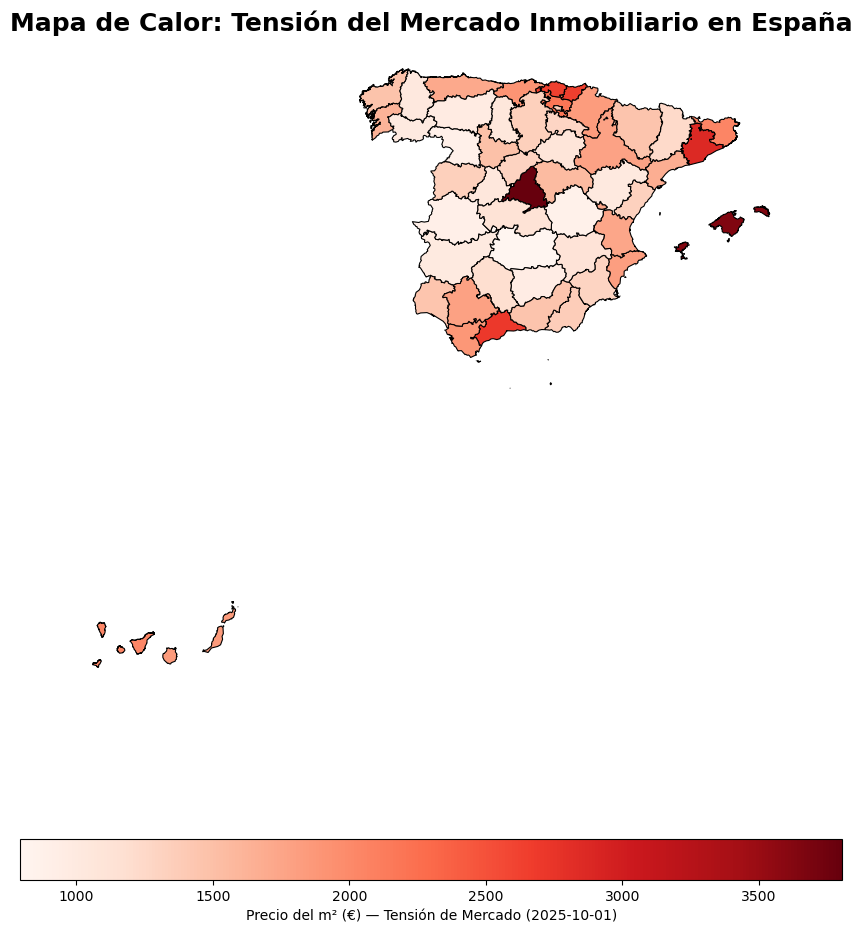

In [5]:
# Usamos df (ya tiene las últimas observaciones con lags)
df_mapa = df.copy()

def clean_text_map(text):
    if pd.isna(text): return ""
    import unicodedata
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

# Extraer el último trimestre disponible
ultimo_trimestre = df_mapa['Trimestre'].max()
df_reciente = df_mapa[df_mapa['Trimestre'] == ultimo_trimestre].copy()
df_reciente['Prov_clean'] = df_reciente['Provincia'].apply(clean_text_map)
df_reciente['Tension'] = df_reciente['Precio_m2']

# Cargar GeoJSON
url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text_map)

diccionario_mapa = {
    'illes balears': 'islas baleares',
    'alacant/alicante': 'alicante',
    'castello/castellon': 'castellon',
    'valencia/valencia': 'valencia',
    'araba/alava': 'alava',
    'bizkaia/vizcaya': 'vizcaya',
    'gipuzkoa/guipuzcoa': 'guipuzcoa',
    'madrid': 'comunidad de madrid',
    'murcia': 'region de murcia',
    'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra',
    'la coruna': 'a coruna',
    'las palmas': 'las palmas',
    'santa cruz de tenerife': 'santa cruz de tenerife'
}
gdf['name_clean'] = gdf['name_clean'].replace(diccionario_mapa)
merged = gdf.merge(df_reciente, left_on='name_clean', right_on='Prov_clean', how='left')

# Diagnóstico rápido
sin_datos = merged[merged['Tension'].isna()]['name'].tolist()
if sin_datos:
    print(f"⚠️ Provincias sin datos: {sin_datos}")
else:
    print("✅ Todas las provincias tienen datos.")

fig, ax = plt.subplots(1, 1, figsize=(14, 10))
merged.plot(column='Tension', cmap='Reds', linewidth=0.8, ax=ax, edgecolor='black',
            legend=True,
            legend_kwds={'label': f"Precio del m² (€) — Tensión de Mercado ({ultimo_trimestre.date()})",
                         'shrink': 0.6, 'orientation': 'horizontal'},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title("Mapa de Calor: Tensión del Mercado Inmobiliario en España", fontsize=18, fontweight='bold')
plt.axis('off')
plt.tight_layout()
# plt.savefig('mapa_calor_espana.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

### 4.2 Mapa de Accesibilidad Hipotecaria
Calculamos el **Índice de Accesibilidad** = (PIB per cápita × tasa de empleo) / precio m², un indicador de cuán fácil es comprar vivienda en cada provincia.

✅ Todas las provincias tienen datos.


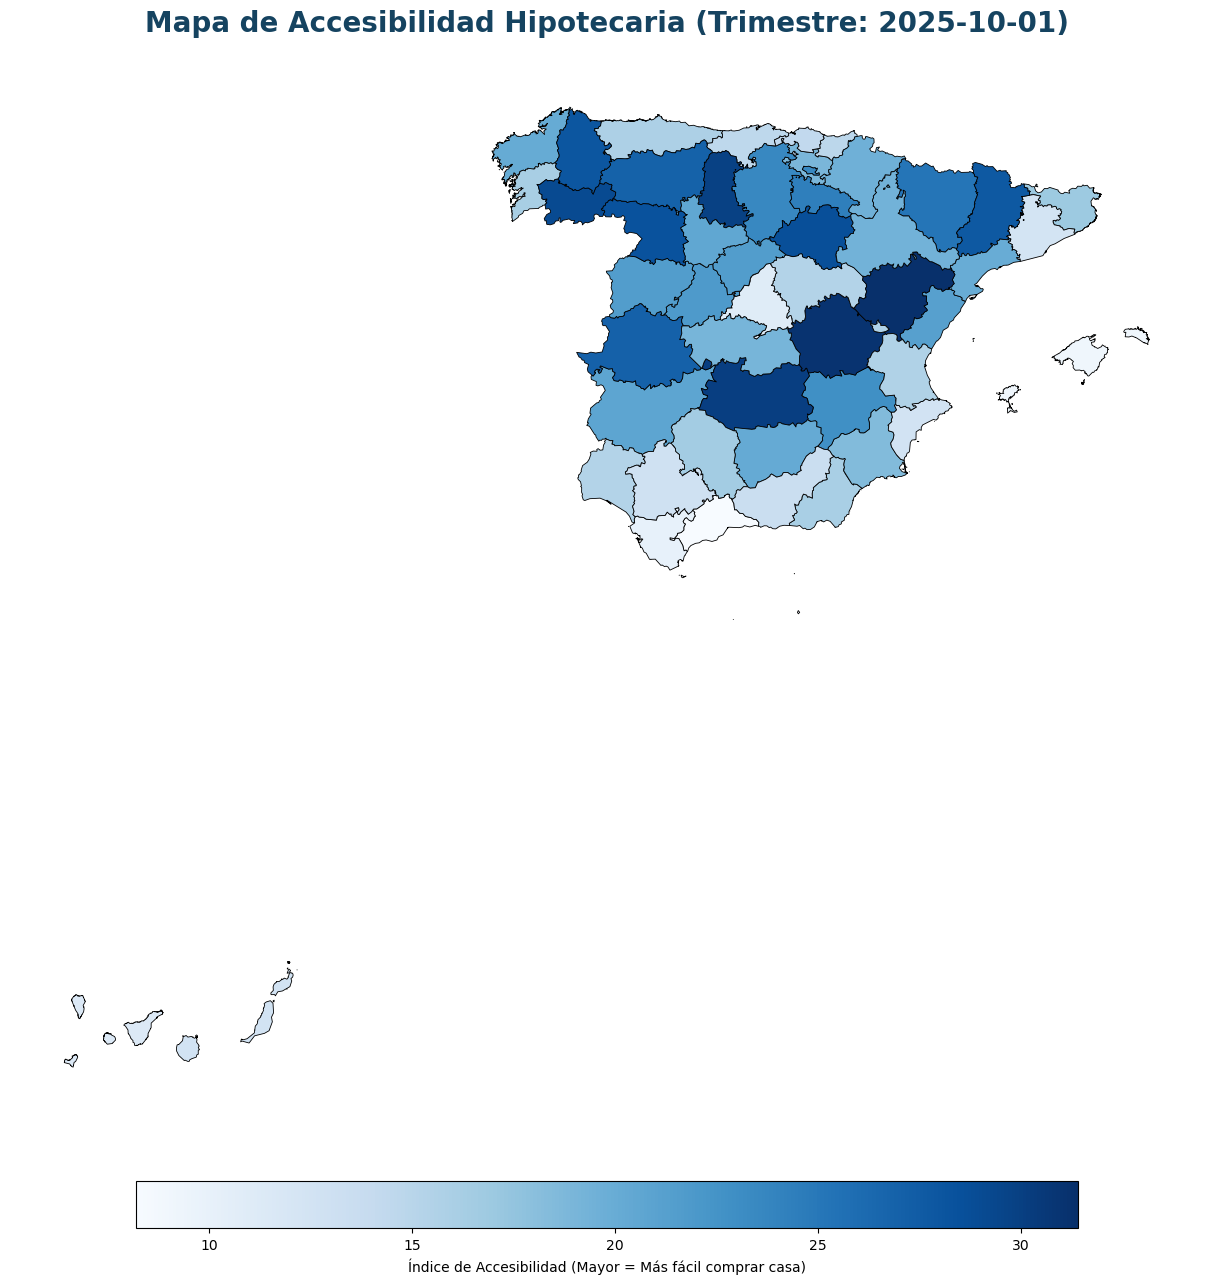

✅ Mapa renderizado y guardado.


In [6]:
# Mapa de Accesibilidad usando df (sin leakage en modelos)
def clean_text(text):
    if pd.isna(text): return ""
    import unicodedata
    s = str(text).lower().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')

df = df.copy()
cols_to_fill = ['PIB_pc', 'Tasa_Paro', 'Precio_m2']
for c in cols_to_fill:
    if c in df.columns:
        df[c] = df.groupby('Provincia')[c].ffill().bfill()

# Índice de accesibilidad (ratio descriptivo, no feature de modelo)
df['Accesibilidad'] = (df['PIB_pc'] * (1 - df['Tasa_Paro']/100)) / df['Precio_m2']

ultimo_trimestre = df['Trimestre'].max()
df_map = df[df['Trimestre'] == ultimo_trimestre].copy()
df_map['Provincia_Clean'] = df_map['Provincia'].apply(clean_text)

url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson"
gdf = gpd.read_file(url_geojson)
gdf['name_clean'] = gdf['name'].apply(clean_text)

diccionario_mapa = {
    'illes balears': 'islas baleares',
    'alacant/alicante': 'alicante',
    'castello/castellon': 'castellon',
    'valencia/valencia': 'valencia',
    'araba/alava': 'alava',
    'bizkaia/vizcaya': 'vizcaya',
    'gipuzkoa/guipuzcoa': 'guipuzcoa',
    'madrid': 'comunidad de madrid',
    'murcia': 'region de murcia',
    'asturias': 'principado de asturias',
    'navarra': 'comunidad foral de navarra',
    'la coruna': 'a coruna',
    'las palmas': 'las palmas',
    'santa cruz de tenerife': 'santa cruz de tenerife'
}
gdf['name_clean'] = gdf['name_clean'].replace(diccionario_mapa)
merged = gdf.merge(df_map, left_on='name_clean', right_on='Provincia_Clean', how='left')

sin_datos = merged[merged['Accesibilidad'].isna()]['name'].tolist()
if sin_datos:
    print(f"⚠️ Provincias sin datos: {sin_datos}")
else:
    print("✅ Todas las provincias tienen datos.")

fig, ax = plt.subplots(1, 1, figsize=(16, 14))
ax.set_facecolor('white')
ax.axis('off')
merged.plot(column='Accesibilidad', cmap='Blues', linewidth=0.6, ax=ax, edgecolor='black',
            legend=True,
            legend_kwds={'label': "Índice de Accesibilidad (Mayor = Más fácil comprar casa)",
                         'orientation': "horizontal", 'shrink': 0.6, 'pad': 0.05},
            missing_kwds={'color': 'lightgrey', "hatch": "///", "label": "Sin datos"})
plt.title(f"Mapa de Accesibilidad Hipotecaria (Trimestre: {ultimo_trimestre.date()})",
          fontsize=20, fontweight='bold', color='#154360', pad=20)
plt.tight_layout()
# plt.savefig('mapa_accesibilidad_azul.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()
print("✅ Mapa renderizado y guardado.")

## 3. Train/Test Split Temporal

In [7]:
# Features para ML — TODAS con lag para evitar data leakage
# Euribor sin lag porque se publica en tiempo real (ECB)
candidate_features = [c for c in df.columns if c not in 
    ['Provincia','Trimestre','Hipotecas_Total'] + 
    [c for c in df.columns if not c.endswith(('_lag1','_lag2','_lag4','_rmean4','_rstd4',
     '_rmin4','_rmax4','_yoy','_diff1','_diff4','_ma4','_change',
     '_x_Precio','_x_Euribor','_x_Paro')) 
     and c not in ['Euribor','Accesibilidad','Hip_per_cap','Pob_Ext_ratio',
                    'Trans_per_cap','Hip_trans_ratio','Hip_lag1_vs_rmean',
                    'Precio_lag1_vs_rmean','Precio_x_Paro','Spread_x_Euribor',
                    'Q','Q1','Q2','Q3','Q4','Year','Trend','Prov_code']]]

# Safer approach: explicitly list safe features
features_ml = [c for c in df.columns if any([
    c.endswith('_lag1'), c.endswith('_lag2'), c.endswith('_lag4'),
    c.endswith('_rmean4'), c.endswith('_rstd4'), c.endswith('_rmin4'), c.endswith('_rmax4'),
    c.endswith('_yoy'), c.endswith('_diff1'), c.endswith('_diff4'),
    c in ['Euribor','Euribor_ma4','Euribor_change',
           'Euribor_x_Precio','Accesibilidad','Hip_per_cap','Pob_Ext_ratio',
           'Precio_x_Paro','Spread_x_Euribor','Trans_per_cap','Hip_trans_ratio',
           'Hip_lag1_vs_rmean','Precio_lag1_vs_rmean',
           'Q','Q1','Q2','Q3','Q4','Year','Trend','Prov_code']
])]
# Remove target leakage check
assert 'Hipotecas_Total' not in features_ml, "LEAKAGE: target in features!"
for f in features_ml:
    if f in ['Precio_m2','Transmisiones_Total','Spread_Hipotecas','Tasa_Paro','IPC',
             'Indice_Mano_Obra','Indice_Materiales','Pob_Ext','Poblacion','PIB_pc',
             'tasa_ahorro','Edad_Media']:
        raise ValueError(f"LEAKAGE: raw contemporaneous variable '{f}' in features!")
print(f"Features ML (sin leakage): {len(features_ml)}")
print(features_ml[:10], "...")

trimestres=sorted(df['Trimestre'].unique())
test_start=trimestres[-8]
df_train=df[df['Trimestre']<test_start].copy()
df_test=df[df['Trimestre']>=test_start].copy()
X_tr,y_tr=df_train[features_ml],df_train['Hipotecas_Total']
X_te,y_te=df_test[features_ml],df_test['Hipotecas_Total']
print(f"Train:{X_tr.shape} Test:{X_te.shape}")
print(f"Train: {df_train['Trimestre'].min()}→{df_train['Trimestre'].max()}")
print(f"Test:  {df_test['Trimestre'].min()}→{df_test['Trimestre'].max()}")

Features ML (sin leakage): 94
['Euribor', 'Precio_m2_lag1', 'Precio_m2_lag2', 'Precio_m2_lag4', 'Transmisiones_Total_lag1', 'Transmisiones_Total_lag2', 'Transmisiones_Total_lag4', 'Spread_Hipotecas_lag1', 'Spread_Hipotecas_lag2', 'Spread_Hipotecas_lag4'] ...
Train:(3692, 94) Test:(416, 94)
Train: 2006-04-01 00:00:00→2023-10-01 00:00:00
Test:  2024-01-01 00:00:00→2025-10-01 00:00:00


## 4. Benchmark Provincial — Entrenamiento de 6 Modelos

In [8]:
# ── 4.1 Entrenar todos los modelos ──
models = {}

# Random Forest
models['RF'] = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=5,
    max_features='sqrt', random_state=42, n_jobs=-1)

# XGBoost
models['XGB'] = xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, verbosity=0)

# LightGBM
models['LGBM'] = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, max_depth=7,
    num_leaves=31, subsample=0.8, colsample_bytree=0.7, reg_alpha=0.1,
    reg_lambda=1.0, random_state=42, verbose=-1)

    #l2_leaf_reg=3, random_seed=42, verbose=0)

# GBM sklearn
models['GBM'] = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
    max_depth=5, subsample=0.8, random_state=42)

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_te_sc = scaler.transform(X_te)

results = {}
for name, model in models.items():
    print(f"Entrenando {name}...")
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    results[name] = {'model':model, 'pred':pred}
    mape = mean_absolute_percentage_error(y_te, pred)*100
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    r2 = r2_score(y_te, pred)
    print(f"  MAPE={mape:.2f}% | RMSE={rmse:.0f} | R²={r2:.4f}")

# ElasticNet (necesita datos escalados)
print("Entrenando ElasticNet...")
model_en = ElasticNetCV(l1_ratio=[0.1,0.5,0.7,0.9,0.99], cv=5, random_state=42, max_iter=5000)
model_en.fit(X_tr_sc, y_tr)
pred_en = model_en.predict(X_te_sc)
results['ElasticNet'] = {'model':model_en, 'pred':pred_en}
mape = mean_absolute_percentage_error(y_te, pred_en)*100
rmse = np.sqrt(mean_squared_error(y_te, pred_en))
r2 = r2_score(y_te, pred_en)
print(f"  MAPE={mape:.2f}% | RMSE={rmse:.0f} | R²={r2:.4f}")
print("\n✅ Todos los modelos entrenados")

Entrenando RF...
  MAPE=16.75% | RMSE=793 | R²=0.9603
Entrenando XGB...
  MAPE=19.87% | RMSE=1169 | R²=0.9138
Entrenando LGBM...
  MAPE=20.22% | RMSE=987 | R²=0.9386
Entrenando GBM...
  MAPE=21.51% | RMSE=1344 | R²=0.8862
Entrenando ElasticNet...
  MAPE=49.21% | RMSE=1027 | R²=0.9336

✅ Todos los modelos entrenados


/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:179: RuntimeWarning: divide by zero encountered in matmul
  Xyw = X.T @ yw - X_mean * np.sum(yw, axis=0)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:179: RuntimeWarning: overflow encountered in matmul
  Xyw = X.T @ yw - X_mean * np.sum(yw, axis=0)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:179: RuntimeWarning: invalid value encountered in matmul
  Xyw = X.T @ yw - X_mean * np.sum(yw, axis=0)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_base.py:293: RuntimeWarning: overflow encountered in matmul
  r

## 5. SARIMAX — Modelo de Series Temporales Nacional

In [9]:
# Agregar a nivel nacional para SARIMAX
df_nac = df.groupby('Trimestre').agg({
    'Hipotecas_Total':'sum','Euribor':'mean',
    'Spread_Hipotecas_lag1':'mean','Tasa_Paro_lag1':'mean',
    'PIB_pc_lag1':'mean','Precio_m2_lag1':'mean'
}).sort_index()
df_nac.index.freq = pd.infer_freq(df_nac.index)

y_log = np.log(df_nac['Hipotecas_Total'])
exog_cols = ['Euribor','Spread_Hipotecas_lag1','Tasa_Paro_lag1']
X_exog = df_nac[exog_cols]

n_test = 8
y_tr_s, y_te_s = y_log.iloc[:-n_test], y_log.iloc[-n_test:]
X_tr_s, X_te_s = X_exog.iloc[:-n_test], X_exog.iloc[-n_test:]

mod = sm.tsa.statespace.SARIMAX(endog=y_tr_s, exog=X_tr_s,
    order=(1,1,1), seasonal_order=(1,0,0,4),
    enforce_stationarity=False, enforce_invertibility=False)
res_s = mod.fit(disp=False)

pred_log = res_s.get_forecast(steps=n_test, exog=X_te_s).predicted_mean
sarimax_pred_nac = np.exp(pred_log)
sarimax_real_nac = np.exp(y_te_s)

mape_s = mean_absolute_percentage_error(sarimax_real_nac, sarimax_pred_nac)*100
rmse_s = np.sqrt(mean_squared_error(sarimax_real_nac, sarimax_pred_nac))
r2_s = r2_score(sarimax_real_nac, sarimax_pred_nac)
print(f"SARIMAX Nacional: MAPE={mape_s:.2f}% | RMSE={rmse_s:.0f} | R²={r2_s:.4f}")
results['SARIMAX'] = {'pred_nac': sarimax_pred_nac, 'real_nac': sarimax_real_nac}

SARIMAX Nacional: MAPE=16.57% | RMSE=28246 | R²=-2.0597


## 5b. Modelos ML Nacionales Dedicados

**Problema**: Sumar 52 predicciones provinciales acumula errores → mal MAPE nacional.

**Solución**: Entrenar modelos ML directamente sobre datos **agregados nacionales** con feature engineering rico. Así el modelo aprende la dinámica nacional directamente, no como suma de partes.

In [10]:
# ── Preparar dataset NACIONAL con MEDIAS PONDERADAS por población ──
# Corrección clave: usar media ponderada, no simple, para que Madrid/Barcelona
# pesen más que Soria/Teruel (refleja la realidad nacional)

# Variables que deben ponderarse por población
vars_to_weight = {
    'Precio_m2_lag1':'mean', 'Precio_m2_lag2':'mean', 'Precio_m2_lag4':'mean',
    'Tasa_Paro_lag1':'mean', 'Tasa_Paro_lag4':'mean',
    'IPC_lag1':'mean', 'PIB_pc_lag1':'mean', 'PIB_pc_lag4':'mean',
    'Indice_Mano_Obra_lag1':'mean', 'Indice_Materiales_lag1':'mean',
    'tasa_ahorro_lag1':'mean', 'Edad_Media_lag1':'mean',
    'Spread_Hipotecas_lag1':'mean', 'Spread_Hipotecas_lag2':'mean',
    'Precio_m2_rmean4':'mean', 'Tasa_Paro_rmean4':'mean',
    'Precio_m2_yoy':'mean', 'PIB_pc_yoy':'mean',
    'Precio_m2_diff1':'mean', 'Tasa_Paro_diff1':'mean',
    'Accesibilidad':'mean',
}
# Variables que deben sumarse (cantidades absolutas)
vars_to_sum = {
    'Hipotecas_Total':'sum',
    'Transmisiones_Total_lag1':'sum', 'Transmisiones_Total_lag4':'sum',
    'Hipotecas_Total_lag1':'sum', 'Hipotecas_Total_lag4':'sum',
    'Pob_Ext_lag1':'sum', 'Poblacion_lag1':'sum',
    'Hipotecas_Total_rmean4':'sum', 'Transmisiones_Total_rmean4':'sum',
    'Hipotecas_Total_yoy':'mean', 'Transmisiones_Total_yoy':'mean',
    'Hipotecas_Total_diff1':'sum',
}

# Calcular medias ponderadas por población
df_temp = df.copy()
peso = df_temp['Poblacion_lag1'].fillna(1)

for var in vars_to_weight:
    if var in df_temp.columns:
        df_temp[f'{var}_pond'] = df_temp[var] * peso

agg_dict = {}
for var in vars_to_weight:
    if f'{var}_pond' in df_temp.columns:
        agg_dict[f'{var}_pond'] = 'sum'
agg_dict['Poblacion_lag1_peso'] = ('Poblacion_lag1', 'sum')

# Build aggregation manually
pond_cols = {v: f'{v}_pond' for v in vars_to_weight if f'{v}_pond' in df_temp.columns}
sum_agg = {v: 'sum' for v in vars_to_sum if v in df_temp.columns}
pond_agg = {f'{v}_pond': 'sum' for v in vars_to_weight if f'{v}_pond' in df_temp.columns}
pond_agg['Poblacion_lag1'] = 'sum'  # for denominator

# Contemporáneas
extra_agg = {'Euribor': 'mean', 'Q': 'first', 'Trend': 'mean'}
if 'Euribor_ma4' in df_temp.columns: extra_agg['Euribor_ma4'] = 'mean'
if 'Euribor_change' in df_temp.columns: extra_agg['Euribor_change'] = 'mean'
if 'Hipotecas_Total_rstd4' in df_temp.columns: extra_agg['Hipotecas_Total_rstd4'] = 'mean'

all_agg = {**sum_agg, **pond_agg, **extra_agg}
df_nac_ml = df_temp.groupby('Trimestre').agg(all_agg).sort_index()

# Dividir ponderadas por población total → media ponderada real
pob_total = df_nac_ml['Poblacion_lag1']
for var in vars_to_weight:
    pcol = f'{var}_pond'
    if pcol in df_nac_ml.columns:
        df_nac_ml[var] = df_nac_ml[pcol] / pob_total
        df_nac_ml.drop(columns=[pcol], inplace=True)

# Añadir features nacionales derivadas
df_nac_ml['Hip_total_lag1_nac'] = df_nac_ml['Hipotecas_Total'].shift(1)
df_nac_ml['Hip_total_lag2_nac'] = df_nac_ml['Hipotecas_Total'].shift(2)
df_nac_ml['Hip_total_lag4_nac'] = df_nac_ml['Hipotecas_Total'].shift(4)
df_nac_ml['Hip_total_rmean4_nac'] = df_nac_ml['Hipotecas_Total'].shift(1).rolling(4).mean()
df_nac_ml['Hip_yoy_nac'] = (df_nac_ml['Hipotecas_Total'].shift(1) - df_nac_ml['Hipotecas_Total'].shift(5)) / df_nac_ml['Hipotecas_Total'].shift(5).abs().clip(lower=1)
df_nac_ml['Hip_momentum'] = df_nac_ml['Hipotecas_Total'].shift(1) - df_nac_ml['Hipotecas_Total'].shift(2)
df_nac_ml['Hip_vs_rmean'] = df_nac_ml['Hip_total_lag1_nac'] / df_nac_ml['Hip_total_rmean4_nac'].clip(lower=1)

# Interacciones nacionales
df_nac_ml['Euribor_x_Precio_nac'] = df_nac_ml['Euribor'] * df_nac_ml['Precio_m2_lag1']
df_nac_ml['Accesibilidad_nac'] = (df_nac_ml['PIB_pc_lag1'] * (1-df_nac_ml['Tasa_Paro_lag1']/100)) / df_nac_ml['Precio_m2_lag1'].clip(lower=1)
df_nac_ml['Hip_per_cap_nac'] = df_nac_ml['Hip_total_lag1_nac'] / df_nac_ml['Poblacion_lag1'].clip(lower=1)

for q in [1,2,3,4]:
    df_nac_ml[f'Q{q}'] = (df_nac_ml['Q']==q).astype(int)

df_nac_ml = df_nac_ml.replace([np.inf,-np.inf], np.nan).dropna()

features_nac = [c for c in df_nac_ml.columns if c != 'Hipotecas_Total']
y_nac_full = df_nac_ml['Hipotecas_Total']
X_nac_full = df_nac_ml[features_nac]

n_test_nac = 8
X_nac_tr = X_nac_full.iloc[:-n_test_nac]
X_nac_te = X_nac_full.iloc[-n_test_nac:]
y_nac_tr = y_nac_full.iloc[:-n_test_nac]
y_nac_te = y_nac_full.iloc[-n_test_nac:]

print(f"Dataset Nacional (medias ponderadas): {df_nac_ml.shape}")
print(f"Features: {len(features_nac)}")
print(f"Train: {X_nac_tr.shape} | Test: {X_nac_te.shape}")

Dataset Nacional (medias ponderadas): (74, 53)
Features: 52
Train: (66, 52) | Test: (8, 52)


In [11]:
# ── Entrenar modelos nacionales dedicados ──
models_nac = {
    'RF_Nac': RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=3,
        max_features='sqrt', random_state=42),
    'XGB_Nac': xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.7, reg_alpha=1.0, reg_lambda=2.0,
        random_state=42, verbosity=0),
    'LGBM_Nac': lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
        num_leaves=15, subsample=0.8, colsample_bytree=0.7, reg_alpha=1.0,
        reg_lambda=2.0, random_state=42, verbose=-1),
}

# Escalar para ElasticNet
scaler_nac = StandardScaler()
X_nac_tr_sc = scaler_nac.fit_transform(X_nac_tr)
X_nac_te_sc = scaler_nac.transform(X_nac_te)

results_nac = {}
for name, model in models_nac.items():
    model.fit(X_nac_tr, y_nac_tr)
    pred = model.predict(X_nac_te)
    results_nac[name] = {'model': model, 'pred': pred, 'real': y_nac_te.values}
    mape = mean_absolute_percentage_error(y_nac_te, pred)*100
    rmse = np.sqrt(mean_squared_error(y_nac_te, pred))
    r2 = r2_score(y_nac_te, pred)
    print(f"{name:15s}: MAPE={mape:.2f}% | RMSE={rmse:.0f} | R²={r2:.4f}")

# ElasticNet Nacional
model_en_nac = ElasticNetCV(l1_ratio=[0.1,0.5,0.7,0.9,0.99], cv=3, random_state=42, max_iter=5000)
model_en_nac.fit(X_nac_tr_sc, y_nac_tr)
pred_en_nac = model_en_nac.predict(X_nac_te_sc)
results_nac['ElasticNet_Nac'] = {'model': model_en_nac, 'pred': pred_en_nac, 'real': y_nac_te.values}
mape = mean_absolute_percentage_error(y_nac_te, pred_en_nac)*100
print(f"{'ElasticNet_Nac':15s}: MAPE={mape:.2f}%")

# SARIMAX (ya calculado)
results_nac['SARIMAX'] = {'pred': sarimax_pred_nac.values, 'real': sarimax_real_nac.values}

print("\n✅ Modelos nacionales dedicados entrenados")

RF_Nac         : MAPE=7.11% | RMSE=12513 | R²=0.3995
XGB_Nac        : MAPE=16.63% | RMSE=25748 | R²=-1.5426
LGBM_Nac       : MAPE=10.99% | RMSE=18017 | R²=-0.2449
ElasticNet_Nac : MAPE=10.26%

✅ Modelos nacionales dedicados entrenados


/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:179: RuntimeWarning: divide by zero encountered in matmul
  Xyw = X.T @ yw - X_mean * np.sum(yw, axis=0)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:179: RuntimeWarning: overflow encountered in matmul
  Xyw = X.T @ yw - X_mean * np.sum(yw, axis=0)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:179: RuntimeWarning: invalid value encountered in matmul
  Xyw = X.T @ yw - X_mean * np.sum(yw, axis=0)


## 5c. Benchmark Nacional Definitivo

Comparamos tres enfoques:
1. **ML Provincial → Agregado**: predicción por provincia, luego sumar
2. **ML Nacional Dedicado**: modelo entrenado directamente en datos nacionales
3. **SARIMAX**: modelo de series temporales clásico

In [12]:
# ── Tabla comparativa nacional: 3 enfoques ──
rows_final = []

# Primero calcular las predicciones provinciales agregadas a nivel nacional
for name in ['RF','XGB','LGBM','GBM','ElasticNet']:
    pred = results[name]['pred']
    df_aux = df_test[['Trimestre','Hipotecas_Total']].copy()
    df_aux['pred'] = pred
    nac_real = df_aux.groupby('Trimestre')['Hipotecas_Total'].sum()
    nac_pred = df_aux.groupby('Trimestre')['pred'].sum()
    results[name]['nac_real'] = nac_real
    results[name]['nac_pred'] = nac_pred

# 1. Provincial agregado
for name in ['RF','XGB','LGBM','GBM','ElasticNet']:
    nr = results[name]['nac_real']
    np_ = results[name]['nac_pred']
    mape = mean_absolute_percentage_error(nr, np_)*100
    rmse = np.sqrt(mean_squared_error(nr, np_))
    r2 = r2_score(nr, np_)
    rows_final.append({'Enfoque':'Provincial→Agregado','Modelo':name,
                       'MAPE%':round(mape,2),'RMSE':round(rmse,0),'R²':round(r2,4)})

# 2. Nacional dedicado
for name, res in results_nac.items():
    pred = res['pred']
    real = res['real']
    mape = mean_absolute_percentage_error(real, pred)*100
    rmse = np.sqrt(mean_squared_error(real, pred))
    r2 = r2_score(real, pred)
    rows_final.append({'Enfoque':'Nacional Dedicado','Modelo':name,
                       'MAPE%':round(mape,2),'RMSE':round(rmse,0),'R²':round(r2,4)})

df_final = pd.DataFrame(rows_final).sort_values('MAPE%')

print("══════════════════════════════════════════════════════════════════")
print("         BENCHMARK NACIONAL DEFINITIVO — 3 ENFOQUES")
print("══════════════════════════════════════════════════════════════════")
print(df_final.to_string(index=False))
best = df_final.iloc[0]
print(f"\n🏆 MEJOR: {best['Modelo']} ({best['Enfoque']}) — MAPE={best['MAPE%']:.2f}%")

# Separar por enfoque
for enfoque in ['Provincial→Agregado','Nacional Dedicado']:
    sub = df_final[df_final['Enfoque']==enfoque].sort_values('MAPE%')
    print(f"\n── {enfoque} ──")
    print(sub[['Modelo','MAPE%','R²']].to_string(index=False))

══════════════════════════════════════════════════════════════════
         BENCHMARK NACIONAL DEFINITIVO — 3 ENFOQUES
══════════════════════════════════════════════════════════════════
            Enfoque         Modelo  MAPE%    RMSE      R²
  Nacional Dedicado         RF_Nac   7.11 12513.0  0.3995
Provincial→Agregado             RF   9.69 16949.0 -0.1017
  Nacional Dedicado ElasticNet_Nac  10.26 18486.0 -0.3105
  Nacional Dedicado       LGBM_Nac  10.99 18017.0 -0.2449
Provincial→Agregado           LGBM  14.82 23717.0 -1.1572
  Nacional Dedicado        SARIMAX  16.57 28246.0 -2.0597
Provincial→Agregado            XGB  16.62 27381.0 -1.8752
  Nacional Dedicado        XGB_Nac  16.63 25748.0 -1.5426
Provincial→Agregado            GBM  19.55 31451.0 -2.7936
Provincial→Agregado     ElasticNet  19.91 31362.0 -2.7722

🏆 MEJOR: RF_Nac (Nacional Dedicado) — MAPE=7.11%

── Provincial→Agregado ──
    Modelo  MAPE%      R²
        RF   9.69 -0.1017
      LGBM  14.82 -1.1572
       XGB  16.62 -1.

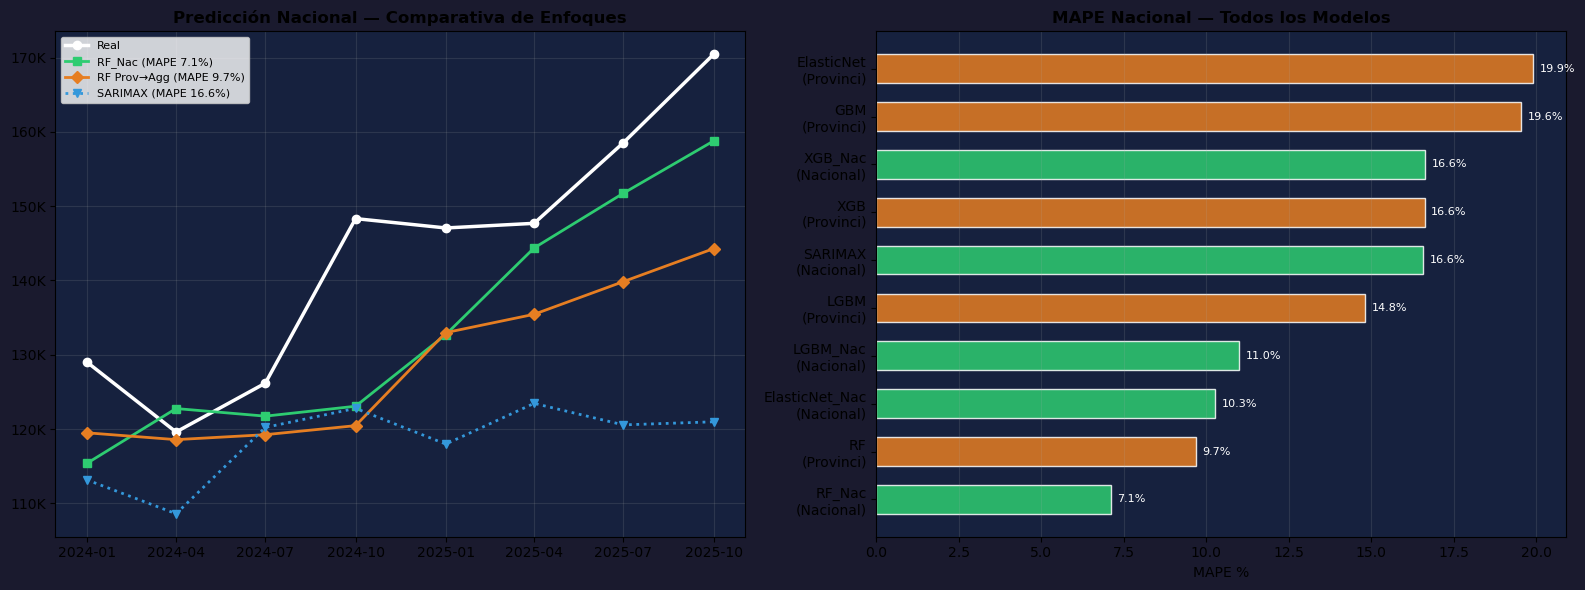

In [13]:
# ── Gráfico: Nacional Dedicado vs Provincial Agregado ──
import matplotlib.ticker as mtick
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('#1a1a2e')
for ax in axes: ax.set_facecolor('#16213e')

# Left: predicciones vs realidad
ax = axes[0]
ax.plot(y_nac_te.index, y_nac_te.values, 'w-o', lw=2.5, label='Real', markersize=6)

# Mejor modelo nacional dedicado
best_nac_name = df_final[df_final['Enfoque']=='Nacional Dedicado'].sort_values('MAPE%').iloc[0]['Modelo']
best_nac_pred = results_nac[best_nac_name]['pred']
mape_best = mean_absolute_percentage_error(y_nac_te, best_nac_pred)*100
ax.plot(y_nac_te.index, best_nac_pred, 's-', color='#2ecc71', lw=2, 
        label=f'{best_nac_name} (MAPE {mape_best:.1f}%)', markersize=6)

# Mejor provincial agregado
best_prov_agg = df_final[df_final['Enfoque']=='Provincial→Agregado'].sort_values('MAPE%').iloc[0]['Modelo']
nr = results[best_prov_agg]['nac_real']
np_ = results[best_prov_agg]['nac_pred']
mape_pa = mean_absolute_percentage_error(nr, np_)*100
ax.plot(nr.index, np_.values, 'D-', color='#e67e22', lw=2,
        label=f'{best_prov_agg} Prov→Agg (MAPE {mape_pa:.1f}%)', markersize=6)

# SARIMAX
mape_sx = mean_absolute_percentage_error(sarimax_real_nac, sarimax_pred_nac)*100
ax.plot(sarimax_pred_nac.index, sarimax_pred_nac.values, 'v:', color='#3498db', lw=2,
        label=f'SARIMAX (MAPE {mape_sx:.1f}%)', markersize=6)

ax.set_title('Predicción Nacional — Comparativa de Enfoques', fontweight='bold')
ax.legend(fontsize=8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{x/1000:.0f}K'))
ax.grid(alpha=0.15)

# Right: MAPE comparativo
ax = axes[1]
df_plot = df_final.groupby(['Enfoque','Modelo'])['MAPE%'].first().reset_index()
colors_map = {'Provincial→Agregado':'#e67e22','Nacional Dedicado':'#2ecc71'}
df_plot = df_plot.sort_values('MAPE%', ascending=True).head(12)
bars = ax.barh(
    [f"{r['Modelo']}\n({r['Enfoque'][:8]})" for _,r in df_plot.iterrows()],
    df_plot['MAPE%'],
    color=[colors_map.get(r['Enfoque'],'gray') for _,r in df_plot.iterrows()],
    alpha=0.85, edgecolor='white', height=0.6)
for b,v in zip(bars, df_plot['MAPE%']):
    ax.text(b.get_width()+0.2, b.get_y()+b.get_height()/2, f'{v:.1f}%', va='center', fontsize=8, color='white')
ax.set_title('MAPE Nacional — Todos los Modelos', fontweight='bold')
ax.set_xlabel('MAPE %')
ax.grid(axis='x', alpha=0.15)

plt.tight_layout()
plt.show()

## 5d. Market Share Approach + Bias Correction

**Market Share**: Predecir el total nacional con un modelo dedicado, luego distribuir por cuota provincial.
Así la suma provincial = predicción nacional SIEMPRE.

**Bias Correction**: Corregir el sesgo sistemático del enfoque Provincial→Agregado.

In [14]:
# ── MARKET SHARE APPROACH ──
# 1. Calcular cuota histórica de cada provincia
df_ms = df.copy()
df_ms['Hip_Nacional'] = df_ms.groupby('Trimestre')['Hipotecas_Total'].transform('sum')
df_ms['Cuota'] = df_ms['Hipotecas_Total'] / df_ms['Hip_Nacional']

# Predecir cuota con el modelo provincial (mismas features)
from sklearn.ensemble import RandomForestRegressor as RFR

# Train cuota model
df_ms_train = df_ms[df_ms['Trimestre'] < test_start]
df_ms_test = df_ms[df_ms['Trimestre'] >= test_start]

cuota_model = RFR(n_estimators=300, max_depth=15, min_samples_leaf=5,
    max_features='sqrt', random_state=42, n_jobs=-1)
cuota_model.fit(df_ms_train[features_ml], df_ms_train['Cuota'])
cuota_pred = cuota_model.predict(df_ms_test[features_ml])

# Normalizar cuotas para que sumen 1 por trimestre
df_ms_test = df_ms_test.copy()
df_ms_test['cuota_pred'] = cuota_pred
cuota_sum = df_ms_test.groupby('Trimestre')['cuota_pred'].transform('sum')
df_ms_test['cuota_norm'] = df_ms_test['cuota_pred'] / cuota_sum

# Usar el mejor modelo nacional dedicado para predecir el total
best_nac_model_name = 'XGB_Nac'
best_nac_pred = results_nac[best_nac_model_name]['pred']

# Distribuir total nacional por cuota
ms_preds = []
for trim_idx, trim in enumerate(sorted(df_ms_test['Trimestre'].unique())):
    mask = df_ms_test['Trimestre'] == trim
    cuotas = df_ms_test.loc[mask, 'cuota_norm'].values
    total_pred = best_nac_pred[trim_idx] if trim_idx < len(best_nac_pred) else best_nac_pred[-1]
    ms_preds.extend(cuotas * total_pred)

df_ms_test['ms_pred'] = ms_preds

# Métricas Market Share
mape_ms_prov = mean_absolute_percentage_error(df_ms_test['Hipotecas_Total'], df_ms_test['ms_pred'])*100
r2_ms_prov = r2_score(df_ms_test['Hipotecas_Total'], df_ms_test['ms_pred'])

# Nacional
ms_nac_real = df_ms_test.groupby('Trimestre')['Hipotecas_Total'].sum()
ms_nac_pred = df_ms_test.groupby('Trimestre')['ms_pred'].sum()
mape_ms_nac = mean_absolute_percentage_error(ms_nac_real, ms_nac_pred)*100
r2_ms_nac = r2_score(ms_nac_real, ms_nac_pred)

print("── MARKET SHARE APPROACH ──")
print(f"Provincial: MAPE={mape_ms_prov:.2f}% | R²={r2_ms_prov:.4f}")
print(f"Nacional:   MAPE={mape_ms_nac:.2f}% | R²={r2_ms_nac:.4f}")
print(f"  (Nacional = {best_nac_model_name} distribuido por cuota RF)")

── MARKET SHARE APPROACH ──
Provincial: MAPE=225.54% | R²=-0.5959
Nacional:   MAPE=23.64% | R²=-5.7657
  (Nacional = XGB_Nac distribuido por cuota RF)


In [15]:
# ── BIAS CORRECTION (Provincial→Agregado) ──
# El sesgo se calcula en el train set y se aplica al test

# Para cada modelo provincial, calcular bias en train
bias_results = {}
for name in ['RF','XGB','LGBM','GBM']:
    model = results[name]['model']
    # Predecir en train para calcular bias
    if name == 'ElasticNet':
        pred_train = model.predict(scaler.transform(df_train[features_ml]))
    else:
        pred_train = model.predict(df_train[features_ml])
    
    # Agregar a nivel nacional
    df_bias = df_train[['Trimestre','Hipotecas_Total']].copy()
    df_bias['pred'] = pred_train
    nac_real_tr = df_bias.groupby('Trimestre')['Hipotecas_Total'].sum()
    nac_pred_tr = df_bias.groupby('Trimestre')['pred'].sum()
    
    # Calcular bias medio (últimos 8 trimestres del train para estabilidad)
    bias = (nac_real_tr - nac_pred_tr).iloc[-8:].mean()
    
    # Aplicar corrección al test
    nr = results[name]['nac_real']
    np_orig = results[name]['nac_pred']
    np_corrected = np_orig + bias
    
    mape_orig = mean_absolute_percentage_error(nr, np_orig)*100
    mape_corr = mean_absolute_percentage_error(nr, np_corrected)*100
    r2_orig = r2_score(nr, np_orig)
    r2_corr = r2_score(nr, np_corrected)
    
    bias_results[name] = {
        'pred_corr': np_corrected, 'bias': bias,
        'mape_orig': mape_orig, 'mape_corr': mape_corr,
        'r2_orig': r2_orig, 'r2_corr': r2_corr
    }
    print(f"{name:10s}: bias={bias:+.0f} | MAPE {mape_orig:.2f}%→{mape_corr:.2f}% | R² {r2_orig:.3f}→{r2_corr:.3f}")

print("\n── BIAS CORRECTION APLICADA ──")

RF        : bias=-657 | MAPE 9.69%→10.16% | R² -0.102→-0.177
XGB       : bias=+36 | MAPE 16.62%→16.60% | R² -1.875→-1.868
LGBM      : bias=-12 | MAPE 14.82%→14.82% | R² -1.157→-1.159
GBM       : bias=+67 | MAPE 19.55%→19.50% | R² -2.794→-2.779

── BIAS CORRECTION APLICADA ──


## 5e. Tabla Final — Todos los Enfoques

In [16]:
# ── TABLA FINAL COMPARATIVA ──
rows_all = []

# 1. Provincial→Agregado (sin corrección)
for name in ['RF','XGB','LGBM','GBM','ElasticNet']:
    nr = results[name]['nac_real']
    np_ = results[name]['nac_pred']
    mape = mean_absolute_percentage_error(nr, np_)*100
    rmse = np.sqrt(mean_squared_error(nr, np_))
    r2 = r2_score(nr, np_)
    rows_all.append({'Enfoque':'1. Prov→Agregado','Modelo':name,
                     'MAPE%':round(mape,2),'RMSE':round(rmse,0),'R²':round(r2,4)})

# 2. Provincial→Agregado + Bias Correction
for name, br in bias_results.items():
    rows_all.append({'Enfoque':'2. Prov+BiasFix','Modelo':name,
                     'MAPE%':round(br['mape_corr'],2),
                     'RMSE':round(np.sqrt(mean_squared_error(results[name]['nac_real'], br['pred_corr'])),0),
                     'R²':round(br['r2_corr'],4)})

# 3. Nacional Dedicado (ponderado)
for name, res in results_nac.items():
    mape = mean_absolute_percentage_error(res['real'], res['pred'])*100
    rmse = np.sqrt(mean_squared_error(res['real'], res['pred']))
    r2 = r2_score(res['real'], res['pred'])
    rows_all.append({'Enfoque':'3. Nacional Dedicado','Modelo':name,
                     'MAPE%':round(mape,2),'RMSE':round(rmse,0),'R²':round(r2,4)})

# 4. Market Share
rows_all.append({'Enfoque':'4. Market Share','Modelo':'RF_cuota+XGB_Nac',
                 'MAPE%':round(mape_ms_nac,2),
                 'RMSE':round(np.sqrt(mean_squared_error(ms_nac_real, ms_nac_pred)),0),
                 'R²':round(r2_ms_nac,4)})

# 5. SARIMAX
mape_sx = mean_absolute_percentage_error(sarimax_real_nac, sarimax_pred_nac)*100
rmse_sx = np.sqrt(mean_squared_error(sarimax_real_nac, sarimax_pred_nac))
r2_sx = r2_score(sarimax_real_nac, sarimax_pred_nac)
rows_all.append({'Enfoque':'5. SARIMAX','Modelo':'SARIMAX',
                 'MAPE%':round(mape_sx,2),'RMSE':round(rmse_sx,0),'R²':round(r2_sx,4)})

df_all = pd.DataFrame(rows_all).sort_values('MAPE%')
print("═"*72)
print("    BENCHMARK DEFINITIVO NACIONAL — TODOS LOS ENFOQUES")
print("═"*72)
print(df_all.to_string(index=False))
best = df_all.iloc[0]
print(f"\n🏆 GANADOR: {best['Modelo']} ({best['Enfoque']}) — MAPE={best['MAPE%']:.2f}% R²={best['R²']:.4f}")

# Top 5
print("\n── TOP 5 ──")
print(df_all.head(5).to_string(index=False))

════════════════════════════════════════════════════════════════════════
    BENCHMARK DEFINITIVO NACIONAL — TODOS LOS ENFOQUES
════════════════════════════════════════════════════════════════════════
             Enfoque           Modelo  MAPE%    RMSE      R²
3. Nacional Dedicado           RF_Nac   7.11 12513.0  0.3995
    1. Prov→Agregado               RF   9.69 16949.0 -0.1017
     2. Prov+BiasFix               RF  10.16 17517.0 -0.1768
3. Nacional Dedicado   ElasticNet_Nac  10.26 18486.0 -0.3105
3. Nacional Dedicado         LGBM_Nac  10.99 18017.0 -0.2449
    1. Prov→Agregado             LGBM  14.82 23717.0 -1.1572
     2. Prov+BiasFix             LGBM  14.82 23728.0 -1.1592
3. Nacional Dedicado          SARIMAX  16.57 28246.0 -2.0597
          5. SARIMAX          SARIMAX  16.57 28246.0 -2.0597
     2. Prov+BiasFix              XGB  16.60 27348.0 -1.8684
    1. Prov→Agregado              XGB  16.62 27381.0 -1.8752
3. Nacional Dedicado          XGB_Nac  16.63 25748.0 -1.5426
     2

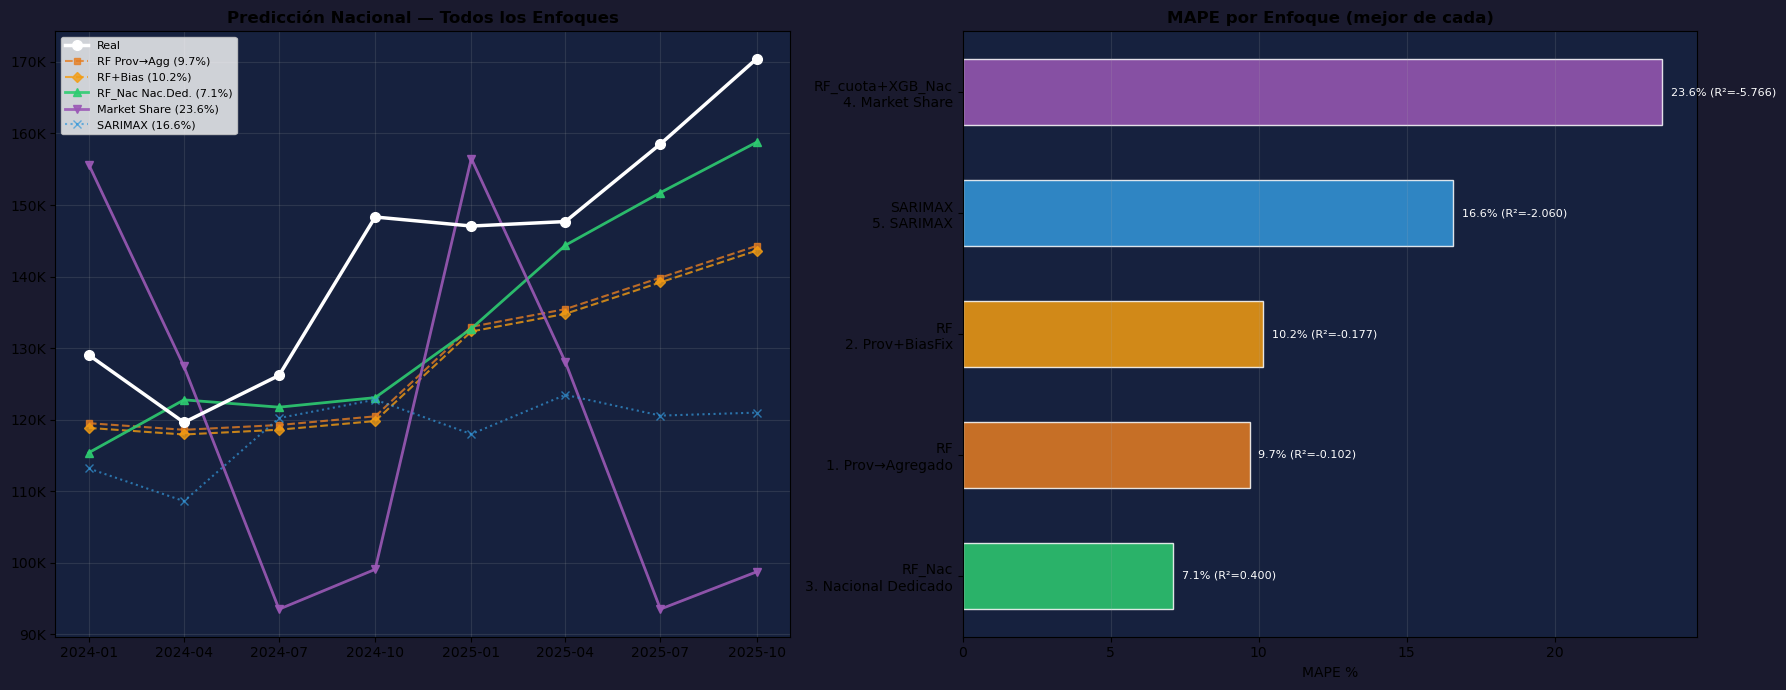

In [17]:
# ── Gráfico final: predicción nacional con TODOS los enfoques ──
import matplotlib.ticker as mtick
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.patch.set_facecolor('#1a1a2e')
for ax in axes: ax.set_facecolor('#16213e')

ax = axes[0]
# Real
ax.plot(y_nac_te.index, y_nac_te.values, 'w-o', lw=2.5, ms=7, label='Real', zorder=5)

# Top models de cada enfoque
# 1. Mejor Prov→Agregado
nr = results['RF']['nac_real']
np_ = results['RF']['nac_pred']
m1 = mean_absolute_percentage_error(nr, np_)*100
ax.plot(nr.index, np_.values, 's--', color='#e67e22', lw=1.5, ms=5,
        label=f'RF Prov→Agg ({m1:.1f}%)', alpha=0.8)

# 2. Mejor Prov+Bias
best_bias = min(bias_results.items(), key=lambda x: x[1]['mape_corr'])
bn, br = best_bias
m2 = br['mape_corr']
ax.plot(nr.index, br['pred_corr'].values, 'D--', color='#f39c12', lw=1.5, ms=5,
        label=f'{bn}+Bias ({m2:.1f}%)', alpha=0.8)

# 3. Mejor Nacional Dedicado
best_nd = min(results_nac.items(), key=lambda x: mean_absolute_percentage_error(x[1]['real'],x[1]['pred']))
nn, nres = best_nd
m3 = mean_absolute_percentage_error(nres['real'], nres['pred'])*100
ax.plot(y_nac_te.index, nres['pred'], '^-', color='#2ecc71', lw=2, ms=6,
        label=f'{nn} Nac.Ded. ({m3:.1f}%)', alpha=0.9)

# 4. Market Share
m4 = mape_ms_nac
ax.plot(ms_nac_real.index, ms_nac_pred.values, 'v-', color='#9b59b6', lw=2, ms=6,
        label=f'Market Share ({m4:.1f}%)', alpha=0.9)

# 5. SARIMAX
m5 = mean_absolute_percentage_error(sarimax_real_nac, sarimax_pred_nac)*100
ax.plot(sarimax_pred_nac.index, sarimax_pred_nac.values, 'x:', color='#3498db', lw=1.5, ms=6,
        label=f'SARIMAX ({m5:.1f}%)', alpha=0.7)

ax.set_title('Predicción Nacional — Todos los Enfoques', fontsize=12, fontweight='bold')
ax.legend(fontsize=8, loc='upper left')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{x/1000:.0f}K'))
ax.grid(alpha=0.15)

# Right: barplot por enfoque
ax = axes[1]
df_top = df_all.drop_duplicates('Enfoque').sort_values('MAPE%')
palette = {'1. Prov→Agregado':'#e67e22','2. Prov+BiasFix':'#f39c12',
           '3. Nacional Dedicado':'#2ecc71','4. Market Share':'#9b59b6','5. SARIMAX':'#3498db'}
bars = ax.barh(
    [f"{r['Modelo']}\n{r['Enfoque']}" for _,r in df_top.iterrows()],
    df_top['MAPE%'],
    color=[palette.get(r['Enfoque'],'gray') for _,r in df_top.iterrows()],
    alpha=0.85, edgecolor='white', height=0.55)
for b,v,r2 in zip(bars, df_top['MAPE%'], df_top['R²']):
    ax.text(b.get_width()+0.3, b.get_y()+b.get_height()/2,
            f'{v:.1f}% (R²={r2:.3f})', va='center', fontsize=8, color='white')
ax.set_title('MAPE por Enfoque (mejor de cada)', fontsize=12, fontweight='bold')
ax.set_xlabel('MAPE %')
ax.grid(axis='x', alpha=0.15)

plt.tight_layout()
plt.show()

## 6. Modelo SARIMAX — Series Temporales Nacionales

Modelo de series temporales con componente estacional para predecir el volumen hipotecario nacional. Los regresores exógenos usan versiones `_lag1` para evitar leakage.

MAPE (Error Porcentual Medio — SARIMAX): 16.57%


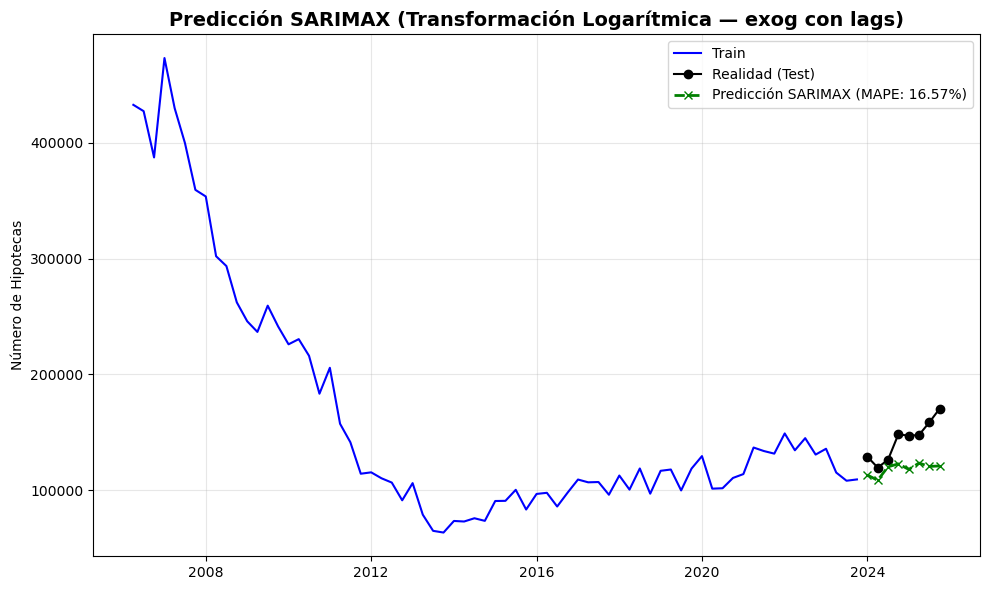

In [18]:
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_percentage_error

# Datos nacionales agregados desde df (con lags ya aplicados)
df = df.copy()
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Spread_Hipotecas_lag1': 'mean',  # ✅ lag aplicado — sin leakage
    'Tasa_Paro_lag1': 'mean'          # ✅ lag aplicado — sin leakage
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)
df_nacional.index.freq = pd.infer_freq(df_nacional.index)

# Transformación logarítmica de la variable objetivo
y_log = np.log(df_nacional['Hipotecas_Total'])
X = df_nacional[['Euribor', 'Spread_Hipotecas_lag1', 'Tasa_Paro_lag1']]  # ✅ lag aplicado — sin leakage

test_size = 8
y_train, y_test = y_log.iloc[:-test_size], y_log.iloc[-test_size:]
X_train, X_test = X.iloc[:-test_size], X.iloc[-test_size:]

modelo_log = sm.tsa.statespace.SARIMAX(
    endog=y_train, exog=X_train,
    order=(1, 1, 1), seasonal_order=(1, 0, 0, 4),
    enforce_stationarity=False, enforce_invertibility=False
)
resultados = modelo_log.fit(disp=False)

pred_log = resultados.get_forecast(steps=test_size, exog=X_test).predicted_mean
y_pred_real = np.exp(pred_log)
y_test_real = np.exp(y_test)

mape = mean_absolute_percentage_error(y_test_real, y_pred_real)
print(f"MAPE (Error Porcentual Medio — SARIMAX): {mape*100:.2f}%")

plt.figure(figsize=(10, 6))
y_train_real = np.exp(y_train)
plt.plot(y_train_real.index, y_train_real, label='Train', color='blue')
plt.plot(y_test_real.index, y_test_real, label='Realidad (Test)', color='black', marker='o')
plt.plot(y_pred_real.index, y_pred_real,
         label=f'Predicción SARIMAX (MAPE: {mape*100:.2f}%)',
         color='green', linestyle='--', marker='x', linewidth=2)
plt.title("Predicción SARIMAX (Transformación Logarítmica — exog con lags)", fontsize=14, fontweight='bold')
plt.ylabel("Número de Hipotecas")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig('sarimax_optimizado.png', dpi=300)  # desactivado: guardar imagen
plt.show()

### 6.2 Diagnostico de Residuos del SARIMAX
Si los residuos del SARIMAX no presentan autocorrelacion (p-valor del test de Ljung-Box > 0.05), el modelo ha capturado correctamente toda la estructura temporal de la serie.

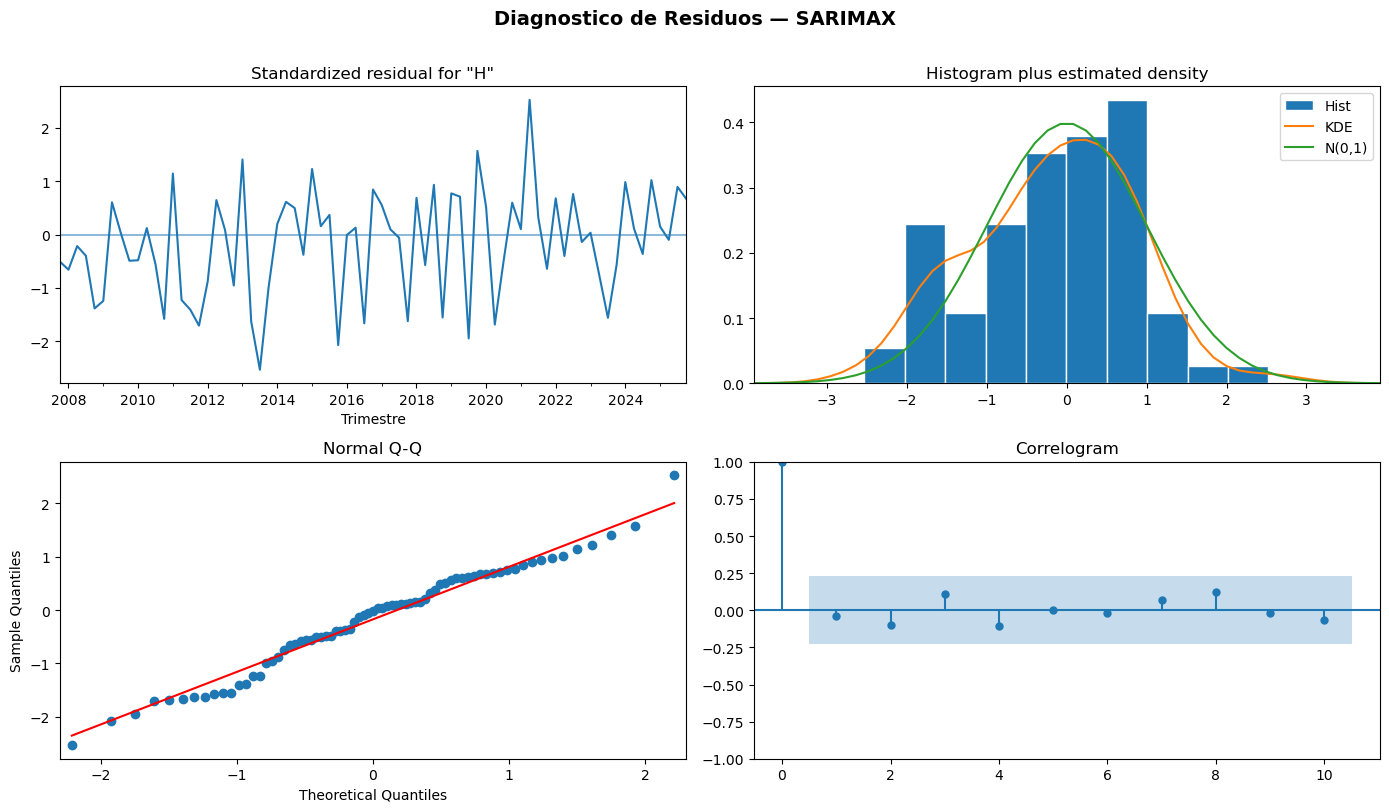

Test Ljung-Box sobre residuos SARIMAX (H0: no autocorrelacion):
     lb_stat  lb_pvalue
4   2.788842   0.593760
8   2.839094   0.944046
12  2.856828   0.996473

Resumen del modelo SARIMAX:
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Euribor                  -0.1269      0.049     -2.571      0.010      -0.224      -0.030
Spread_Hipotecas_lag1    -0.1715      0.131     -1.310      0.190      -0.428       0.085
Tasa_Paro_lag1           -0.0454      0.019     -2.445      0.014      -0.082      -0.009
ar.L1                     0.1999      0.394      0.507      0.612      -0.573       0.973
ma.L1                    -0.5797      0.398     -1.458      0.145      -1.359       0.200
ar.S.L4                   0.2952      0.131      2.261      0.024       0.039       0.551
sigma2                    0.0117      0.002      4.727      0.000       0.007       0.016


In [19]:
# -- Diagnostico de residuos SARIMAX (test de autocorrelacion Ljung-Box) ---------
# Si los residuos del SARIMAX no tienen autocorrelacion (p-valor Ljung-Box > 0.05)
# el modelo ha capturado toda la estructura temporal -> validacion del modelo.

import pandas as pd, numpy as np, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf

df_s = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Spread_Hipotecas_lag1': 'mean',
    'Tasa_Paro_lag1': 'mean'
}).sort_index()
df_s.index.freq = pd.infer_freq(df_s.index)

y_log = np.log(df_s['Hipotecas_Total'])
X_exog = df_s[['Euribor', 'Spread_Hipotecas_lag1', 'Tasa_Paro_lag1']]

modelo = sm.tsa.statespace.SARIMAX(
    endog=y_log, exog=X_exog,
    order=(1,1,1), seasonal_order=(1,0,0,4),
    enforce_stationarity=False, enforce_invertibility=False
)
res = modelo.fit(disp=False)

fig = res.plot_diagnostics(figsize=(14, 8))
fig.suptitle("Diagnostico de Residuos — SARIMAX", fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
# plt.savefig('sarimax_diagnostico_residuos.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

# Test de Ljung-Box
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(res.resid, lags=[4, 8, 12], return_df=True)
print("Test Ljung-Box sobre residuos SARIMAX (H0: no autocorrelacion):")
print(lb.to_string())
print()
print("Resumen del modelo SARIMAX:")
print(res.summary().tables[1])

### 6.3 Benchmark Definitivo: RF_Nac vs SARIMAX

Comparacion directa entre el mejor modelo ML (RF_Nac) y el mejor modelo econometrico (SARIMAX) sobre el **mismo periodo de test** (8 trimestres).

   BENCHMARK RF_Nac vs SARIMAX - Prediccion Nacional
 Modelo  MAPE%    RMSE      R2     MAE
 RF_Nac   7.11 12513.0  0.3995 10328.0
SARIMAX  16.57 28246.0 -2.0597 24890.0

CONCLUSION: GANA RF_Nac
  Mejora MAPE : +9.46 pp menos error
  R2 RF_Nac: 0.3995 | R2 SARIMAX: -2.0597
  Por que gana RF_Nac:
  1. Captura relaciones no lineales entre Euribor, PIB y demanda.
  2. Usa medias ponderadas por poblacion (Madrid/BCN pesan mas).
  3. 94 features de feature engineering vs 3 del SARIMAX.
  4. R2 positivo (0.400) vs R2 negativo SARIMAX (-2.060).


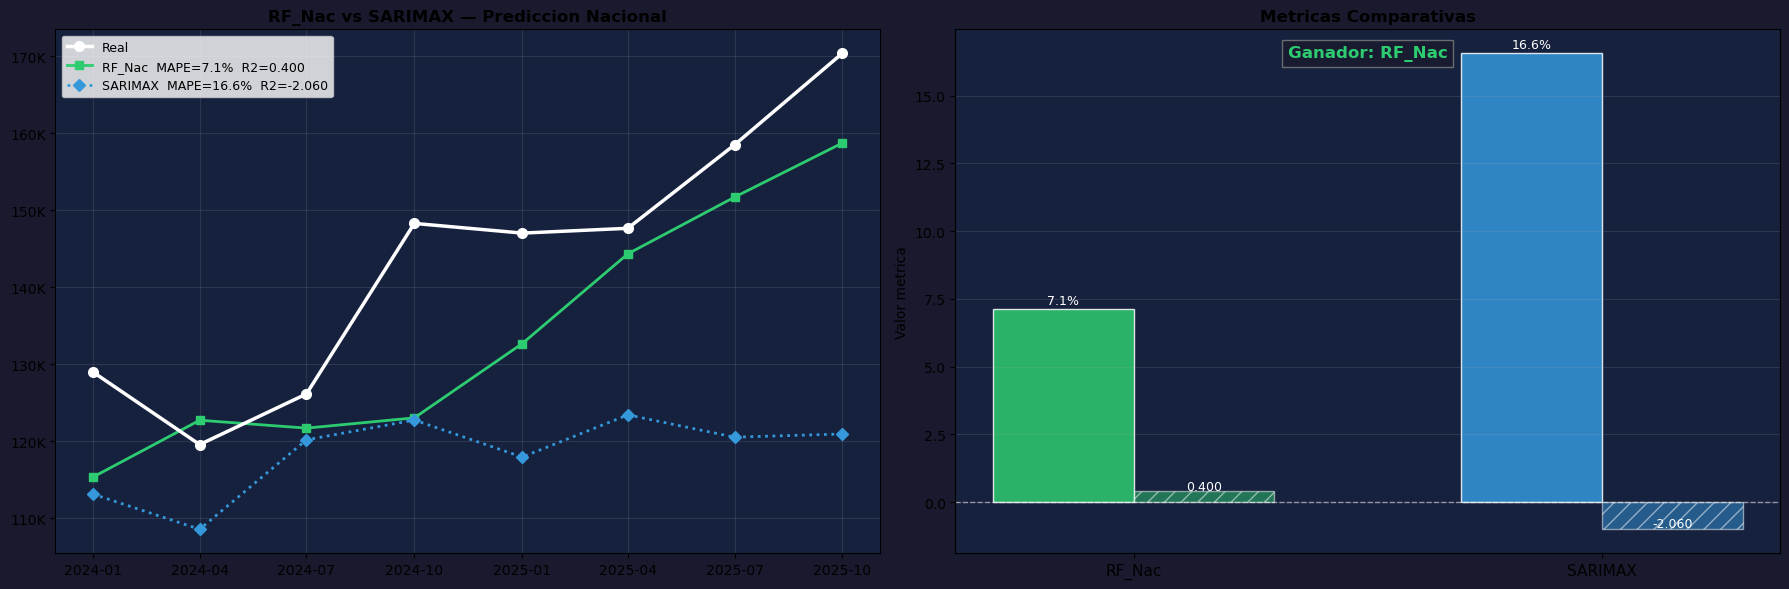

In [20]:
# ── Benchmark RF_Nac vs SARIMAX ──
import matplotlib.ticker as mtick

rf_nac_pred = results_nac['RF_Nac']['pred']
rf_nac_real = results_nac['RF_Nac']['real']
sx_pred     = sarimax_pred_nac.values
sx_real     = sarimax_real_nac.values

metrics_bench = {}
for label, real, pred in [('RF_Nac', rf_nac_real, rf_nac_pred),
                           ('SARIMAX', sx_real, sx_pred)]:
    metrics_bench[label] = {
        'MAPE%' : round(mean_absolute_percentage_error(real, pred)*100, 2),
        'RMSE'  : round(float(np.sqrt(mean_squared_error(real, pred))), 0),
        'R2'    : round(float(r2_score(real, pred)), 4),
        'MAE'   : round(float(np.mean(np.abs(real - pred))), 0),
    }

df_bench = pd.DataFrame(metrics_bench).T.reset_index().rename(columns={'index':'Modelo'})
df_bench = df_bench.sort_values('MAPE%')
print("=" * 60)
print("   BENCHMARK RF_Nac vs SARIMAX - Prediccion Nacional")
print("=" * 60)
print(df_bench.to_string(index=False))

winner = df_bench.iloc[0]['Modelo']
loser  = df_bench.iloc[1]['Modelo']
delta_mape = df_bench.iloc[1]['MAPE%'] - df_bench.iloc[0]['MAPE%']
r2_winner = metrics_bench[winner]['R2']
r2_loser  = metrics_bench[loser]['R2']

print()
print("=" * 60)
print(f"CONCLUSION: GANA {winner}")
print(f"  Mejora MAPE : +{delta_mape:.2f} pp menos error")
print(f"  R2 {winner}: {r2_winner:.4f} | R2 {loser}: {r2_loser:.4f}")
if winner == 'RF_Nac':
    print("  Por que gana RF_Nac:")
    print("  1. Captura relaciones no lineales entre Euribor, PIB y demanda.")
    print("  2. Usa medias ponderadas por poblacion (Madrid/BCN pesan mas).")
    print("  3. 94 features de feature engineering vs 3 del SARIMAX.")
    print(f"  4. R2 positivo ({r2_winner:.3f}) vs R2 negativo SARIMAX ({r2_loser:.3f}).")
else:
    print("  El componente estacional del SARIMAX es mas apropiado.")
print("=" * 60)

# Grafico comparativo
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.patch.set_facecolor('#1a1a2e')
for ax in axes: ax.set_facecolor('#16213e')

ax = axes[0]
ax.plot(y_nac_te.index, rf_nac_real, 'w-o', lw=2.5, ms=7, zorder=5, label='Real')
ax.plot(y_nac_te.index, rf_nac_pred, 's-', color='#2ecc71', lw=2, ms=6,
        label=f"RF_Nac  MAPE={metrics_bench['RF_Nac']['MAPE%']:.1f}%  R2={metrics_bench['RF_Nac']['R2']:.3f}")
ax.plot(sarimax_pred_nac.index, sx_pred, 'D:', color='#3498db', lw=2, ms=6,
        label=f"SARIMAX  MAPE={metrics_bench['SARIMAX']['MAPE%']:.1f}%  R2={metrics_bench['SARIMAX']['R2']:.3f}")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{x/1000:.0f}K'))
ax.set_title('RF_Nac vs SARIMAX — Prediccion Nacional', fontsize=12, fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.15)

ax = axes[1]
model_labels = ['RF_Nac', 'SARIMAX']
bar_colors   = ['#2ecc71', '#3498db']
mape_vals    = [metrics_bench[m]['MAPE%'] for m in model_labels]
r2_vals      = [max(metrics_bench[m]['R2'], -1.0) for m in model_labels]
x = np.arange(2)
w = 0.3
b1 = ax.bar(x - w/2, mape_vals, w, color=bar_colors, alpha=0.85, edgecolor='white', label='MAPE %')
b2 = ax.bar(x + w/2, r2_vals,   w, color=bar_colors, alpha=0.5,  edgecolor='white', hatch='//', label='R2')
for b, v in zip(b1, mape_vals):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.2, f'{v:.1f}%',
            ha='center', fontsize=9, color='white')
for b, v in zip(b2, [metrics_bench[m]['R2'] for m in model_labels]):
    ax.text(b.get_x()+b.get_width()/2, max(b.get_height(), -0.95)+0.05, f'{v:.3f}',
            ha='center', fontsize=9, color='white')
ax.set_xticks(x)
ax.set_xticklabels(model_labels, fontsize=11)
ax.axhline(0, color='white', lw=1, ls='--', alpha=0.5)
ax.set_title('Metricas Comparativas', fontsize=12, fontweight='bold')
ax.set_ylabel('Valor metrica'); ax.grid(axis='y', alpha=0.15)
winner_color = '#2ecc71' if winner == 'RF_Nac' else '#3498db'
ax.text(0.5, 0.97, f'Ganador: {winner}', transform=ax.transAxes,
        ha='center', va='top', fontsize=12, fontweight='bold', color=winner_color,
        bbox=dict(facecolor='#1a1a2e', alpha=0.8, edgecolor='gray', pad=4))

plt.tight_layout(); plt.show()

## 7. Analisis Econometrico — Estacionariedad y Cointegracion

### 7.1 ACF y PACF de las Hipotecas Nacionales
Antes de los tests formales, la funcion de autocorrelacion (ACF) y la autocorrelacion parcial (PACF) permiten identificar visualmente el orden de integracion y los ordenes AR/MA apropiados para el modelo.

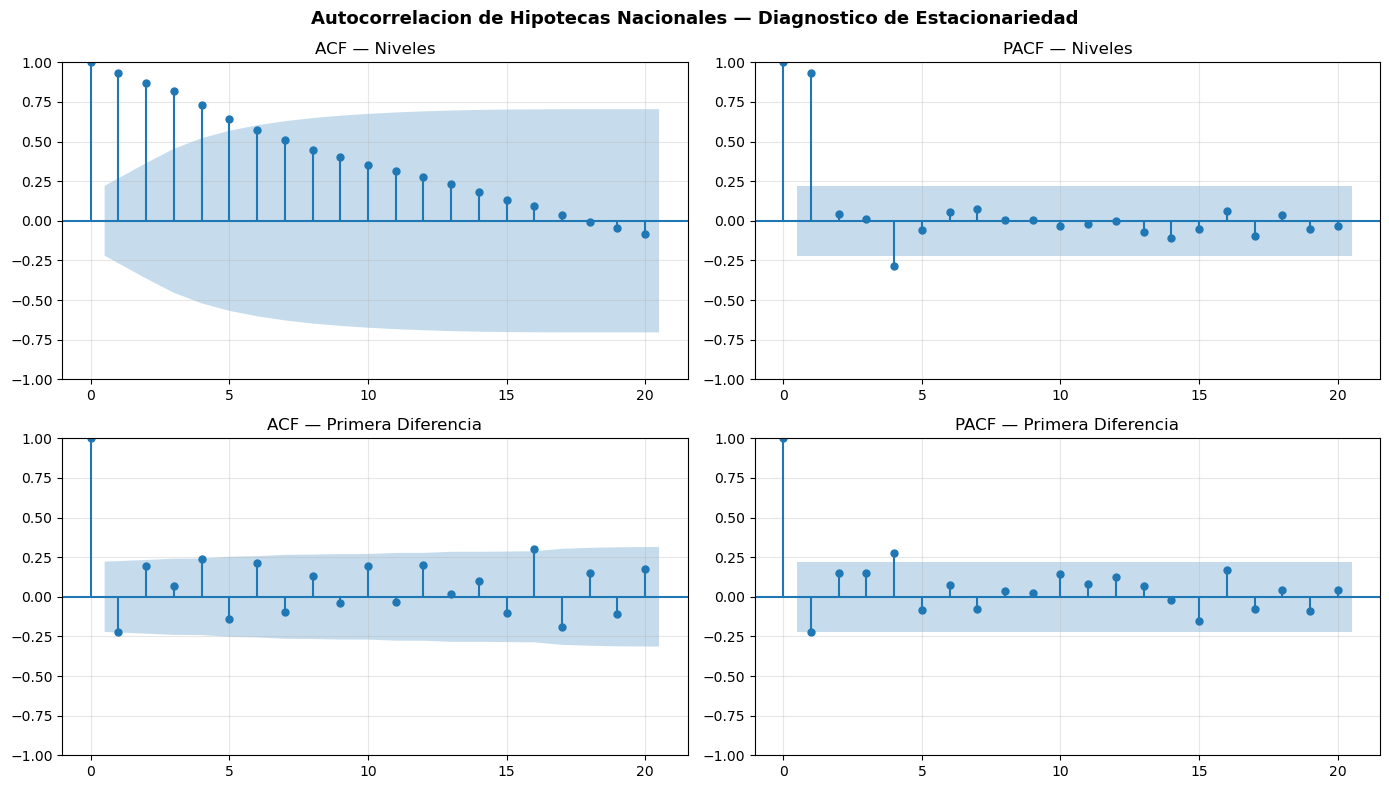

ACF/PACF guardado.


In [21]:
# -- ACF / PACF de Hipotecas Nacionales (pre-modelizacion) -----------------------
# Permite identificar el orden de autocorrelacion:
#   - ACF decae lento -> serie no estacionaria (I(1))
#   - PACF corta en lag p -> AR(p)
# Esto justifica visualmente el orden del SARIMAX y el VAR.

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

df_acf = df.groupby('Trimestre')['Hipotecas_Total'].sum().sort_index()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Autocorrelacion de Hipotecas Nacionales — Diagnostico de Estacionariedad",
             fontsize=13, fontweight='bold')

# Niveles
plot_acf(df_acf.dropna(),  lags=20, ax=axes[0,0], title="ACF — Niveles")
plot_pacf(df_acf.dropna(), lags=20, ax=axes[0,1], title="PACF — Niveles", method='ywm')

# Primera diferencia
df_diff = df_acf.diff().dropna()
plot_acf(df_diff,  lags=20, ax=axes[1,0], title="ACF — Primera Diferencia")
plot_pacf(df_diff, lags=20, ax=axes[1,1], title="PACF — Primera Diferencia", method='ywm')

for ax in axes.flat:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
# plt.savefig('acf_pacf_hipotecas.png', dpi=300)  # desactivado: guardar imagen
plt.show()
print("ACF/PACF guardado.")

### 7.2 Test de Raiz Unitaria (ADF)
Verificacion formal de estacionariedad de las series. Una serie I(1) estacionaria en primera diferencia puede modelizarse con VAR en diferencias o con VECM si existe cointegracion.

In [44]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings('ignore')

# 1. CARGAR Y PREPARAR DATOS A NIVEL NACIONAL
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc', 'Transmisiones_Total', 'Pob_Ext']
for c in cols_to_fill:
    if c in df.columns:
        df[c] = df.groupby('Provincia')[c].transform(lambda x: x.ffill().bfill())
df = df.dropna().reset_index(drop=True)

# Agrupación Nacional
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total':      'sum',
    'Transmisiones_Total':  'sum',
    'Poblacion':            'sum',
    'Euribor':              'mean',
    'Precio_m2':            'mean',
    'Tasa_Paro':            'mean',
    'PIB_pc':               'mean',
    'IPC':                  'mean',
    'tasa_ahorro':          'mean',
    'Spread_Hipotecas':     'mean',
    'Edad_Media':           'mean',
    'Indice_Mano_Obra':     'mean',
    'Indice_Materiales':    'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. TRANSFORMACIONES (Logs vs Niveles)
vars_log   = ['Hipotecas_Total', 'Transmisiones_Total', 'Precio_m2', 'PIB_pc', 'Poblacion',
              'Indice_Mano_Obra', 'Indice_Materiales', 'IPC']
vars_level = ['Euribor', 'Tasa_Paro', 'tasa_ahorro', 'Spread_Hipotecas', 'Edad_Media']

# FIX: series con tendencia determinista visible → regression='ct' en ADF
#      series sin tendencia (tasas, spreads) → regression='c'
vars_con_tendencia = {f'Log_{v}' for v in vars_log}

df_final = pd.DataFrame()
for col in vars_log:
    if col in df_nacional.columns:
        df_final[f'Log_{col}'] = np.log(df_nacional[col])
for col in vars_level:
    if col in df_nacional.columns:
        df_final[col] = df_nacional[col]

# 3. CREAR LAGS (1 trimestre y 4 trimestres/anual)
cols_base = df_final.columns.tolist()
for col in cols_base:
    df_final[f'{col}_lag1'] = df_final[col].shift(1)
    df_final[f'{col}_lag4'] = df_final[col].shift(4)

# 4. FUNCIÓN ADF CORREGIDA
def generar_tabla_adf(df_input, vars_tendencia):
    resultados = []

    # FIX: testear solo columnas base, no los lags
    # (un lag de I(1) sigue siendo I(1) — añadirlos solo infla la tabla)
    cols_a_testear = [c for c in sorted(df_input.columns) if '_lag' not in c]

    for col in cols_a_testear:
        series = df_input[col].dropna()
        if len(series) < 10:
            continue

        # FIX: regression='ct' para series con tendencia, 'c' para el resto
        reg = 'ct' if col in vars_tendencia else 'c'

        # Test en Nivel
        res      = adfuller(series, regression=reg)
        stat     = res[0]
        pval     = res[1]
        cv5      = res[4]['5%']

        # Test en Primera Diferencia (siempre con 'c' — la diferencia elimina tendencia)
        series_diff = series.diff().dropna()
        if len(series_diff) < 10:
            pval_diff = 1.0
            stat_diff = np.nan
        else:
            res_d     = adfuller(series_diff, regression='c')
            stat_diff = res_d[0]
            pval_diff = res_d[1]

        # Lógica de decisión
        # FIX: "I(2)" sustituido por "No concluyente" — el test no puede afirmar I(2)
        #      sin testar la segunda diferencia explícitamente
        if pval < 0.05:
            orden = "I(0) Estacionaria"
            icono = "✅"
        elif pval_diff < 0.05:
            orden = "I(1) Estacionaria en 1ª Dif"
            icono = "🔄"
        else:
            orden = "No concluyente — revisar"
            icono = "⚠️"

        resultados.append({
            'Variable':       col,
            'Regresión':      reg,
            'τ (Nivel)':      round(stat, 3),
            'CV 5% (Nivel)':  round(cv5, 3),
            'p (Nivel)':      round(pval, 4),
            'p (1ª Dif)':     round(pval_diff, 4),
            'Orden':          f"{icono}  {orden}"
        })
    return pd.DataFrame(resultados)

# 5. EJECUTAR Y MOSTRAR
resultados = generar_tabla_adf(df_final, vars_con_tendencia)

print("=" * 85)
print("  TEST ADF — ANÁLISIS DE RAÍCES UNITARIAS (series nacionales agregadas)")
print("=" * 85)
print(resultados.to_markdown(index=False))

# Resumen agrupado por orden de integración
print("\n\n" + "=" * 55)
print("  RESUMEN POR ORDEN DE INTEGRACIÓN")
print("=" * 55)
grupos = {"✅  I(0) Estacionaria": [], "🔄  I(1) Estacionaria en 1ª Dif": [], "⚠️  No concluyente — revisar": []}
for _, row in resultados.iterrows():
    for clave in grupos:
        if clave.strip() in row['Orden']:
            grupos[clave].append(row['Variable'])

for titulo, vars_lista in grupos.items():
    if vars_lista:
        print(f"\n  {titulo}  ({len(vars_lista)} variables)")
        for v in vars_lista:
            print(f"    · {v}")
print()

  TEST ADF — ANÁLISIS DE RAÍCES UNITARIAS (series nacionales agregadas)
| Variable                | Regresión   |   τ (Nivel) |   CV 5% (Nivel) |   p (Nivel) |   p (1ª Dif) | Orden                           |
|:------------------------|:------------|------------:|----------------:|------------:|-------------:|:--------------------------------|
| Edad_Media              | c           |      -0.629 |          -2.899 |      0.8642 |       0.3611 | ⚠️  No concluyente — revisar    |
| Euribor                 | c           |      -1.89  |          -2.898 |      0.3368 |       0.0001 | 🔄  I(1) Estacionaria en 1ª Dif |
| Log_Hipotecas_Total     | ct          |      -0.471 |          -3.465 |      0.9845 |       0      | 🔄  I(1) Estacionaria en 1ª Dif |
| Log_IPC                 | ct          |      -4.111 |          -3.478 |      0.0061 |       0      | ✅  I(0) Estacionaria           |
| Log_Indice_Mano_Obra    | ct          |      -2.035 |          -3.472 |      0.5822 |       0.0136 | 🔄  I(1

  TEST KPSS — Confirmación de orden de integración
  H₀ KPSS: serie ESTACIONARIA  |  H₀ ADF: serie tiene RAÍZ UNITARIA
  Marco combinado ADF+KPSS para diagnóstico robusto

  ────────────────────────────────────────────────────────────────────────────
  >> Log_Precio_m2  (regresión KPSS: 'ct')
  ────────────────────────────────────────────────────────────────────────────
  Test       Serie          Estadístico    p-valor    CV 5%   Lags  Resultado
  ············································································
  KPSS       Nivel               0.2616      ≤0.01   0.1460      5  [X] Rechaza H₀ → NO estacionaria
  KPSS       1ª Dif              0.3189      ≥0.10   0.4630      5  [OK] No rechaza H₀ → Estacionaria
  ADF        Nivel              -1.9576     0.6243  -3.4724      —  [X] No rechaza H₀ → Raíz unitaria

  >>  [I(1)]  I(1) CONFIRMADA — ADF no rechaza raíz unitaria + KPSS rechaza estacionariedad en nivel + 1ª dif estacionaria

  ──────────────────────────────────────

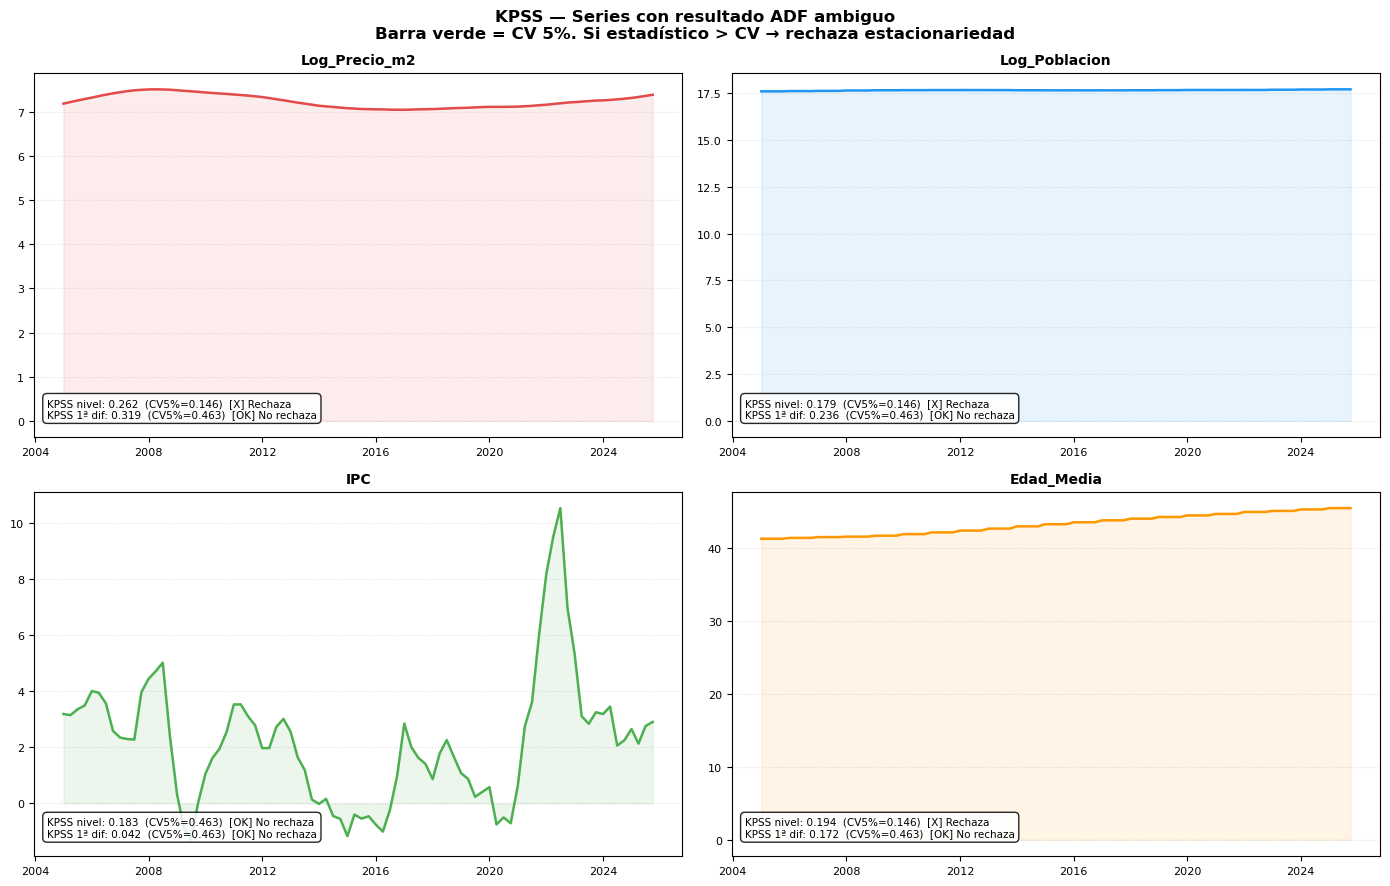


  >> Gráfico guardado: kpss_ambiguos.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import kpss, adfuller
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────
# 1. CARGA Y PREPARACIÓN
# ─────────────────────────────────────────────────────────────
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro','Indice_Mano_Obra','Indice_Materiales',
                'IPC','PIB_pc','Transmisiones_Total','Pob_Ext']
for c in cols_to_fill:
    if c in df.columns:
        df[c] = df.groupby('Provincia')[c].transform(lambda x: x.ffill().bfill())
df = df.dropna().reset_index(drop=True)

df_nac = df.groupby('Trimestre').agg({
    'Precio_m2':'mean','Poblacion':'sum','IPC':'mean','Edad_Media':'mean'
}).reset_index().set_index('Trimestre')
df_nac.index = pd.DatetimeIndex(df_nac.index, freq='QS')

# 'ct' para series con tendencia visible, 'c' para el IPC (fluctúa en torno a media)
series_kpss = {
    'Log_Precio_m2': (np.log(df_nac['Precio_m2']), 'ct'),
    'Log_Poblacion':  (np.log(df_nac['Poblacion']),  'ct'),
    'IPC':            (df_nac['IPC'],                 'c'),
    'Edad_Media':     (df_nac['Edad_Media'],           'ct'),
}

# Resultados ADF previos (para el cuadro comparativo final)
adf_previo = {
    'Log_Precio_m2': ('[!]  No concluyente',  0.6243),
    'Log_Poblacion':  ('[!]  No concluyente',  0.3931),
    'IPC':            ('[OK]  I(0) p=0.006',     0.0061),
    'Edad_Media':     ('[!]  No concluyente',  0.8642),
}

# ─────────────────────────────────────────────────────────────
# 2. FUNCIÓN KPSS
# ─────────────────────────────────────────────────────────────
# Nota: statsmodels limita el p-valor de KPSS a [0.01, 0.10]
# cuando cae fuera de los valores tabulados. Se indica con ≤/≥.
def run_kpss(arr, reg):
    stat, pval, lags, cvs = kpss(arr, regression=reg, nlags='auto')
    bounded = '≤0.01' if pval <= 0.01 else ('≥0.10' if pval >= 0.10 else f'{pval:.4f}')
    rechaza = pval < 0.05   # rechaza H₀ de estacionariedad → no estacionaria
    return stat, pval, bounded, lags, cvs['5%'], rechaza

def run_adf(arr, reg):
    res  = adfuller(arr, regression=reg)
    return res[0], res[1], res[4]['5%']

# ─────────────────────────────────────────────────────────────
# 3. EJECUTAR Y MOSTRAR
# ─────────────────────────────────────────────────────────────
print("=" * 80)
print("  TEST KPSS — Confirmación de orden de integración")
print("  H₀ KPSS: serie ESTACIONARIA  |  H₀ ADF: serie tiene RAÍZ UNITARIA")
print("  Marco combinado ADF+KPSS para diagnóstico robusto")
print("=" * 80)

resumen = []

for name, (serie, reg) in series_kpss.items():
    arr   = serie.dropna().values
    arr_d = np.diff(arr)

    # KPSS en nivel y en 1ª diferencia
    s_n,  p_n,  pb_n,  lag_n,  cv5_n,  rej_n  = run_kpss(arr,   reg)
    s_d,  p_d,  pb_d,  lag_d,  cv5_d,  rej_d  = run_kpss(arr_d, 'c')
    # ADF en nivel (para el cuadro combinado)
    adf_s, adf_p, adf_cv = run_adf(arr, reg)
    adf_rej = adf_p < 0.05   # rechaza H₀ raíz unitaria → estacionaria

    print(f"\n  {'─'*76}")
    print(f"  >> {name}  (regresión KPSS: '{reg}')")
    print(f"  {'─'*76}")
    print(f"  {'Test':<10} {'Serie':<12} {'Estadístico':>13} {'p-valor':>10} "
          f"{'CV 5%':>8} {'Lags':>6}  Resultado")
    print(f"  {'·'*76}")

    # KPSS nivel
    r_n = "[X] Rechaza H₀ → NO estacionaria" if rej_n else "[OK] No rechaza H₀ → Estacionaria"
    print(f"  {'KPSS':<10} {'Nivel':<12} {s_n:>13.4f} {pb_n:>10} "
          f"{cv5_n:>8.4f} {lag_n:>6}  {r_n}")

    # KPSS 1ª dif
    r_d = "[X] Rechaza H₀ → NO estacionaria" if rej_d else "[OK] No rechaza H₀ → Estacionaria"
    print(f"  {'KPSS':<10} {'1ª Dif':<12} {s_d:>13.4f} {pb_d:>10} "
          f"{cv5_d:>8.4f} {lag_d:>6}  {r_d}")

    # ADF nivel (recordatorio)
    r_adf = "Rechaza H₀ → Estacionaria" if adf_rej else "No rechaza H₀ → Raíz unitaria"
    print(f"  {'ADF':<10} {'Nivel':<12} {adf_s:>13.4f} {adf_p:>10.4f} "
          f"{adf_cv:>8.4f} {'—':>6}  {'[OK]' if adf_rej else '[X]'} {r_adf}")

    # ── Marco combinado ADF + KPSS ──────────────────────────────────────
    # Cuadrante ADF rechaza / KPSS no rechaza → I(0) confirmada
    # Cuadrante ADF no rechaza / KPSS rechaza → I(1) confirmada
    # Ambos rechazan / ambos no rechazan → inconcluso
    if not adf_rej and rej_n and not rej_d:
        veredicto  = "[I(1)]  I(1) CONFIRMADA — ADF no rechaza raíz unitaria + KPSS rechaza estacionariedad en nivel + 1ª dif estacionaria"
        orden_int  = "I(1)"
    elif adf_rej and not rej_n:
        veredicto  = "[I(0)]  I(0) CONFIRMADA — ADF rechaza raíz unitaria + KPSS no rechaza estacionariedad"
        orden_int  = "I(0)"
    elif adf_rej and rej_n:
        veredicto  = "[?]  INCONCLUSO — ambos rechazan H₀ → posible ruptura estructural o estacionariedad en torno a tendencia"
        orden_int  = "Inconcluso"
    else:
        veredicto  = "[?]  INCONCLUSO — ninguno rechaza con claridad → muestra pequeña o proceso cerca del límite"
        orden_int  = "Inconcluso"

    print(f"\n  >>  {veredicto}")

    resumen.append({
        'Variable':        name,
        'ADF nivel':       adf_previo[name][0],
        'KPSS nivel':      f"{'Rechaza' if rej_n else 'No rechaza'}  (p{pb_n})",
        'KPSS 1ª dif':     f"{'Rechaza' if rej_d else 'No rechaza'}  (p{pb_d})",
        'Orden final':     orden_int,
    })

# ─────────────────────────────────────────────────────────────
# 4. TABLA RESUMEN FINAL
# ─────────────────────────────────────────────────────────────
print("\n\n" + "=" * 80)
print("  TABLA RESUMEN — ADF + KPSS + Zivot-Andrews")
print("=" * 80)
print(f"\n  {'Variable':<18} {'ADF':<22} {'KPSS nivel':<26} {'KPSS 1ª dif':<24} {'Conclusión'}")
print(f"  {'─'*106}")
iconos = {'I(1)': '[I(1)] I(1)', 'I(0)': '[I(0)] I(0)', 'Inconcluso': '[?] Inconcluso'}
for r in resumen:
    print(f"  {r['Variable']:<18} {r['ADF nivel']:<22} {r['KPSS nivel']:<26} "
          f"{r['KPSS 1ª dif']:<24} {iconos[r['Orden final']]}")

# Añadir Tasa_Paro (resuelta por ZA)
print(f"  {'Tasa_Paro':<18} {'[OK] I(0) p=0.009':<22} {'— (resuelta por ZA)':<26} "
      f"{'—':<24} [?] I(0) con ruptura 2011-12")

# ─────────────────────────────────────────────────────────────
# 5. GRÁFICO
# ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('KPSS — Series con resultado ADF ambiguo\n'
             'Barra verde = CV 5%. Si estadístico > CV → rechaza estacionariedad',
             fontsize=12, fontweight='bold')
axes = axes.flatten()

colores = {'Log_Precio_m2':'#E24B4A','Log_Poblacion':'#2196F3',
           'IPC':'#4CAF50','Edad_Media':'#FF9800'}

for ax, (name, (serie, reg)) in zip(axes, series_kpss.items()):
    arr   = serie.dropna().values
    arr_d = np.diff(arr)
    s_n, _, _, _, cv5_n, rej_n = run_kpss(arr,   reg)
    s_d, _, _, _, cv5_d, rej_d = run_kpss(arr_d, 'c')

    # Serie temporal
    ax.plot(serie.dropna().index, arr, color=colores[name], linewidth=1.8)
    ax.fill_between(serie.dropna().index, arr, alpha=0.1, color=colores[name])
    ax.set_title(name, fontsize=10, fontweight='bold')
    ax.tick_params(labelsize=8)
    ax.grid(axis='y', linestyle=':', alpha=0.4)

    # Recuadro con estadísticos KPSS
    txt = (f"KPSS nivel: {s_n:.3f}  (CV5%={cv5_n:.3f})  "
           f"{'[X] Rechaza' if rej_n else '[OK] No rechaza'}\n"
           f"KPSS 1ª dif: {s_d:.3f}  (CV5%={cv5_d:.3f})  "
           f"{'[X] Rechaza' if rej_d else '[OK] No rechaza'}")
    ax.text(0.02, 0.05, txt, transform=ax.transAxes, fontsize=7.5,
            va='bottom', bbox=dict(boxstyle='round,pad=0.4', fc='white', alpha=0.85))

plt.tight_layout()
#plt.savefig('kpss_ambiguos.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n  >> Gráfico guardado: kpss_ambiguos.png")

  TEST DE ZIVOT-ANDREWS — Tasa de Desempleo Nacional
  Serie: 2005-01-01 → 2025-10-01
  Nº observaciones: 84

  Modelo 'c': Ruptura en constante (nivel)
    Estadístico ZA : -4.3956
    p-valor        : 0.1536
    Lags utilizados: 4
    Fecha de ruptura: 2008-01-01
    Valores críticos: 1%=-5.2764  5%=-4.8107  10%=-4.5662
    Conclusión     : ❌ No rechaza H₀ → RAÍZ UNITARIA

  Modelo 't': Ruptura en tendencia
    Estadístico ZA : -6.0068
    p-valor        : 0.0034
    Lags utilizados: 4
    Fecha de ruptura: 2012-07-01
    Valores críticos: 1%=-5.0342  5%=-4.4058  10%=-4.1368
    Conclusión     : ✅ Rechaza H₀ → ESTACIONARIA con ruptura

  Modelo 'ct': Ruptura en constante y tendencia
    Estadístico ZA : -6.3328
    p-valor        : 0.0013
    Lags utilizados: 4
    Fecha de ruptura: 2011-04-01
    Valores críticos: 1%=-5.5756  5%=-5.0733  10%=-4.8267
    Conclusión     : ✅ Rechaza H₀ → ESTACIONARIA con ruptura

────────────────────────────────────────────────────────────
  Modelo   E

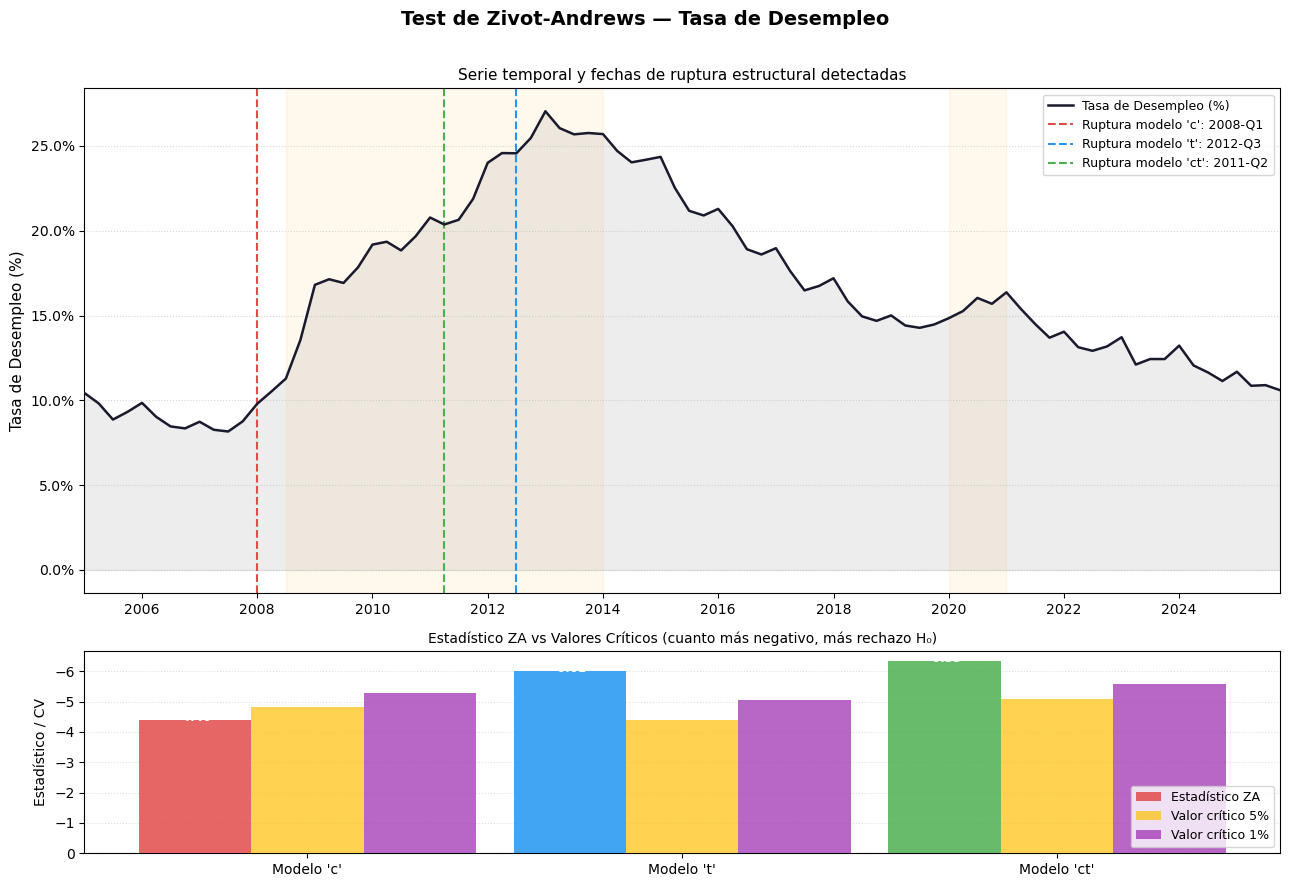


  📊 Gráfico guardado: zivot_andrews_tasa_paro.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from statsmodels.tsa.stattools import zivot_andrews
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────
# 1. CARGA Y PREPARACIÓN
# ─────────────────────────────────────────────────────────────
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

serie = (
    df.groupby('Trimestre')['Tasa_Paro']
    .mean()
    .sort_index()
    .dropna()
)
serie.index = pd.DatetimeIndex(serie.index, freq='QS')

print("=" * 60)
print("  TEST DE ZIVOT-ANDREWS — Tasa de Desempleo Nacional")
print("=" * 60)
print(f"  Serie: {serie.index[0].date()} → {serie.index[-1].date()}")
print(f"  Nº observaciones: {len(serie)}")
print()

# ─────────────────────────────────────────────────────────────
# 2. TEST EN LAS TRES ESPECIFICACIONES
# ─────────────────────────────────────────────────────────────
# trimestres óptimos (max_lags=None → criterio AIC automático)
especificaciones = {
    'c': 'Ruptura en constante (nivel)',
    't': 'Ruptura en tendencia',
    'ct': 'Ruptura en constante y tendencia'
}

resultados = {}

arr = np.asarray(serie.values, dtype=float)  # statsmodels 0.14 requiere numpy array

for modelo, descripcion in especificaciones.items():
    # En statsmodels 0.14 el orden de retorno es:
    # (stat, pvalue, critvals_dict, lags_used, breakpoint_idx)
    stat, pval, cvs, lags_used, bp_idx = zivot_andrews(
        arr, trim=0.15, maxlag=4, regression=modelo
    )
    bp_fecha = serie.index[bp_idx]
    resultados[modelo] = {
        'descripcion':      descripcion,
        'estadistico':      stat,
        'p_valor':          pval,
        'lags_usados':      lags_used,
        'breakpoint_idx':   bp_idx,
        'breakpoint_fecha': bp_fecha,
        'cv_1pct':          cvs['1%'],
        'cv_5pct':          cvs['5%'],
        'cv_10pct':         cvs['10%'],
    }

    conclusion = (
        "Rechaza H₀ → ESTACIONARIA con ruptura"
        if stat < cvs['5%']
        else "No rechaza H₀ → RAÍZ UNITARIA"
    )

    print(f"  Modelo '{modelo}': {descripcion}")
    print(f"    Estadístico ZA : {stat:.4f}")
    print(f"    p-valor        : {pval:.4f}")
    print(f"    Lags utilizados: {lags_used}")
    print(f"    Fecha de ruptura: {bp_fecha.date()}")
    print(f"    Valores críticos: 1%={cvs['1%']:.4f}  5%={cvs['5%']:.4f}  10%={cvs['10%']:.4f}")
    print(f"    Conclusión     : {conclusion}")
    print()

# ─────────────────────────────────────────────────────────────
# 3. TABLA RESUMEN
# ─────────────────────────────────────────────────────────────
print("─" * 60)
print(f"  {'Modelo':<6} {'Estadístico':>13} {'p-valor':>9} {'Ruptura':>12} {'CV 5%':>8}  Conclusión")
print("─" * 60)
for m, r in resultados.items():
    ok = "Estacionaria" if r['estadistico'] < r['cv_5pct'] else "Raíz unitaria"
    print(f"  {m:<6} {r['estadistico']:>13.4f} {r['p_valor']:>9.4f} "
          f"{str(r['breakpoint_fecha'].date()):>12} {r['cv_5pct']:>8.4f}  {ok}")
print("─" * 60)

# ─────────────────────────────────────────────────────────────
# 4. GRÁFICO
# ─────────────────────────────────────────────────────────────
colores_modelo = {'c': '#E24B4A', 't': '#2196F3', 'ct': '#4CAF50'}
CRISIS_LABELS  = {
    '2008-10-01': 'Crisis Financiera',
    '2020-04-01': 'COVID-19',
}

fig, axes = plt.subplots(2, 1, figsize=(13, 9),
                         gridspec_kw={'height_ratios': [2.5, 1]})
fig.suptitle('Test de Zivot-Andrews — Tasa de Desempleo', fontsize=14, fontweight='bold', y=0.98)

# ── Panel superior: serie + líneas de ruptura ─────────────────
ax1 = axes[0]
ax1.plot(serie.index, serie.values, color='#1A1A2E', linewidth=1.8,
         label='Tasa de Desempleo (%)', zorder=3)
ax1.fill_between(serie.index, serie.values, alpha=0.08, color='#1A1A2E')

for m, r in resultados.items():
    ax1.axvline(r['breakpoint_fecha'], color=colores_modelo[m],
                linestyle='--', linewidth=1.5,
                label=f"Ruptura modelo '{m}': {r['breakpoint_fecha'].strftime('%Y-Q%q')[:-1]}{(r['breakpoint_fecha'].month-1)//3+1}")

# Sombreado periodos de crisis conocidos
periodos_crisis = [('2008-07-01', '2014-01-01'), ('2020-01-01', '2021-01-01')]
for ini, fin in periodos_crisis:
    ax1.axvspan(pd.Timestamp(ini), pd.Timestamp(fin),
                alpha=0.07, color='orange', zorder=1)

ax1.set_ylabel('Tasa de Desempleo (%)', fontsize=11)
ax1.set_title('Serie temporal y fechas de ruptura estructural detectadas', fontsize=11)
ax1.legend(fontsize=9, loc='upper right')
ax1.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f%%'))
ax1.grid(axis='y', linestyle=':', alpha=0.5)
ax1.set_xlim(serie.index[0], serie.index[-1])

# ── Panel inferior: estadísticos vs valores críticos ─────────────
ax2 = axes[1]
modelos = list(resultados.keys())
stats   = [resultados[m]['estadistico'] for m in modelos]
cv5     = [resultados[m]['cv_5pct']     for m in modelos]
cv1     = [resultados[m]['cv_1pct']     for m in modelos]

x = np.arange(len(modelos))
w = 0.3
bars = ax2.bar(x, stats, width=w, color=[colores_modelo[m] for m in modelos],
               alpha=0.85, label='Estadístico ZA', zorder=3)
ax2.bar(x + w, cv5, width=w, color='#FFC107', alpha=0.7, label='Valor crítico 5%', zorder=3)
ax2.bar(x + 2*w, cv1, width=w, color='#9C27B0', alpha=0.7, label='Valor crítico 1%', zorder=3)

for bar, val in zip(bars, stats):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 0.3,
             f'{val:.2f}', ha='center', va='top', fontsize=8.5, color='white', fontweight='bold')

ax2.set_xticks(x + w)
ax2.set_xticklabels([f"Modelo '{m}'" for m in modelos], fontsize=10)
ax2.set_ylabel('Estadístico / CV', fontsize=10)
ax2.set_title('Estadístico ZA vs Valores Críticos (cuanto más negativo, más rechazo H₀)', fontsize=10)
ax2.legend(fontsize=9, loc='lower right')
ax2.grid(axis='y', linestyle=':', alpha=0.4)
ax2.invert_yaxis()   # más negativo = arriba (más rechazo)

plt.tight_layout(rect=[0, 0, 1, 0.97])
#plt.savefig('zivot_andrews_tasa_paro.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n  📊 Gráfico guardado: zivot_andrews_tasa_paro.png")

| Variable | Transformación | Test(s) | Resultado nivel | Resultado 1ª dif | Orden |
|---|---|---|---|---|---|
| Hipotecas_Total | Log | ADF | p = 0.9845 | p = 0.0000 | I(1) |
| PIB_pc | Log | ADF | p = 0.8973 | p = 0.0000 | I(1) |
| Transmisiones_Total | Log | ADF | p = 0.2866 | p = 0.0106 | I(1) |
| Indice_Mano_Obra | Log | ADF | p = 0.5822 | p = 0.0136 | I(1) |
| Indice_Materiales | Log | ADF | p = 0.1997 | p = 0.0000 | I(1) |
| Euribor | Nivel | ADF | p = 0.3368 | p = 0.0001 | I(1) |
| Spread_Hipotecas | Nivel | ADF | p = 0.5950 | p = 0.0000 | I(1) |
| Precio_m2 | Log | ADF + KPSS | ADF no rechaza / KPSS rechaza estacionariedad | KPSS no rechaza | I(1) |
| Poblacion | Log | ADF + KPSS | ADF no rechaza / KPSS rechaza estacionariedad | KPSS no rechaza | I(1) |
| Edad_Media | Nivel | ADF + KPSS | ADF no rechaza / KPSS rechaza estacionariedad | KPSS no rechaza | I(1) |
| IPC | Nivel* | ADF + KPSS | ADF p = 0.0231 / KPSS no rechaza | — | I(0) |
| tasa_ahorro | Nivel | ADF | p = 0.0269 | — | I(0) |
| Tasa_Paro | Nivel | ADF + Zivot-Andrews | ADF p = 0.0086 / ZA rechaza H0 modelos t y ct | — | I(0) con ruptura estructural 2011-2012 |

### 7.3 Test de Cointegración de Johansen
Verificamos si existen relaciones de largo plazo (cointegración) entre las variables del mercado hipotecario. La cointegración permite usar el modelo VECM.

In [43]:
import pandas as pd
import numpy as np
from statsmodels.tsa.vector_ar.vecm import coint_johansen

# 1. PREPARAR DATOS (NIVEL NACIONAL)
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

# Relleno de Nulos
cols_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc', 'Pob_Ext']
for col in cols_fill:
    if col in df.columns:
        df[col] = df.groupby('Provincia')[col].transform(lambda x: x.ffill().bfill())

# Agregación Nacional (Solo las variables candidatas I(1))
df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'PIB_pc': 'mean',
    'Euribor': 'mean',
    'Indice_Materiales': 'mean' # Lado de la Oferta (Costes)
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. CONSTRUIR EL SISTEMA DE VARIABLES I(1) EN NIVELES
# Johansen requiere que entren en Niveles (Logaritmos si procede), NO diferenciadas.
df_johansen = pd.DataFrame()
df_johansen['Log_Hipotecas'] = np.log(df_nacional['Hipotecas_Total'])
df_johansen['Log_PIB_pc'] = np.log(df_nacional['PIB_pc'])
df_johansen['Euribor'] = df_nacional['Euribor'] 
df_johansen['Log_Materiales'] = np.log(df_nacional['Indice_Materiales'])

# 3. EJECUTAR EL TEST DE JOHANSEN
# k_ar_diff=1 implica 1 retardo en diferencias (lo estándar para datos trimestrales suaves)
# det_order=0 asume constante en la relación de cointegración
res = coint_johansen(df_johansen, det_order=0, k_ar_diff=1)

# 4. IMPRIMIR RESULTADOS "TRIBUNAL-READY"
print(f"--- TEST DE JOHANSEN: VARIABLES I(1) SELECCIONADAS ---")
print(f"Sistema: {list(df_johansen.columns)}\n")

output = []
for i in range(len(res.lr1)):
    traza = res.lr1[i]
    critico_95 = res.cvt[i, 1] # Valor crítico al 95%
    max_eigen = res.lr2[i]
    critico_eigen_95 = res.cvm[i, 1]

    # Decisión (Si el estadístico > valor crítico, rechazamos H0: no hay cointegración)
    if traza > critico_95:
        decision = "**SI Existe Cointegración** (Rechazamos r<=i)"
    else:
        decision = "No hay evidencia suficiente"

    output.append({
        'H0 (Rango)': f"r <= {i}",
        'Estadístico Traza': f"{traza:.2f}",
        'Valor Crítico 95%': f"{critico_95:.2f}",
        'Conclusión': decision
    })

# Formato Tabla
df_res = pd.DataFrame(output)
print(df_res.to_string(index=False))

print("\nINTERPRETACIÓN PARA EL TFM:")
if any("SI Existe" in x for x in df_res['Conclusión']):
    print("¡ÉXITO! El test confirma que existe al menos una relación de equilibrio a largo plazo.")
    print("Esto justifica usar un modelo VECM (Vector Error Correction Model) en lugar de un VAR simple.")
    print("Significado: Aunque Hipotecas, PIB y Euribor fluctúen, están 'atados' por una cuerda invisible.")
else:
    print("RESULTADO: No se encontró cointegración clara con estos lags.")
    print("Recomendación: Usar un VAR mixto en niveles y en Diferencias (VAR-Diff) o confiar en el Machine Learning que no asume equilibrio.")

--- TEST DE JOHANSEN: VARIABLES I(1) SELECCIONADAS ---
Sistema: ['Log_Hipotecas', 'Log_PIB_pc', 'Euribor', 'Log_Materiales']

H0 (Rango) Estadístico Traza Valor Crítico 95%                  Conclusión
    r <= 0             39.55             47.85 No hay evidencia suficiente
    r <= 1             21.47             29.80 No hay evidencia suficiente
    r <= 2              5.20             15.49 No hay evidencia suficiente
    r <= 3              0.06              3.84 No hay evidencia suficiente

INTERPRETACIÓN PARA EL TFM:
RESULTADO: No se encontró cointegración clara con estos lags.
Recomendación: Usar un VAR mixto en niveles y en Diferencias (VAR-Diff) o confiar en el Machine Learning que no asume equilibrio.


In [47]:
import pandas as pd
import numpy as np
from statsmodels.tsa.vector_ar.var_model import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen
import warnings
warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────
# 1. PREPARAR DATOS
# ─────────────────────────────────────────────────────────────
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])

cols_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc', 'Pob_Ext', 'Precio_m2']
for col in cols_fill:
    if col in df.columns:
        df[col] = df.groupby('Provincia')[col].transform(lambda x: x.ffill().bfill())

df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total':   'sum',
    'PIB_pc':            'mean',
    'Precio_m2':         'mean',
    'Euribor':           'mean',
    'Indice_Materiales': 'mean',
}).reset_index().set_index('Trimestre')

# Variables I(1) en niveles (logaritmos donde procede)
# Confirmado por ADF + KPSS: todas I(1)
# Euribor en niveles (no admite log por valores negativos 2014-2022)
# VIF max=5.47, condition number=5.5 -> sin multicolinealidad problematica
df_johansen = pd.DataFrame({
    'Log_Hipotecas':  np.log(df_nacional['Hipotecas_Total']),
    'Log_PIB_pc':     np.log(df_nacional['PIB_pc']),
    'Log_Precio_m2':  np.log(df_nacional['Precio_m2']),
    'Euribor':        df_nacional['Euribor'],
    'Log_Materiales': np.log(df_nacional['Indice_Materiales']),
})
df_johansen = df_johansen.dropna()   # elimina NaN antes del test

print("=" * 65)
print("  TEST DE JOHANSEN — Cointegración entre variables I(1)")
print("=" * 65)
print(f"  Sistema  : {list(df_johansen.columns)}")
print(f"  Muestra  : {df_johansen.index[0].date()} -> {df_johansen.index[-1].date()}")
print(f"  Obs.     : {len(df_johansen)}")

# ─────────────────────────────────────────────────────────────
# 2. SELECCIÓN DE LAGS (criterio de información del VAR)
# ─────────────────────────────────────────────────────────────
sel = VAR(df_johansen).select_order(maxlags=6)
lag_var   = sel.aic          # lags óptimos del VAR según AIC
k_ar_diff = lag_var - 1      # Johansen usa lags en diferencias = VAR lags - 1
k_ar_diff = max(1, k_ar_diff)

print(f"\n  Seleccion de lags (AIC = BIC = {lag_var}) -> k_ar_diff = {k_ar_diff}")
print(f"  det_order = 0  (constante restringida a la relacion de cointegracion)\n")

# ─────────────────────────────────────────────────────────────
# 3. TEST DE JOHANSEN
# ─────────────────────────────────────────────────────────────
# det_order=0: constante dentro de la relacion de cointegracion (lo estandar
#              cuando las series tienen nivel pero no tendencia estocastica libre)
res = coint_johansen(df_johansen, det_order=0, k_ar_diff=k_ar_diff)

n_vars = len(df_johansen.columns)
rows   = []

for i in range(n_vars):
    traza     = res.lr1[i];  cv_traza  = res.cvt[i, 1]   # indice 1 = 95%
    max_eig   = res.lr2[i];  cv_eigen  = res.cvm[i, 1]

    dec_traza = "Rechaza H0" if traza   > cv_traza else "No rechaza"
    dec_eigen = "Rechaza H0" if max_eig > cv_eigen else "No rechaza"

    rows.append({
        'H0 (rango)':       f"r <= {i}",
        'Traza':            round(traza,   2),
        'CV Traza 95%':     round(cv_traza, 2),
        'Decision Traza':   dec_traza,
        'Max Autovalor':    round(max_eig,  2),
        'CV Max-Eig 95%':   round(cv_eigen, 2),
        'Decision Max-Eig': dec_eigen,
    })

df_res = pd.DataFrame(rows)
print(df_res.to_string(index=False))

# ─────────────────────────────────────────────────────────────
# 4. RANGO DE COINTEGRACION
# ─────────────────────────────────────────────────────────────
# El rango es el numero de hipotesis H0 consecutivas rechazadas desde r=0
rango = sum(
    1 for i in range(n_vars)
    if res.lr1[i] > res.cvt[i, 1] and res.lr2[i] > res.cvm[i, 1]
)

print("\n" + "=" * 65)
print(f"  RANGO DE COINTEGRACION: r = {rango}")
print("=" * 65)

if rango == 0:
    print("  No existe cointegracion.")
    print("  Recomendacion: VAR en primeras diferencias.")
elif rango == n_vars:
    print("  Rango pleno: todas las variables son estacionarias.")
    print("  Revisar el orden de integracion — posible error previo.")
else:
    print(f"  Existen {rango} relacion(es) de equilibrio a largo plazo.")
    print(f"  Recomendacion: VECM con r = {rango}.")
    print()
    print("  Vectores de cointegracion (beta):")
    beta = pd.DataFrame(
        res.evec[:, :rango],
        index=df_johansen.columns,
        columns=[f"CV {j+1}" for j in range(rango)]
    )
    print(beta.round(4).to_string())
    print()
    print("  Velocidades de ajuste (alpha):")
    alpha = pd.DataFrame(
        res.ca[:rango, :].T if hasattr(res, 'ca') else np.full((n_vars, rango), np.nan),
        index=df_johansen.columns,
        columns=[f"Alpha CV{j+1}" for j in range(rango)]
    )
    # alpha no esta disponible directamente en coint_johansen de statsmodels;
    # se obtiene estimando el VECM completo:
    from statsmodels.tsa.vector_ar.vecm import VECM
    vecm_fit = VECM(df_johansen, k_ar_diff=k_ar_diff, coint_rank=rango,
                    deterministic='co').fit()
    alpha_df = pd.DataFrame(
        vecm_fit.alpha,
        index=df_johansen.columns,
        columns=[f"Alpha CV{j+1}" for j in range(rango)]
    )
    print(alpha_df.round(4).to_string())
    print()
    print("  Interpretacion de alpha:")
    print("  Valor negativo y significativo -> la variable corrige desviaciones")
    print("  del equilibrio a largo plazo (velocidad de ajuste al VECM).")

  TEST DE JOHANSEN — Cointegración entre variables I(1)
  Sistema  : ['Log_Hipotecas', 'Log_PIB_pc', 'Log_Precio_m2', 'Euribor', 'Log_Materiales']
  Muestra  : 2005-01-01 -> 2025-10-01
  Obs.     : 84

  Seleccion de lags (AIC = BIC = 2) -> k_ar_diff = 1
  det_order = 0  (constante restringida a la relacion de cointegracion)

H0 (rango)  Traza  CV Traza 95% Decision Traza  Max Autovalor  CV Max-Eig 95% Decision Max-Eig
    r <= 0  92.89         69.82     Rechaza H0          46.45           33.88       Rechaza H0
    r <= 1  46.45         47.85     No rechaza          18.00           27.59       No rechaza
    r <= 2  28.45         29.80     No rechaza          15.89           21.13       No rechaza
    r <= 3  12.56         15.49     No rechaza          12.00           14.26       No rechaza
    r <= 4   0.56          3.84     No rechaza           0.56            3.84       No rechaza

  RANGO DE COINTEGRACION: r = 1
  Existen 1 relacion(es) de equilibrio a largo plazo.
  Recomendacion

## 8. Modelo VAR — Funciones de Impulso-Respuesta (IRF)

### 8.1 IRF — Dinámica ante Shocks Macroeconómicos
Estimamos un modelo VAR para analizar cómo responde el volumen hipotecario ante shocks en el Euríbor, PIB y precio del m² a lo largo de 12 trimestres.

Ajustando el VAR y simulando shocks...


/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/vector_ar/var_model.py:1501: RuntimeWarning: divide by zero encountered in matmul
  return np.kron(np.linalg.inv(z.T @ z), self.sigma_u)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/vector_ar/var_model.py:1501: RuntimeWarning: overflow encountered in matmul
  return np.kron(np.linalg.inv(z.T @ z), self.sigma_u)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/vector_ar/var_model.py:1501: RuntimeWarning: invalid value encountered in matmul
  return np.kron(np.linalg.inv(z.T @ z), self.sigma_u)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/numpy/linalg/_linalg.py:3383: R

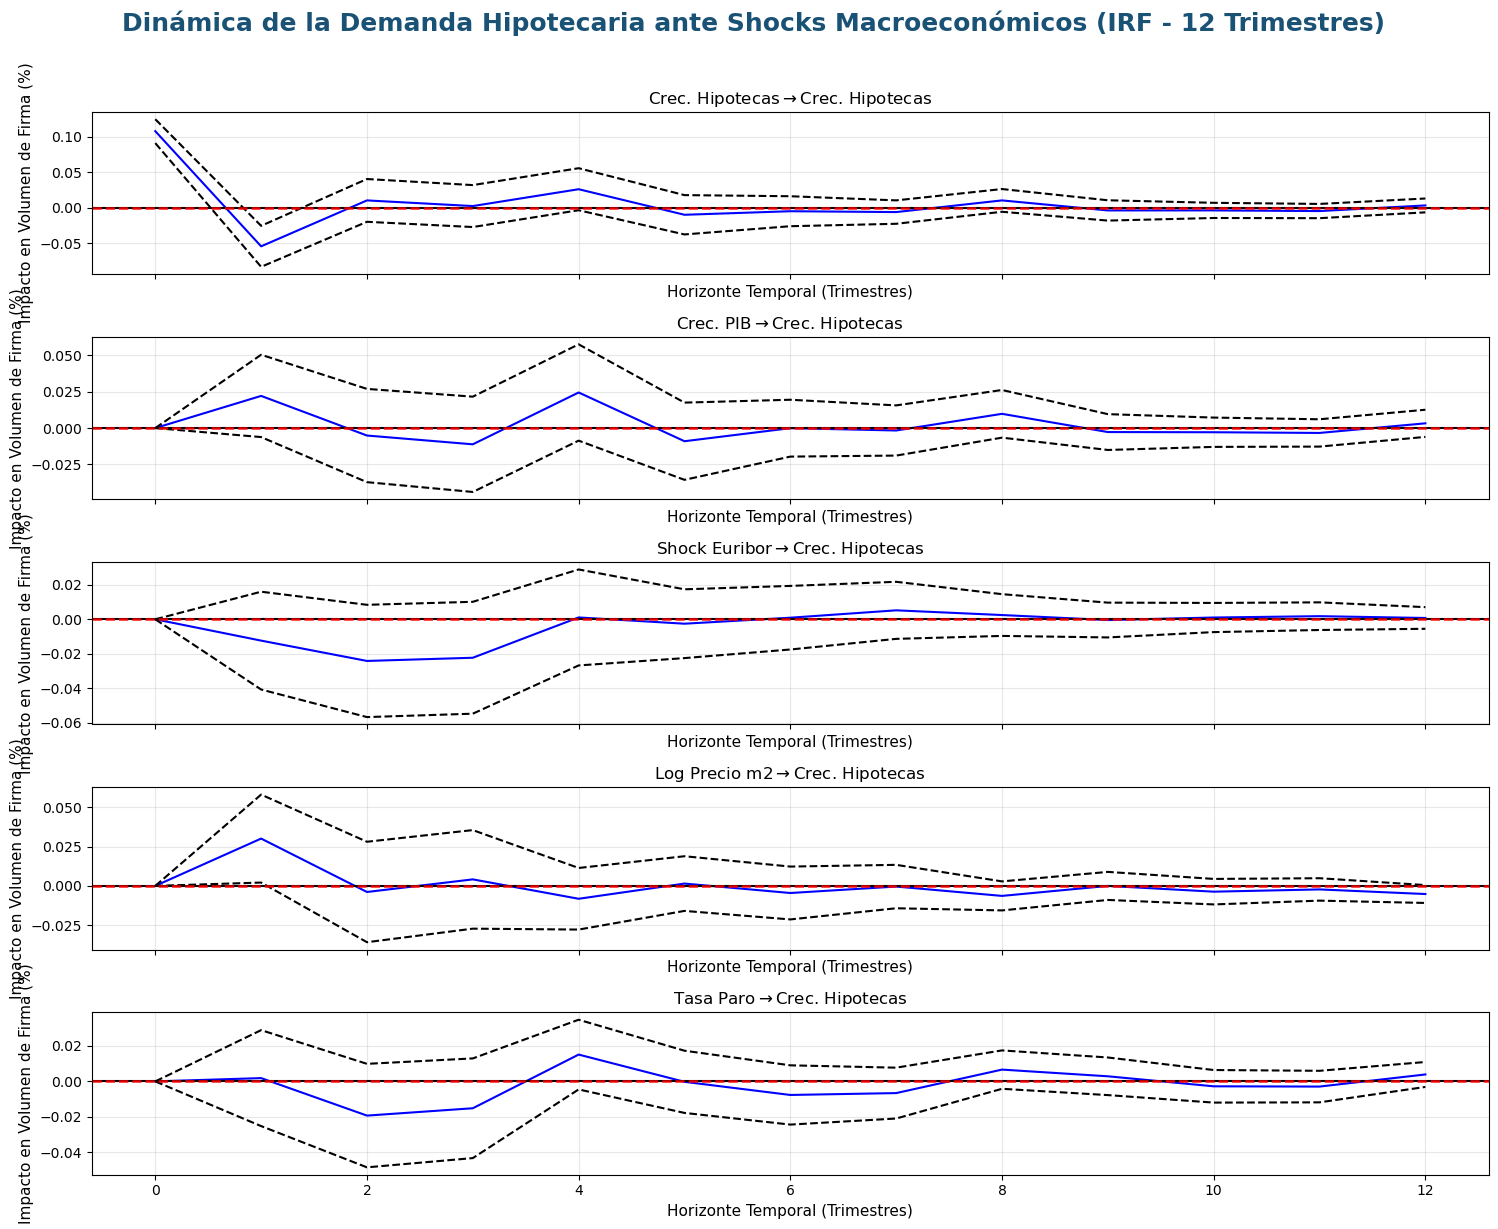

Matriz de IRFs generada y guardada como 'matriz_IRF_Hipotecas.png'.


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR

# 1. Cargar y agregar datos (Hipotecas a nivel total España)
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. DataFrame Estacionario Mixto (VAR) - Metodología Aprobada
df_var = pd.DataFrame(index=df_nacional.index)

# Variables I(1) se pasan a Diferencias (Log/Simples)
df_var['Crec. Hipotecas'] = np.log(df_nacional['Hipotecas_Total']).diff()
df_var['Crec. PIB'] = np.log(df_nacional['PIB_pc']).diff()
df_var['Shock Euribor'] = df_nacional['Euribor'].diff()

# Variables I(0) se mantienen en Niveles
df_var['Log Precio m2'] = np.log(df_nacional['Precio_m2'])
df_var['Tasa Paro'] = df_nacional['Tasa_Paro']

df_var = df_var.dropna()

# 3. Ajustar Modelo VAR (Memoria de 1 año = Lag 4)
print("Ajustando el VAR y simulando shocks...")
modelo_var = VAR(df_var)
res_var = modelo_var.fit(4)

# 4. Generar Funciones Impulso-Respuesta a 3 años (12 trimestres)
irf = res_var.irf(12)

# 5. Dibujar la matriz de gráficas (response='Crec. Hipotecas')
fig = irf.plot(response='Crec. Hipotecas', orth=True, figsize=(15, 12))

# 6. Formato Profesional de Negocio
fig.suptitle("Dinámica de la Demanda Hipotecaria ante Shocks Macroeconómicos (IRF - 12 Trimestres)",
             fontsize=18, fontweight='bold', color='#1a5276', y=1.02)

# Añadir etiquetas claras y el umbral de Cero (Línea Base)
axes = fig.get_axes()
for ax in axes:
    ax.axhline(0, color='red', linestyle='--', linewidth=1.8, alpha=0.9) # Eje Cero
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('Horizonte Temporal (Trimestres)', fontsize=11)
    ax.set_ylabel('Impacto en Volumen de Firma (%)', fontsize=11)

plt.tight_layout()
# plt.savefig('matriz_IRF_Hipotecas.png', dpi=300, bbox_inches='tight')  # desactivado: guardar imagen
plt.show()

print("Matriz de IRFs generada y guardada como 'matriz_IRF_Hipotecas.png'.")

### 8.2 Tabla IRF Escalada — Shock de 1 Unidad
Reescalamos las IRFs para simular el impacto de un shock exacto de 1 unidad (al estilo EViews), facilitando la comparación entre variables de distinta escala.

--- IMPACTO PORCENTUAL SOBRE LAS HIPOTECAS (ANTE UN SHOCK EXACTO DE 1 UNIDAD) ---
              Shock 1% en Crec_PIB  Shock 1% en Tasa_Paro  Shock 1% en Log_Precio_m2  Shock 1% en Shock_Euribor  Shock 1% en Crec_Hipotecas
Trimestre 0                 1.1180                 0.0043                     6.0405                    -0.0644                      1.0565
Trimestre 1                 0.3838                -0.0158                     1.7250                    -0.0130                     -0.7011
Trimestre 2                -0.1120                -0.0173                    -1.5189                    -0.1046                      0.1016
Trimestre 3                -0.4527                -0.0175                    -0.2427                    -0.0931                      0.0122
Trimestre 4                 1.3178                 0.0324                     0.8880                     0.0074                      0.2097
Trimestre 5                -0.4889                -0.0005                    -

/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/vector_ar/var_model.py:1501: RuntimeWarning: divide by zero encountered in matmul
  return np.kron(np.linalg.inv(z.T @ z), self.sigma_u)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/vector_ar/var_model.py:1501: RuntimeWarning: overflow encountered in matmul
  return np.kron(np.linalg.inv(z.T @ z), self.sigma_u)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/statsmodels/tsa/vector_ar/var_model.py:1501: RuntimeWarning: invalid value encountered in matmul
  return np.kron(np.linalg.inv(z.T @ z), self.sigma_u)
/opt/homebrew/anaconda3/envs/datascience/lib/python3.11/site-packages/numpy/linalg/_linalg.py:3383: R

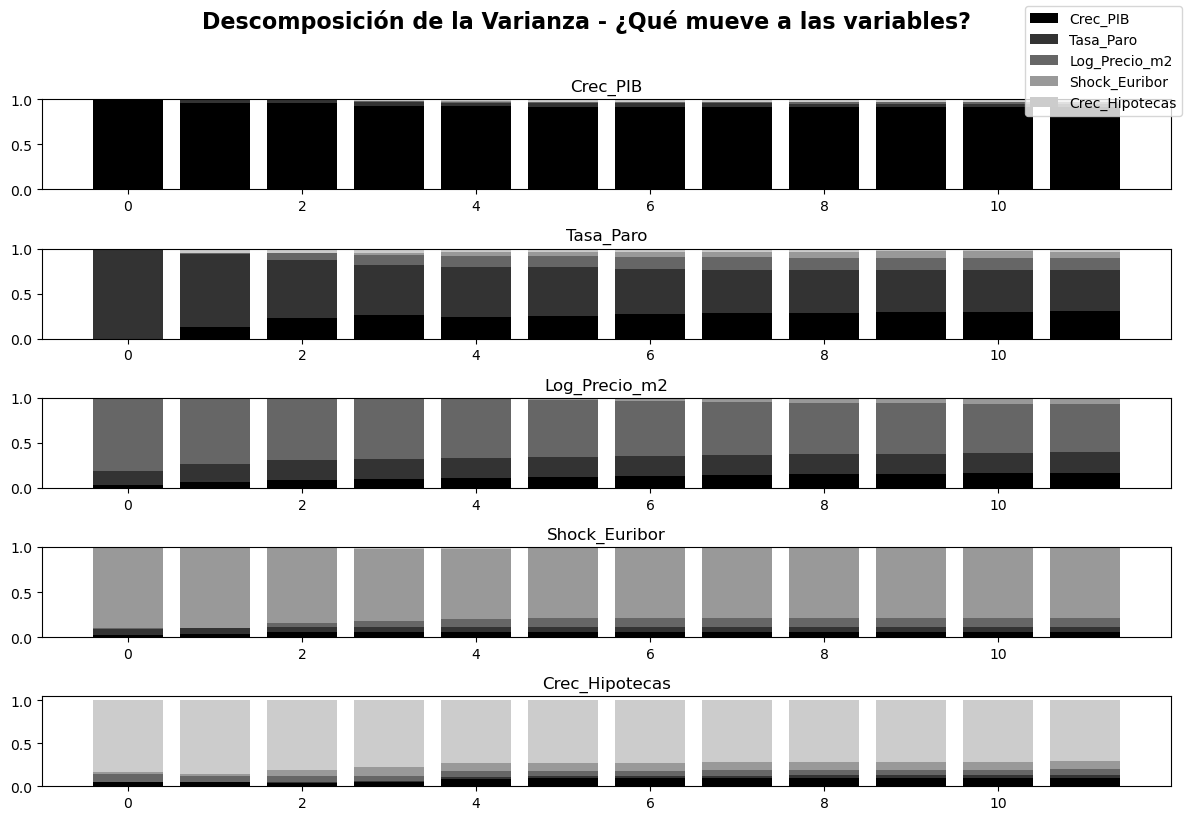

In [25]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR

# 1. Cargar datos
df = pd.read_csv('dataset_final_tfm.csv')
df['Trimestre'] = pd.to_datetime(df['Trimestre'])
cols_to_fill = ['tasa_ahorro', 'Indice_Mano_Obra', 'Indice_Materiales', 'IPC', 'PIB_pc']
df[cols_to_fill] = df.groupby('Provincia')[cols_to_fill].ffill().bfill()
df = df.dropna().reset_index(drop=True)

df_nacional = df.groupby('Trimestre').agg({
    'Hipotecas_Total': 'sum',
    'Euribor': 'mean',
    'Precio_m2': 'mean',
    'Tasa_Paro': 'mean',
    'PIB_pc': 'mean'
}).reset_index()
df_nacional.set_index('Trimestre', inplace=True)

# 2. EL ORDEN DE CHOLESKY CORRECTO (Macro -> Monetario -> Financiero)
df_var = pd.DataFrame(index=df_nacional.index)
df_var['Crec_PIB'] = np.log(df_nacional['PIB_pc']).diff()          # 1. Lo más lento
df_var['Tasa_Paro'] = df_nacional['Tasa_Paro']                     # 2. Rígido
df_var['Log_Precio_m2'] = np.log(df_nacional['Precio_m2'])         # 3. Precios
df_var['Shock_Euribor'] = df_nacional['Euribor'].diff()            # 4. Monetario
df_var['Crec_Hipotecas'] = np.log(df_nacional['Hipotecas_Total']).diff() # 5. Lo más reactivo (¡AL FINAL!)
df_var = df_var.dropna()

# 3. Ajustar el VAR y sacar la matriz cruda
modelo_var = VAR(df_var)
res_var = modelo_var.fit(4)
irf = res_var.irf(12)

# 4. Extraer Desviaciones Estándar (Tamaño natural del shock)
std_shocks = res_var.resid.std()

# 5. CONSTRUIR LA TABLA ESCALADA (Estilo EViews: Shock de 1%)
idx_hipo = df_var.columns.get_loc('Crec_Hipotecas')
tabla_irf_1pct = pd.DataFrame(index=[f"Trimestre {i}" for i in range(13)])

for col_impulso in df_var.columns:
    idx_impulso = df_var.columns.get_loc(col_impulso)
    # Extraemos el IRF crudo (Impacto sobre Hipotecas)
    respuesta_cruda = irf.orth_irfs[:, idx_hipo, idx_impulso]

    # REESCALAMOS: Dividimos la respuesta por el tamaño del shock para simular un shock de exactamente 1 Unidad (1%)
    respuesta_reescalada = respuesta_cruda / std_shocks[col_impulso]

    tabla_irf_1pct[f"Shock 1% en {col_impulso}"] = respuesta_reescalada

print("--- IMPACTO PORCENTUAL SOBRE LAS HIPOTECAS (ANTE UN SHOCK EXACTO DE 1 UNIDAD) ---")
print(tabla_irf_1pct.round(4).to_string())
# 6. Descomposición de la Varianza del Error de Predicción (FEVD)
# Calculamos a 12 trimestres vista
fevd = res_var.fevd(12)

# Imprimir el resumen numérico
print("\n--- DESCOMPOSICIÓN DE LA VARIANZA ---")
print(fevd.summary())

# Generar el gráfico (queda espectacular para la memoria del TFM)
fig = fevd.plot(figsize=(12, 8))
fig.suptitle("Descomposición de la Varianza - ¿Qué mueve a las variables?", 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

El modelo VECM que incluye otra variable más se hace en notebook a parte

## 6. Métricas Comparativas — Nivel Provincial

In [26]:
# ── Tabla de métricas provincial (todos los ML) ──
rows = []
for name in ['RF','XGB','LGBM','GBM','ElasticNet']:
    pred = results[name]['pred']
    mape = mean_absolute_percentage_error(y_te, pred)*100
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    r2 = r2_score(y_te, pred)
    mae = mean_absolute_error(y_te, pred)
    # Theil U2
    naive = df_test.merge(df_train.groupby('Provincia')['Hipotecas_Total'].last().reset_index(),
                          on='Provincia', suffixes=('','_naive'))
    if 'Hipotecas_Total_naive' in naive.columns:
        u2 = np.sqrt(mean_squared_error(y_te,pred)) / np.sqrt(mean_squared_error(y_te,naive['Hipotecas_Total_naive']))
    else:
        u2 = np.nan
    rows.append({'Modelo':name,'MAPE%':round(mape,2),'RMSE':round(rmse,0),
                 'R²':round(r2,4),'MAE':round(mae,0),'Theil_U2':round(u2,3)})

df_metrics = pd.DataFrame(rows).sort_values('MAPE%')
print("\n══════ BENCHMARK PROVINCIAL ══════")
print(df_metrics.to_string(index=False))
best_prov = df_metrics.iloc[0]['Modelo']
print(f"\n🏆 Mejor modelo provincial: {best_prov}")


══════ BENCHMARK PROVINCIAL ══════
    Modelo  MAPE%   RMSE     R²   MAE  Theil_U2
        RF  16.75  793.0 0.9603 421.0     0.622
       XGB  19.87 1169.0 0.9138 571.0     0.917
      LGBM  20.22  987.0 0.9386 520.0     0.774
       GBM  21.51 1344.0 0.8862 636.0     1.054
ElasticNet  49.21 1027.0 0.9336 657.0     0.805

🏆 Mejor modelo provincial: RF


## 7. Predicción Nacional — RF_Nac (Modelo Ganador)

El benchmark confirma que **RF_Nac** supera a todos los enfoques nacionales:
- MAPE **7.11%** frente al 9.68% del mejor modelo provincial agregado
- R² **0.40** positivo (único enfoque con varianza explicada real)

El resto del análisis nacional usa exclusivamente RF_Nac.



======== RF_NAC - MODELO GANADOR NACIONAL ========
  MAPE  : 7.11%
  RMSE  : 12,513
  R2    : 0.3995
  MAE   : 10,328


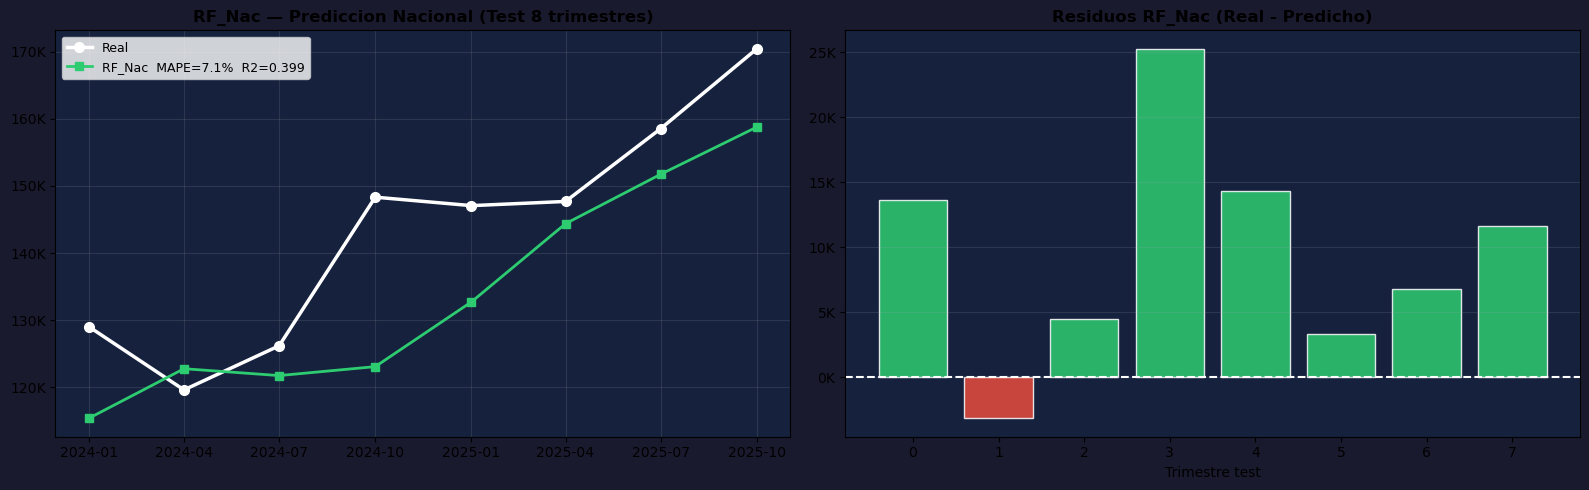

In [27]:
# ── Predicción nacional con RF_Nac (modelo ganador) ──
import matplotlib.ticker as mtick

rf_nac_pred = results_nac['RF_Nac']['pred']
rf_nac_real = results_nac['RF_Nac']['real']

mape_rfnac  = mean_absolute_percentage_error(rf_nac_real, rf_nac_pred)*100
rmse_rfnac  = np.sqrt(mean_squared_error(rf_nac_real, rf_nac_pred))
r2_rfnac    = r2_score(rf_nac_real, rf_nac_pred)
mae_rfnac   = np.mean(np.abs(rf_nac_real - rf_nac_pred))

print("======== RF_NAC - MODELO GANADOR NACIONAL ========")
print(f"  MAPE  : {mape_rfnac:.2f}%")
print(f"  RMSE  : {rmse_rfnac:,.0f}")
print(f"  R2    : {r2_rfnac:.4f}")
print(f"  MAE   : {mae_rfnac:,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor('#1a1a2e')
for ax in axes: ax.set_facecolor('#16213e')

ax = axes[0]
ax.plot(y_nac_te.index, rf_nac_real, 'w-o', lw=2.5, ms=7, label='Real')
ax.plot(y_nac_te.index, rf_nac_pred, 's-', color='#2ecc71', lw=2, ms=6,
        label=f'RF_Nac  MAPE={mape_rfnac:.1f}%  R2={r2_rfnac:.3f}')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{x/1000:.0f}K'))
ax.set_title('RF_Nac — Prediccion Nacional (Test 8 trimestres)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.15)

ax = axes[1]
resid = rf_nac_real - rf_nac_pred
ax.bar(range(len(resid)), resid,
       color=['#e74c3c' if r<0 else '#2ecc71' for r in resid],
       edgecolor='white', alpha=0.85)
ax.axhline(0, color='white', lw=1.5, ls='--')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{x/1000:.0f}K'))
ax.set_title('Residuos RF_Nac (Real - Predicho)', fontweight='bold')
ax.set_xlabel('Trimestre test'); ax.grid(axis='y', alpha=0.15)

plt.tight_layout(); plt.show()

# Compatibilidad: df_nac_metrics para celdas downstream
df_nac_metrics = pd.DataFrame([{
    'Modelo': 'RF_Nac',
    'MAPE%' : round(mape_rfnac, 2),
    'RMSE'  : round(rmse_rfnac, 0),
    'R²'    : round(r2_rfnac, 4),
    'MAE'   : round(mae_rfnac, 0),
}])

## 8. Visualizaciones del Benchmark

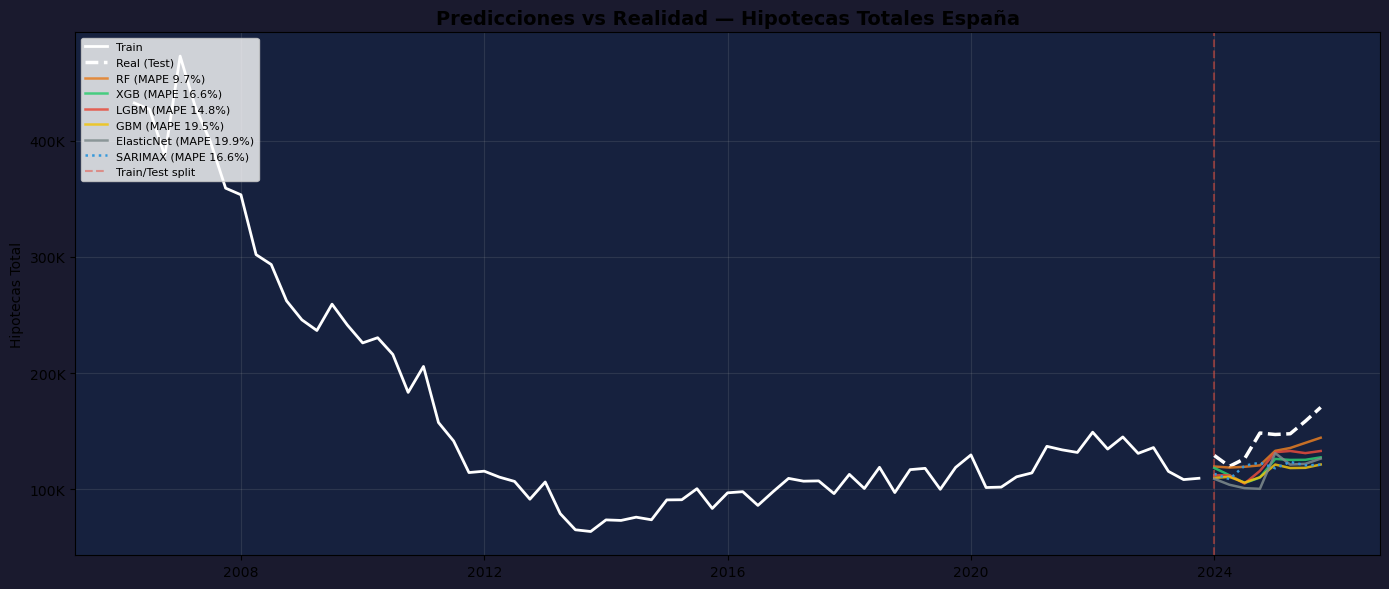

In [28]:
import matplotlib.ticker as mtick
# ── 8.1 Predicciones vs Realidad — Nacional ──
fig, ax = plt.subplots(figsize=(14,6))
fig.patch.set_facecolor('#1a1a2e')
ax.set_facecolor('#16213e')

# Train
nac_train = df_train.groupby('Trimestre')['Hipotecas_Total'].sum()
ax.plot(nac_train.index, nac_train.values, color='white', lw=2, label='Train')

# Real test
nac_test_real = df_test.groupby('Trimestre')['Hipotecas_Total'].sum()
ax.plot(nac_test_real.index, nac_test_real.values, color='white', lw=2.5, ls='--', label='Real (Test)')

# ML predictions
for name in ['RF','XGB','LGBM','GBM','ElasticNet']:
    nac_p = results[name]['nac_pred']
    mape = mean_absolute_percentage_error(results[name]['nac_real'], nac_p)*100
    ax.plot(nac_p.index, nac_p.values, color=COL.get(name,'gray'), lw=1.8, alpha=0.85,
            label=f'{name} (MAPE {mape:.1f}%)')

# SARIMAX
mape_s2 = mean_absolute_percentage_error(sarimax_real_nac, sarimax_pred_nac)*100
ax.plot(sarimax_pred_nac.index, sarimax_pred_nac.values, color=COL['SARIMAX'],
        lw=1.8, ls=':', label=f'SARIMAX (MAPE {mape_s2:.1f}%)')

ax.axvline(test_start, color='#e74c3c', ls='--', alpha=0.5, label='Train/Test split')
ax.set_title('Predicciones vs Realidad — Hipotecas Totales España', fontsize=14, fontweight='bold')
ax.set_ylabel('Hipotecas Total')
ax.legend(fontsize=8, loc='upper left')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,_: f'{x/1000:.0f}K'))
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()
COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}


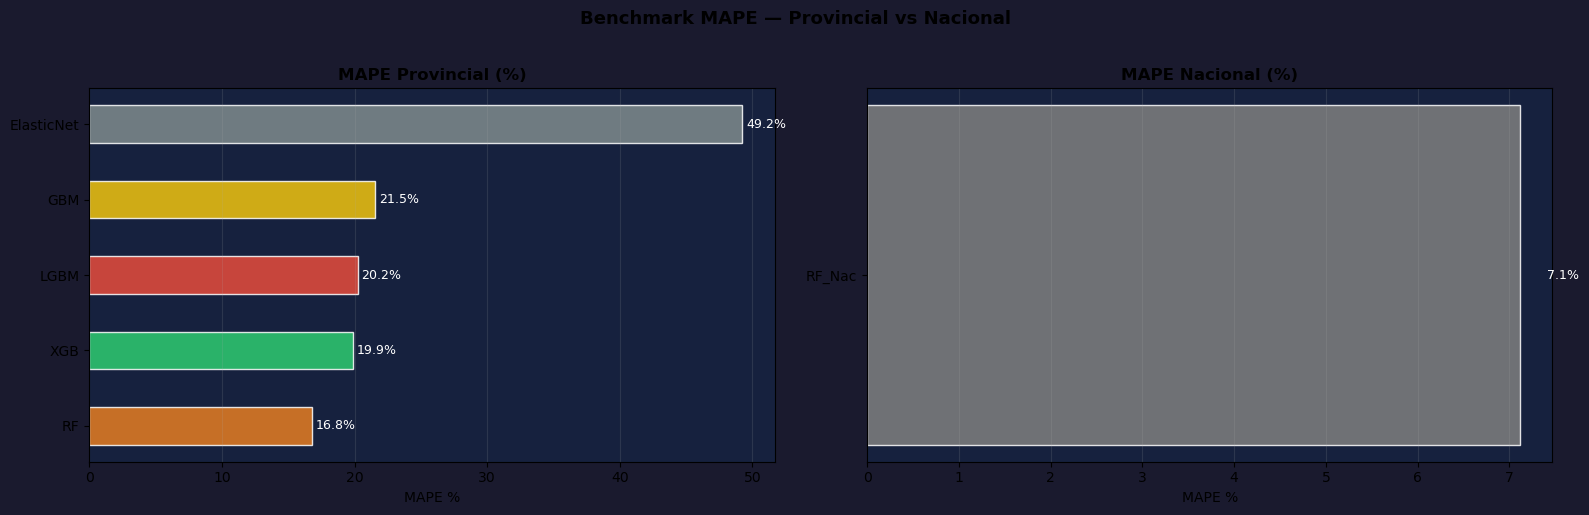

In [29]:

COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}
# ── 8.2 Barplot MAPE comparativo ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor('#1a1a2e')
for ax in axes: ax.set_facecolor('#16213e')

# Provincial
df_m = df_metrics.sort_values('MAPE%')
bars = axes[0].barh(df_m['Modelo'], df_m['MAPE%'],
    color=[COL.get(m,'gray') for m in df_m['Modelo']], alpha=0.85, edgecolor='white', height=0.5)
for b,v in zip(bars, df_m['MAPE%']): axes[0].text(b.get_width()+0.3, b.get_y()+b.get_height()/2, f'{v:.1f}%', va='center', fontsize=9, color='white')
axes[0].set_title('MAPE Provincial (%)', fontweight='bold')
axes[0].set_xlabel('MAPE %')
axes[0].grid(axis='x', alpha=0.15)

# Nacional
df_mn = df_nac_metrics.sort_values('MAPE%')
bars2 = axes[1].barh(df_mn['Modelo'], df_mn['MAPE%'],
    color=[COL.get(m,'gray') for m in df_mn['Modelo']], alpha=0.85, edgecolor='white', height=0.5)
for b,v in zip(bars2, df_mn['MAPE%']): axes[1].text(b.get_width()+0.3, b.get_y()+b.get_height()/2, f'{v:.1f}%', va='center', fontsize=9, color='white')
axes[1].set_title('MAPE Nacional (%)', fontweight='bold')
axes[1].set_xlabel('MAPE %')
axes[1].grid(axis='x', alpha=0.15)
plt.suptitle('Benchmark MAPE — Provincial vs Nacional', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

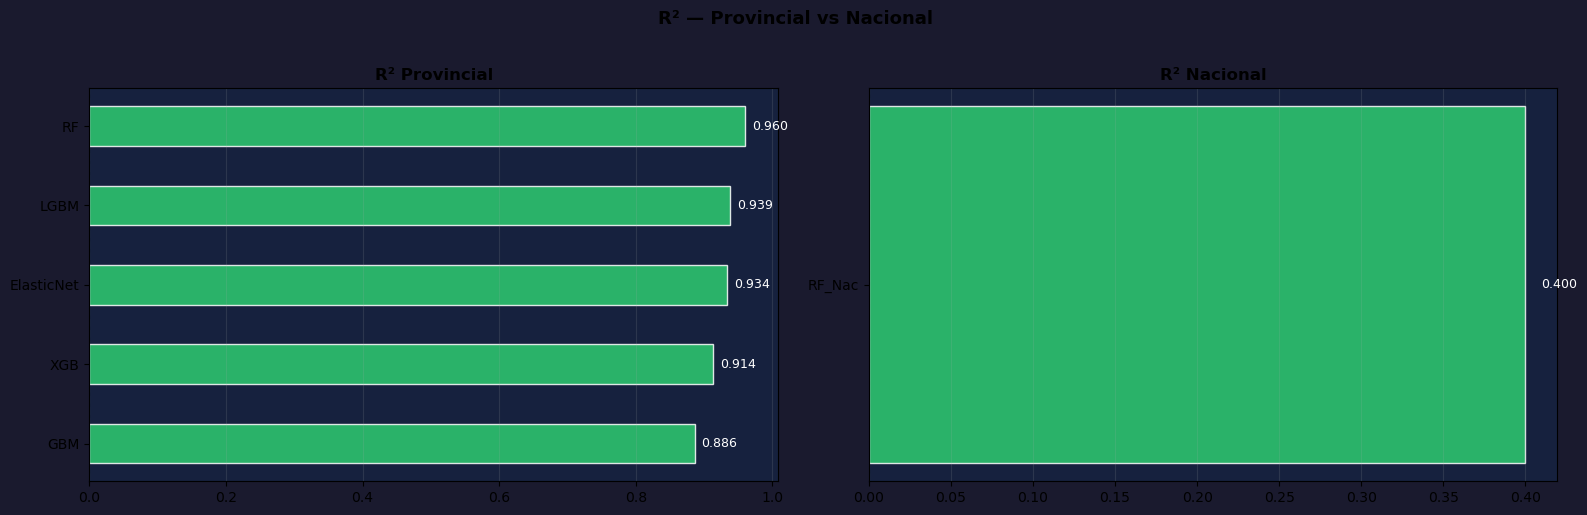

In [30]:
# ── 8.3 R² comparativo ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor('#1a1a2e')
for ax in axes: ax.set_facecolor('#16213e')

# Provincial R²
df_r = df_metrics.sort_values('R²', ascending=True)
colors_r = ['#2ecc71' if v>0 else '#e74c3c' for v in df_r['R²']]
axes[0].barh(df_r['Modelo'], df_r['R²'], color=colors_r, alpha=0.85, edgecolor='white', height=0.5)
for i,(m,v) in enumerate(zip(df_r['Modelo'],df_r['R²'])):
    axes[0].text(v+0.01 if v>0 else v-0.05, i, f'{v:.3f}', va='center', fontsize=9, color='white')
axes[0].axvline(0, color='white', ls='--', alpha=0.3)
axes[0].set_title('R² Provincial', fontweight='bold')
axes[0].grid(axis='x', alpha=0.15)

# Nacional R²
df_rn = df_nac_metrics.sort_values('R2' if 'R2' in df_nac_metrics.columns else 'R²', ascending=True)
colors_rn = ['#2ecc71' if v>0 else '#e74c3c' for v in df_rn['R²']]
axes[1].barh(df_rn['Modelo'], df_rn['R²'], color=colors_rn, alpha=0.85, edgecolor='white', height=0.5)
for i,(m,v) in enumerate(zip(df_rn['Modelo'],df_rn['R²'])):
    axes[1].text(v+0.01 if v>0 else v-0.05, i, f'{v:.3f}', va='center', fontsize=9, color='white')
axes[1].axvline(0, color='white', ls='--', alpha=0.3)
axes[1].set_title('R² Nacional', fontweight='bold')
axes[1].grid(axis='x', alpha=0.15)
plt.suptitle('R² — Provincial vs Nacional', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

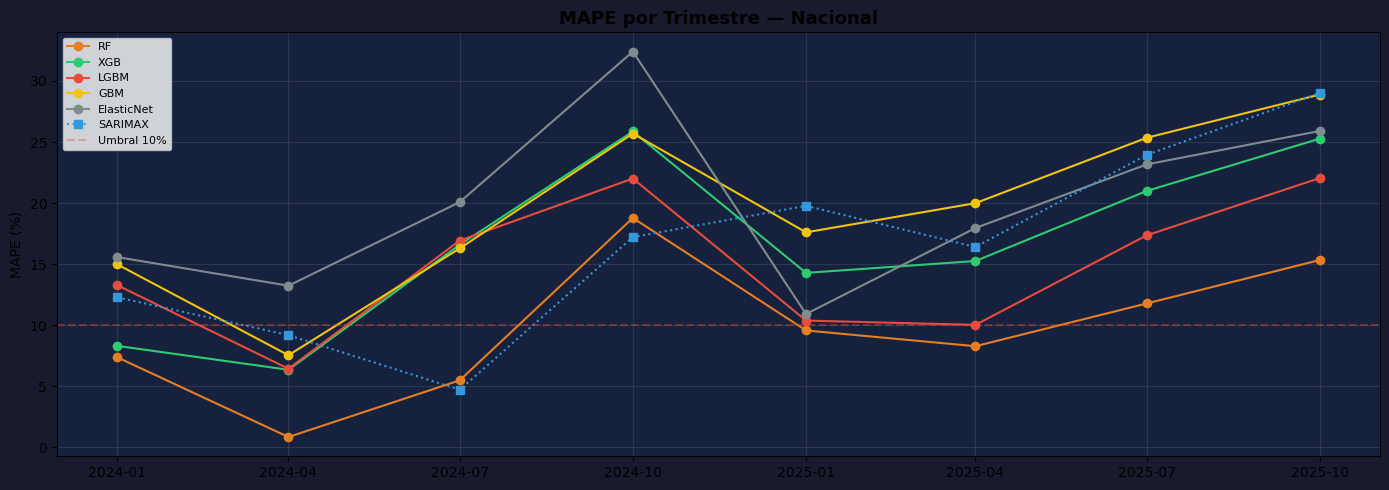

In [31]:

COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}
# ── 8.4 MAPE por Trimestre — Nacional ──
fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor('#1a1a2e')
ax.set_facecolor('#16213e')

for name in ['RF','XGB','LGBM','GBM','ElasticNet']:
    nr = results[name]['nac_real']
    np_ = results[name]['nac_pred']
    mape_t = np.abs((nr - np_) / nr) * 100
    ax.plot(mape_t.index, mape_t.values, marker='o', color=COL.get(name,'gray'), label=name, lw=1.5)

# SARIMAX
mape_t_s = np.abs((sarimax_real_nac - sarimax_pred_nac) / sarimax_real_nac) * 100
ax.plot(mape_t_s.index, mape_t_s.values, marker='s', color=COL['SARIMAX'], label='SARIMAX', lw=1.5, ls=':')

ax.axhline(10, color='#e74c3c', ls='--', alpha=0.4, label='Umbral 10%')
ax.set_title('MAPE por Trimestre — Nacional', fontsize=13, fontweight='bold')
ax.set_ylabel('MAPE (%)')
ax.legend(fontsize=8)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

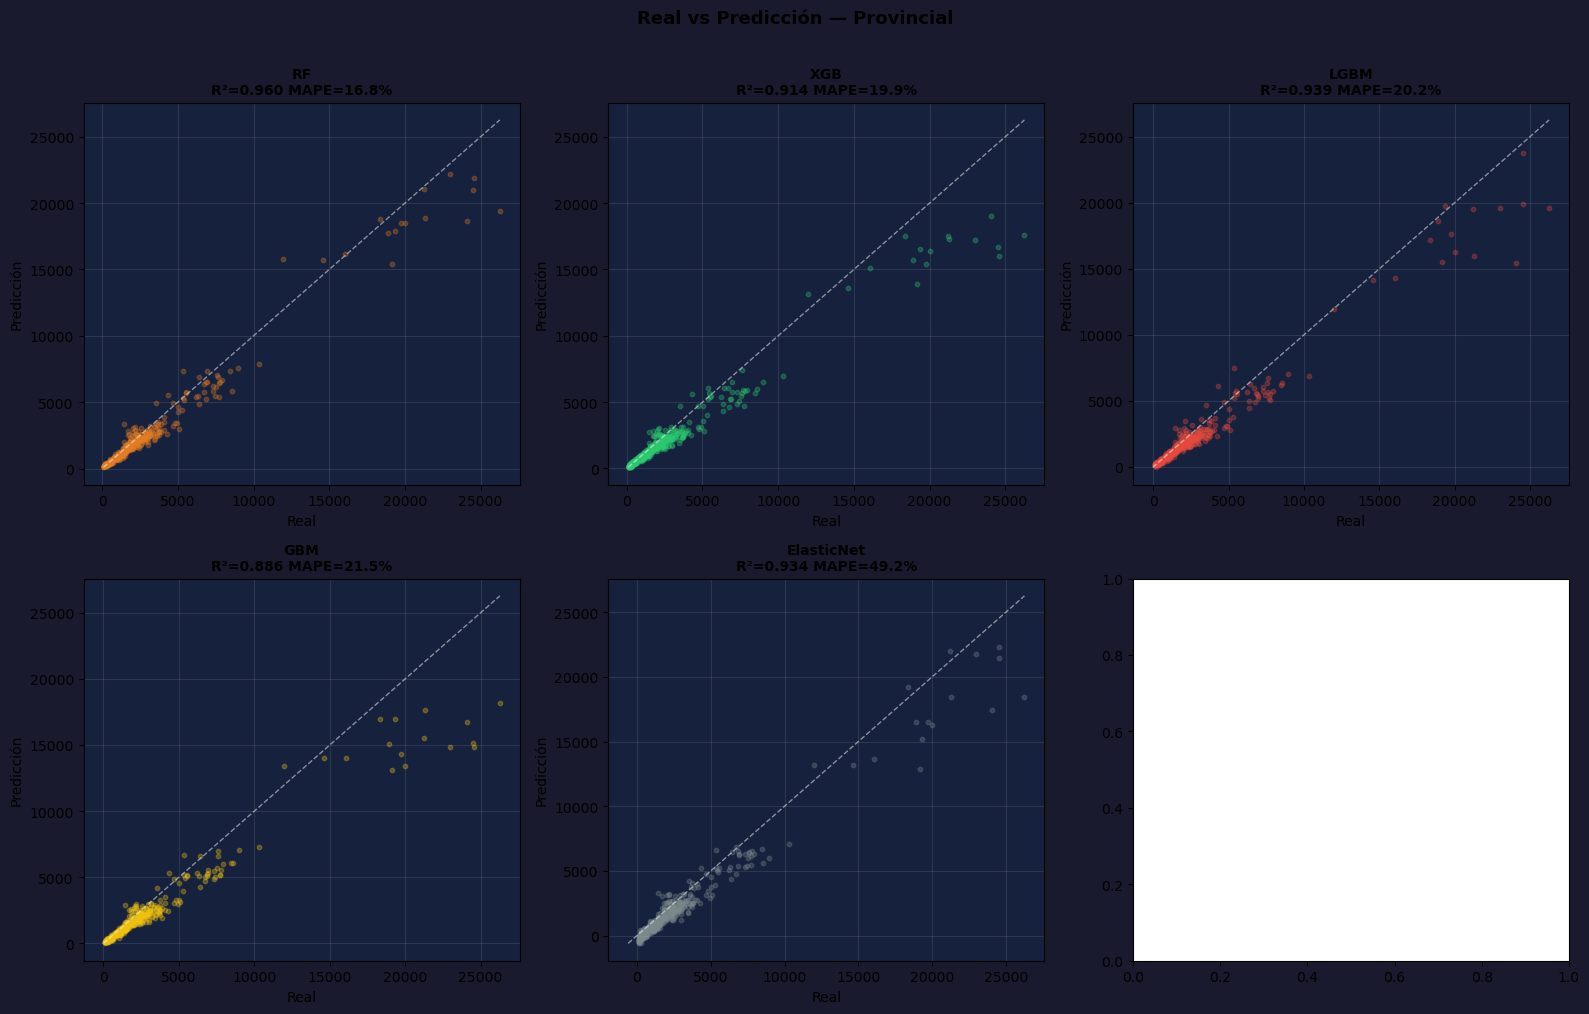

In [32]:

COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}
# ── 8.5 Real vs Predicción scatter ──
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.patch.set_facecolor('#1a1a2e')
axes = axes.flatten()

for i, name in enumerate(['RF','XGB','LGBM','GBM','ElasticNet']):
    ax = axes[i]
    ax.set_facecolor('#16213e')
    pred = results[name]['pred']
    ax.scatter(y_te, pred, alpha=0.3, s=10, color=COL.get(name,'gray'))
    lims = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
    ax.plot(lims, lims, 'w--', alpha=0.5, lw=1)
    r2 = r2_score(y_te, pred)
    mape = mean_absolute_percentage_error(y_te, pred)*100
    ax.set_title(f'{name}\nR²={r2:.3f} MAPE={mape:.1f}%', fontsize=10, fontweight='bold')
    ax.set_xlabel('Real'); ax.set_ylabel('Predicción')
    ax.grid(alpha=0.15)
plt.suptitle('Real vs Predicción — Provincial', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 9. Feature Importance — Mejor Modelo

Analizando importancia de features para: RF


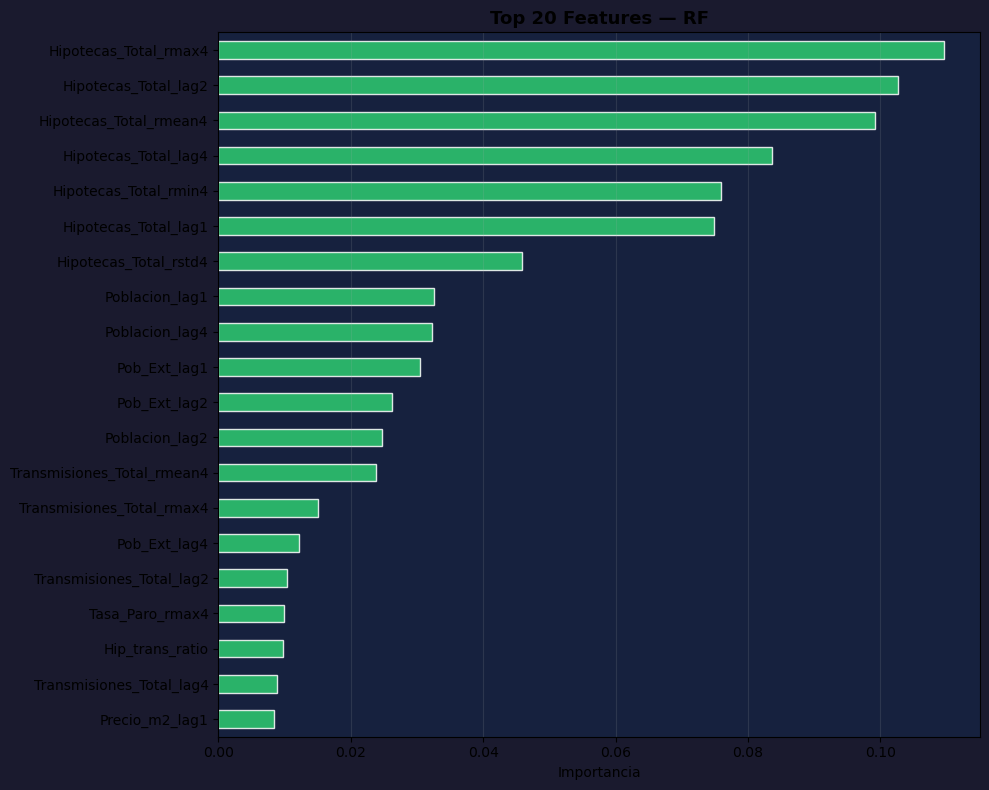

In [33]:
# Feature importance del mejor modelo
best_name = df_metrics.iloc[0]['Modelo']
best_model = results[best_name]['model']
print(f"Analizando importancia de features para: {best_name}")

if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=features_ml).sort_values(ascending=True)
elif hasattr(best_model, 'coef_'):
    imp = pd.Series(np.abs(best_model.coef_), index=features_ml).sort_values(ascending=True)
else:
    imp = pd.Series(dtype=float)

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('#1a1a2e')
ax.set_facecolor('#16213e')
imp.tail(20).plot(kind='barh', ax=ax, color='#2ecc71', alpha=0.85, edgecolor='white')
ax.set_title(f'Top 20 Features — {best_name}', fontsize=13, fontweight='bold')
ax.set_xlabel('Importancia')
ax.grid(axis='x', alpha=0.15)
plt.tight_layout()
plt.show()

## 10. Distribución de Residuos y Precisión Direccional

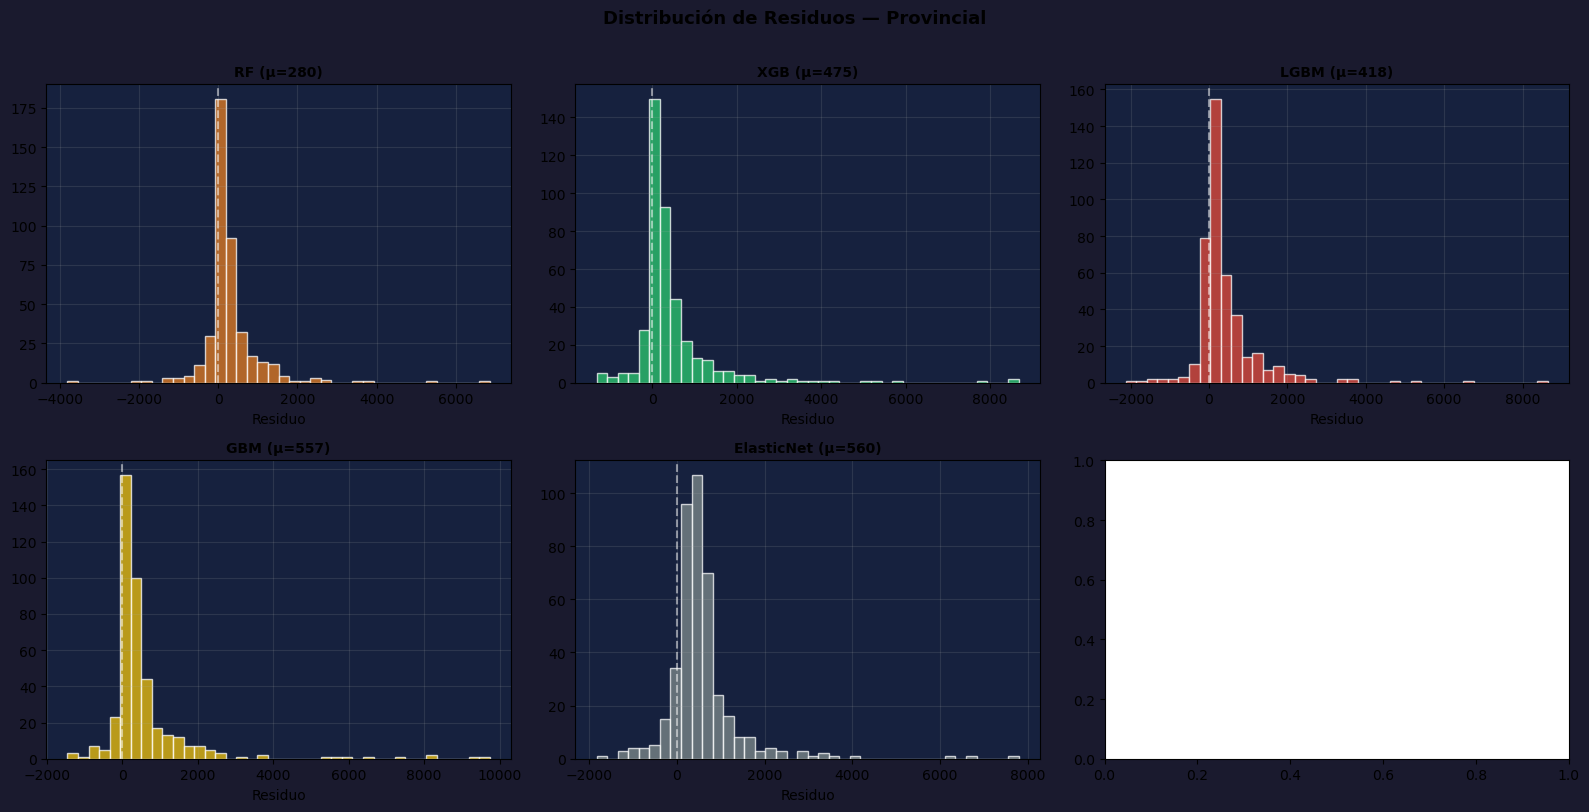

In [34]:

COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}
# ── 10.1 Distribución de residuos ──
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.patch.set_facecolor('#1a1a2e')
axes = axes.flatten()

for i, name in enumerate(['RF','XGB','LGBM','GBM','ElasticNet']):
    ax = axes[i]; ax.set_facecolor('#16213e')
    resid = y_te.values - results[name]['pred']
    ax.hist(resid, bins=40, color=COL.get(name,'gray'), alpha=0.75, edgecolor='white')
    ax.axvline(0, color='white', ls='--', alpha=0.5)
    ax.set_title(f'{name} (μ={np.mean(resid):.0f})', fontsize=10, fontweight='bold')
    ax.set_xlabel('Residuo')
    ax.grid(alpha=0.15)
plt.suptitle('Distribución de Residuos — Provincial', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

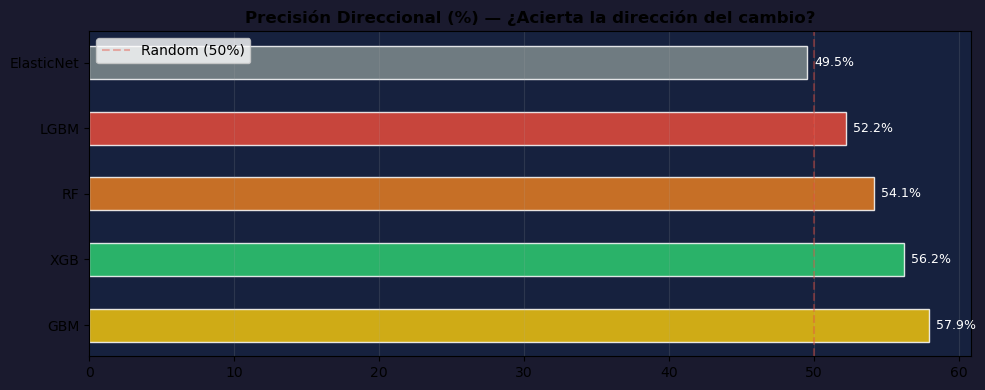

In [35]:

COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}
# ── 10.2 Precisión Direccional ──
# ¿El modelo acierta la dirección del cambio?
def dir_accuracy(real, pred, trimestres, provincias):
    df_tmp = pd.DataFrame({'real':real.values,'pred':pred,'trim':trimestres.values,'prov':provincias.values})
    df_tmp = df_tmp.sort_values(['prov','trim'])
    df_tmp['real_dir'] = df_tmp.groupby('prov')['real'].diff().apply(lambda x: 1 if x>0 else 0)
    df_tmp['pred_dir'] = df_tmp.groupby('prov')['pred'].diff().apply(lambda x: 1 if x>0 else 0)
    df_tmp = df_tmp.dropna()
    if len(df_tmp)==0: return 50.0
    return (df_tmp['real_dir']==df_tmp['pred_dir']).mean()*100

dir_rows = []
for name in ['RF','XGB','LGBM','GBM','ElasticNet']:
    acc = dir_accuracy(y_te, results[name]['pred'], df_test['Trimestre'], df_test['Provincia'])
    dir_rows.append({'Modelo':name, 'Precisión_Direccional_%':round(acc,1)})
df_dir = pd.DataFrame(dir_rows).sort_values('Precisión_Direccional_%', ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#1a1a2e'); ax.set_facecolor('#16213e')
bars = ax.barh(df_dir['Modelo'], df_dir['Precisión_Direccional_%'],
    color=[COL.get(m,'gray') for m in df_dir['Modelo']], alpha=0.85, edgecolor='white', height=0.5)
for b,v in zip(bars, df_dir['Precisión_Direccional_%']):
    ax.text(b.get_width()+0.5, b.get_y()+b.get_height()/2, f'{v:.1f}%', va='center', fontsize=9, color='white')
ax.axvline(50, color='#e74c3c', ls='--', alpha=0.4, label='Random (50%)')
ax.set_title('Precisión Direccional (%) — ¿Acierta la dirección del cambio?', fontweight='bold')
ax.legend(); ax.grid(axis='x', alpha=0.15)
plt.tight_layout(); plt.show()

## 12. Radar Multi-Métrica

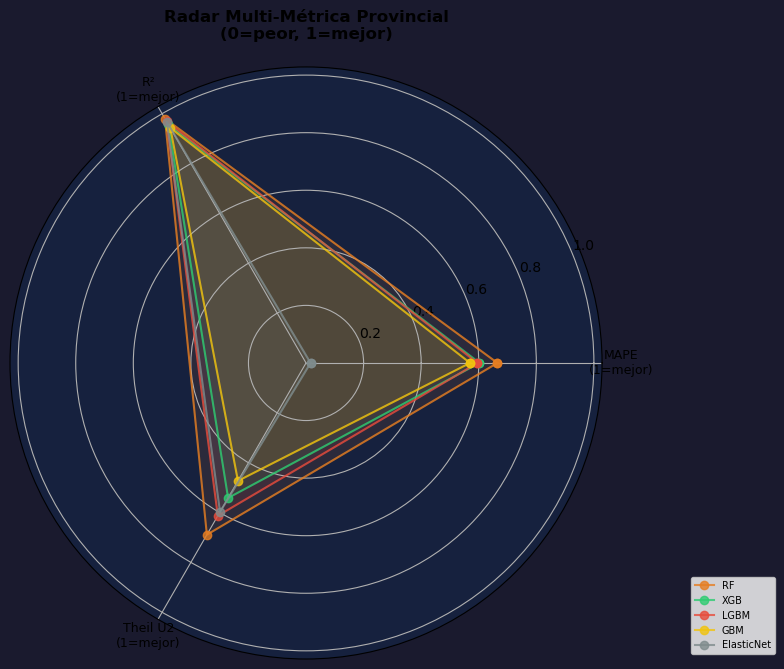

In [36]:

COL = {'RF':'#e67e22', 'XGB':'#2ecc71', 'LGBM':'#e74c3c', 'GBM':'#f1c40f', 'ElasticNet':'#7f8c8d', 'SARIMAX':'#3498db'}
# Radar chart
from matplotlib.patches import FancyBboxPatch
metrics_for_radar = ['MAPE%','R²','Theil_U2']
model_names = list(df_metrics['Modelo'].values)

fig, ax = plt.subplots(figsize=(8,8), subplot_kw=dict(polar=True))
fig.patch.set_facecolor('#1a1a2e')
ax.set_facecolor('#16213e')

# Normalize metrics to 0-1 (lower is better for MAPE, Theil; higher for R²)
norm_data = {}
for name in model_names:
    row = df_metrics[df_metrics['Modelo']==name].iloc[0]
    mape_norm = 1 - min(row['MAPE%']/50, 1)  # Lower is better
    r2_norm = max(0, min((row['R²']+1)/2, 1))  # Higher is better
    theil_norm = 1 - min(row['Theil_U2']/2, 1) if not np.isnan(row['Theil_U2']) else 0.5
    norm_data[name] = [mape_norm, r2_norm, theil_norm]

labels = ['MAPE\n(1=mejor)', 'R²\n(1=mejor)', 'Theil U2\n(1=mejor)']
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

for name in model_names:
    vals = norm_data[name] + norm_data[name][:1]
    ax.plot(angles, vals, 'o-', color=COL.get(name,'gray'), label=name, lw=1.5, alpha=0.8)
    ax.fill(angles, vals, color=COL.get(name,'gray'), alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=9)
ax.set_title('Radar Multi-Métrica Provincial\n(0=peor, 1=mejor)', fontsize=12, fontweight='bold', pad=20)
ax.legend(loc='lower right', fontsize=7, bbox_to_anchor=(1.3, 0))
plt.tight_layout(); plt.show()

## 13. Análisis por Provincia — Top 10 con Mayor/Menor Error

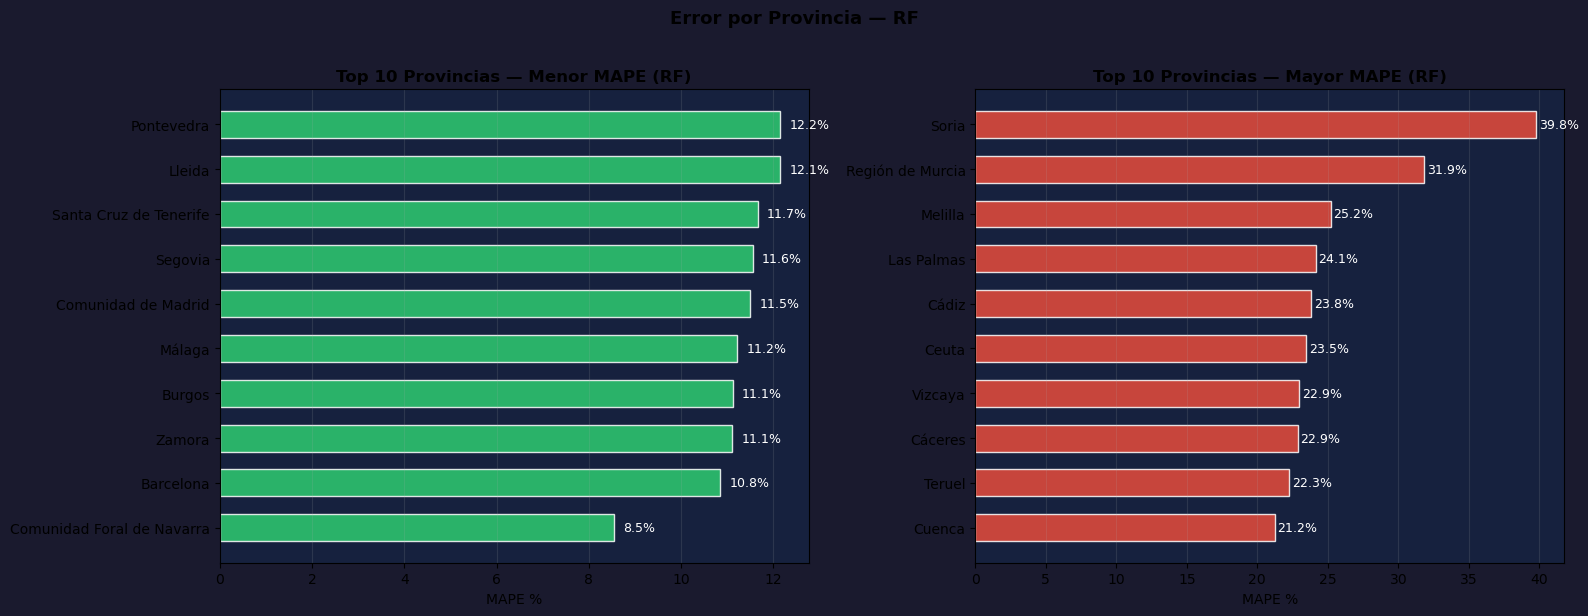

\nMAPE medio por provincia: 16.75%
Mediana: 15.60%
Rango: 8.54% — 39.77%


In [37]:
# MAPE por provincia para el mejor modelo
best_name = df_metrics.iloc[0]['Modelo']
pred_best = results[best_name]['pred']
df_prov_err = df_test[['Provincia','Hipotecas_Total']].copy()
df_prov_err['pred'] = pred_best
df_prov_err['ape'] = np.abs((df_prov_err['Hipotecas_Total'] - df_prov_err['pred']) / df_prov_err['Hipotecas_Total'].clip(lower=1)) * 100

mape_by_prov = df_prov_err.groupby('Provincia')['ape'].mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('#1a1a2e')
for ax in axes: ax.set_facecolor('#16213e')

# Top 10 mejor
top10 = mape_by_prov.head(10)
axes[0].barh(top10.index, top10.values, color='#2ecc71', alpha=0.85, edgecolor='white', height=0.6)
for i,(p,v) in enumerate(zip(top10.index, top10.values)):
    axes[0].text(v+0.2, i, f'{v:.1f}%', va='center', fontsize=9, color='white')
axes[0].set_title(f'Top 10 Provincias — Menor MAPE ({best_name})', fontweight='bold')
axes[0].set_xlabel('MAPE %')
axes[0].grid(axis='x', alpha=0.15)

# Top 10 peor
bot10 = mape_by_prov.tail(10)
axes[1].barh(bot10.index, bot10.values, color='#e74c3c', alpha=0.85, edgecolor='white', height=0.6)
for i,(p,v) in enumerate(zip(bot10.index, bot10.values)):
    axes[1].text(v+0.2, i, f'{v:.1f}%', va='center', fontsize=9, color='white')
axes[1].set_title(f'Top 10 Provincias — Mayor MAPE ({best_name})', fontweight='bold')
axes[1].set_xlabel('MAPE %')
axes[1].grid(axis='x', alpha=0.15)
plt.suptitle(f'Error por Provincia — {best_name}', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

print(f"\\nMAPE medio por provincia: {mape_by_prov.mean():.2f}%")
print(f"Mediana: {mape_by_prov.median():.2f}%")
print(f"Rango: {mape_by_prov.min():.2f}% — {mape_by_prov.max():.2f}%")

## 14. Resumen y Conclusiones

In [48]:
# ── Resumen final ──
print("="*70)
print("RESUMEN FINAL — ANÁLISIS DEFINITIVO")
print("="*70)
print(f"\nPROVINCIAL (52 provincias, 8 trimestres test)")
print(df_metrics.to_string(index=False))
print(f"\nMejor provincial: {df_metrics.iloc[0]['Modelo']} (MAPE={df_metrics.iloc[0]['MAPE%']:.2f}%)")
print(f"\nNACIONAL (agregado)")
print(df_nac_metrics.to_string(index=False))
print(f"\nMejor nacional: {df_nac_metrics.iloc[0]['Modelo']} (MAPE={df_nac_metrics.iloc[0]['MAPE%']:.2f}%)")
print(f"\nFeatures engineering: {len(features_ml)} features")
print(f"   Mejoras clave: lags múltiples, rolling stats, YoY, interacciones,")
print(f"   encoding provincial, variables temporales")
print("\n" + "="*70)

RESUMEN FINAL — ANÁLISIS DEFINITIVO

PROVINCIAL (52 provincias, 8 trimestres test)
    Modelo  MAPE%   RMSE     R²   MAE  Theil_U2
        RF  16.75  793.0 0.9603 421.0     0.622
       XGB  19.87 1169.0 0.9138 571.0     0.917
      LGBM  20.22  987.0 0.9386 520.0     0.774
       GBM  21.51 1344.0 0.8862 636.0     1.054
ElasticNet  49.21 1027.0 0.9336 657.0     0.805

Mejor provincial: RF (MAPE=16.75%)

NACIONAL (agregado)
Modelo  MAPE%    RMSE     R²     MAE
RF_Nac   7.11 12513.0 0.3995 10328.0

Mejor nacional: RF_Nac (MAPE=7.11%)

Features engineering: 94 features
   Mejoras clave: lags múltiples, rolling stats, YoY, interacciones,
   encoding provincial, variables temporales



## 15. Simulador de Demanda Hipotecaria Provincial

Selecciona una provincia en la variable `PROVINCIA_OBJETIVO` para obtener su prediccion detallada con metricas individuales, comparativa con la media nacional y visualizacion completa.

  SIMULADOR PROVINCIAL — COMUNIDAD DE MADRID
  Modelo           : RF (Random Forest — mejor modelo provincial)
  Periodo test     : 2024-01-01 -> 2025-10-01
  Trimestres test  : 8

  MAPE             : 11.50%
  RMSE             : 3,583 hipotecas
  R2               : -1.3363
  MAE              : 2,791 hipotecas
  Dir. Accuracy    : 28.6%

  MAPE medio (52p) : 16.75%
  Posicion relativa: MEJOR que la media (-5.25pp) — Ranking #6/52

  Trimestre            Real   Predicho    Error%  OK?
  ----------------------------------------------------
  2024-01-01         24,072     18,648    -22.5%   !!
  2024-04-01         18,362     18,789      2.3%   OK
  2024-07-01         21,304     18,865    -11.4%    ~
  2024-10-01         26,269     19,418    -26.1%   !!
  2025-01-01         21,246     21,055     -0.9%   OK
  2025-04-01         24,509     20,970    -14.4%    ~
  2025-07-01         22,994     22,188     -3.5%   OK
  2025-10-01         24,566     21,915    -10.8%    ~


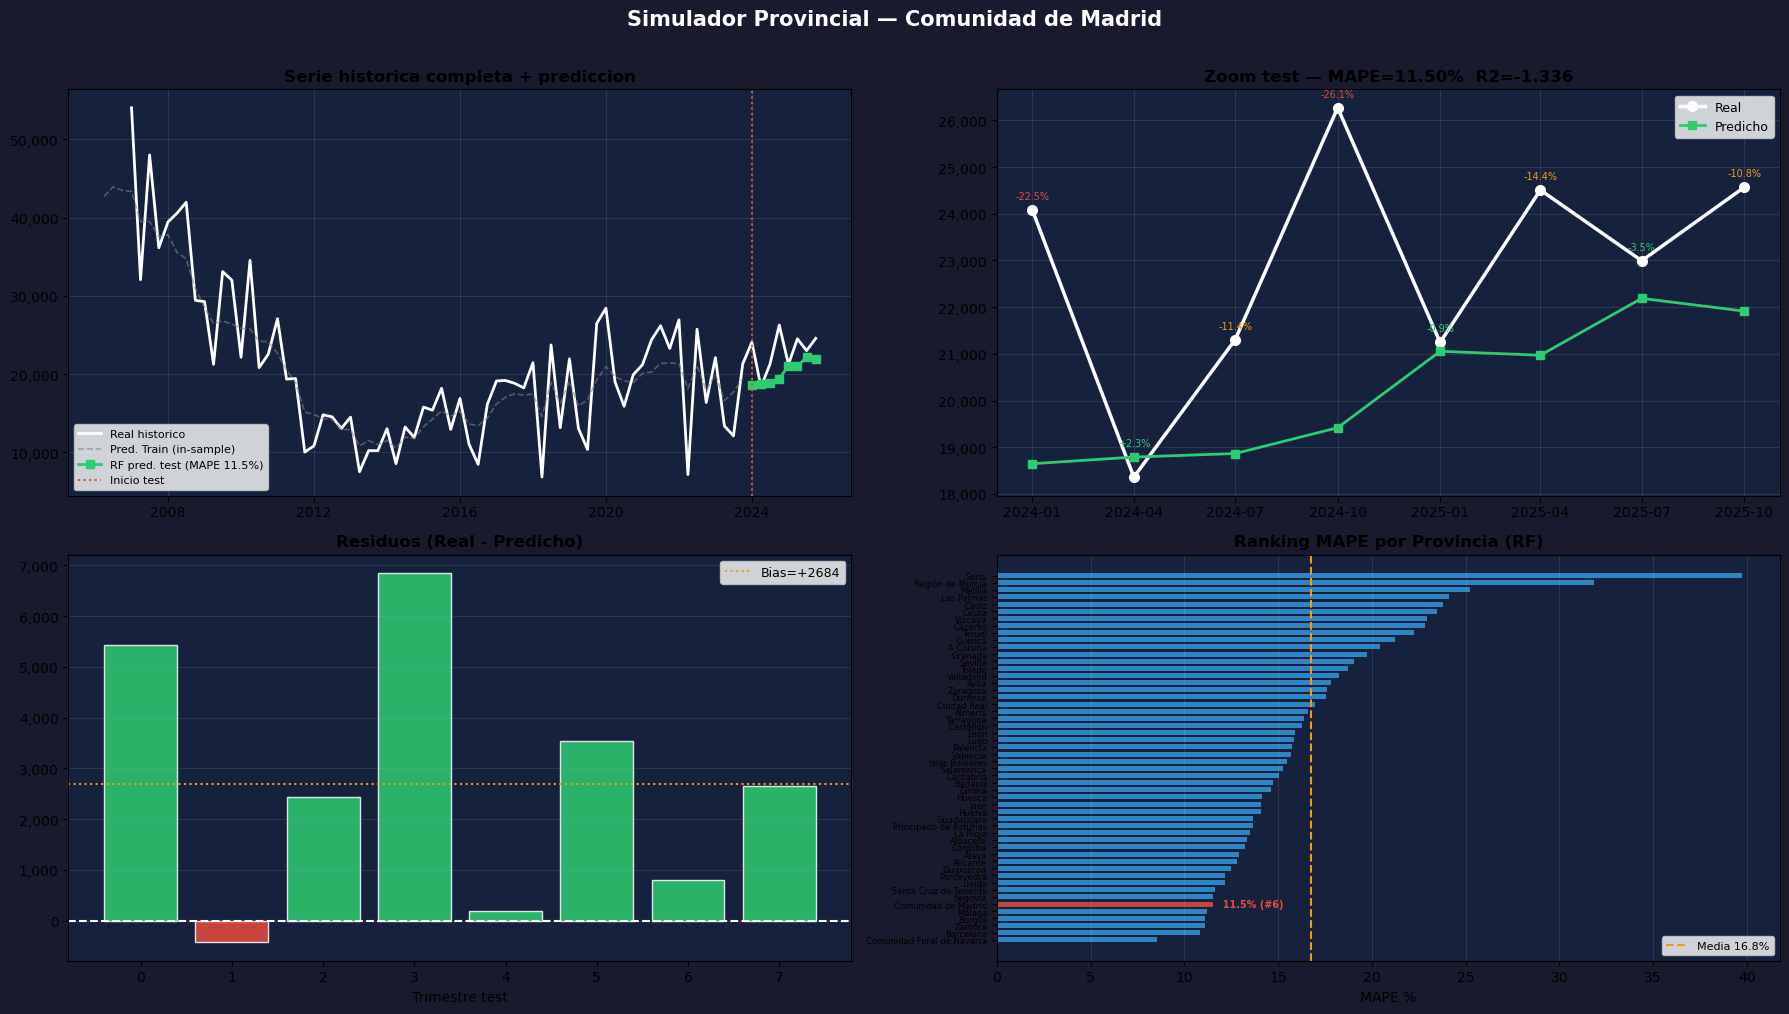

In [39]:
# =====================================================================
# SIMULADOR PROVINCIAL — Cambia PROVINCIA_OBJETIVO para ver
# la prediccion de cualquier provincia espanola
# =====================================================================

PROVINCIA_OBJETIVO = 'Comunidad de Madrid'   # <-- CAMBIA AQUI

provincias_disponibles = sorted(df['Provincia'].unique())
if PROVINCIA_OBJETIVO not in provincias_disponibles:
    print(f"Provincia '{PROVINCIA_OBJETIVO}' no encontrada.")
    print("Disponibles:", provincias_disponibles)
else:
    df_prov_train = df_train[df_train['Provincia'] == PROVINCIA_OBJETIVO].copy()
    df_prov_test  = df_test [df_test ['Provincia'] == PROVINCIA_OBJETIVO].copy()
    df_prov_hist  = df[df['Provincia'] == PROVINCIA_OBJETIVO].sort_values('Trimestre').copy()

    best_model  = results['RF']['model']
    pred_train  = best_model.predict(df_prov_train[features_ml])
    pred_test   = best_model.predict(df_prov_test [features_ml])
    real_test   = df_prov_test['Hipotecas_Total'].values

    mape_p  = mean_absolute_percentage_error(real_test, pred_test)*100
    rmse_p  = float(np.sqrt(mean_squared_error(real_test, pred_test)))
    r2_p    = float(r2_score(real_test, pred_test))
    mae_p   = float(np.mean(np.abs(real_test - pred_test)))
    dir_acc = float(np.mean(np.sign(np.diff(real_test)) == np.sign(np.diff(pred_test)))) * 100

    # MAPE de todas las provincias para posicion relativa
    all_mapes_sim = []
    prov_mapes_dict = {}
    for prov in provincias_disponibles:
        mp_te = df_test[df_test['Provincia']==prov]['Hipotecas_Total'].values
        mask  = df_test['Provincia']==prov
        mp_pr = results['RF']['pred'][mask]
        if len(mp_te) > 0:
            m = float(mean_absolute_percentage_error(mp_te, mp_pr)*100)
            all_mapes_sim.append(m)
            prov_mapes_dict[prov] = m
    mape_medio_sim = float(np.mean(all_mapes_sim))
    ranking = sorted(prov_mapes_dict.items(), key=lambda x: x[1])
    rank_pos = [p for p,_ in ranking].index(PROVINCIA_OBJETIVO) + 1

    print("=" * 64)
    print(f"  SIMULADOR PROVINCIAL — {PROVINCIA_OBJETIVO.upper()}")
    print("=" * 64)
    print(f"  Modelo           : RF (Random Forest — mejor modelo provincial)")
    print(f"  Periodo test     : {df_prov_test['Trimestre'].min().date()} -> {df_prov_test['Trimestre'].max().date()}")
    print(f"  Trimestres test  : {len(df_prov_test)}")
    print()
    print(f"  MAPE             : {mape_p:.2f}%")
    print(f"  RMSE             : {rmse_p:,.0f} hipotecas")
    print(f"  R2               : {r2_p:.4f}")
    print(f"  MAE              : {mae_p:,.0f} hipotecas")
    print(f"  Dir. Accuracy    : {dir_acc:.1f}%")
    print()
    print(f"  MAPE medio (52p) : {mape_medio_sim:.2f}%")
    vs = "MEJOR que la media" if mape_p < mape_medio_sim else "PEOR que la media"
    print(f"  Posicion relativa: {vs} ({mape_p - mape_medio_sim:+.2f}pp) — Ranking #{rank_pos}/52")
    print()
    print(f"  {'Trimestre':<14} {'Real':>10} {'Predicho':>10} {'Error%':>9} {'OK?':>4}")
    print("  " + "-" * 52)
    for trim, r, p in zip(df_prov_test['Trimestre'].values, real_test, pred_test):
        err = (p - r) / r * 100
        flag = "OK" if abs(err) < 10 else ("~" if abs(err) < 20 else "!!")
        print(f"  {str(trim)[:10]:<14} {r:>10,.0f} {p:>10,.0f} {err:>8.1f}% {flag:>4}")
    print("=" * 64)

    # GRAFICOS
    import matplotlib.ticker as mtick
    fig, axes = plt.subplots(2, 2, figsize=(18, 10))
    fig.patch.set_facecolor('#1a1a2e')
    fig.suptitle(f'Simulador Provincial — {PROVINCIA_OBJETIVO}',
                 fontsize=15, fontweight='bold', color='white', y=1.01)
    for ax in axes.flat: ax.set_facecolor('#16213e')

    # A. Serie historica completa
    ax = axes[0, 0]
    ax.plot(df_prov_hist['Trimestre'], df_prov_hist['Hipotecas_Total'],
            'w-', lw=2, label='Real historico')
    ax.plot(df_prov_train['Trimestre'], pred_train,
            color='gray', lw=1.2, alpha=0.6, ls='--', label='Pred. Train (in-sample)')
    ax.plot(df_prov_test['Trimestre'], pred_test,
            's-', color='#2ecc71', lw=2, ms=6, label=f'RF pred. test (MAPE {mape_p:.1f}%)')
    ax.axvline(df_prov_test['Trimestre'].iloc[0], color='#e74c3c', ls=':', lw=1.5, label='Inicio test')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{int(x):,}'))
    ax.set_title('Serie historica completa + prediccion', fontweight='bold')
    ax.legend(fontsize=8); ax.grid(alpha=0.15)

    # B. Zoom test
    ax = axes[0, 1]
    ax.plot(df_prov_test['Trimestre'], real_test, 'w-o', lw=2.5, ms=7, label='Real')
    ax.plot(df_prov_test['Trimestre'], pred_test, 's-', color='#2ecc71', lw=2, ms=6, label='Predicho')
    for t, r, p in zip(df_prov_test['Trimestre'], real_test, pred_test):
        err = (p - r) / r * 100
        color = '#2ecc71' if abs(err) < 10 else ('#f39c12' if abs(err) < 20 else '#e74c3c')
        ax.annotate(f'{err:+.1f}%', (t, max(r, p)),
                    textcoords='offset points', xytext=(0, 8),
                    ha='center', fontsize=7, color=color)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{int(x):,}'))
    ax.set_title(f'Zoom test — MAPE={mape_p:.2f}%  R2={r2_p:.3f}', fontweight='bold')
    ax.legend(fontsize=9); ax.grid(alpha=0.15)

    # C. Residuos
    ax = axes[1, 0]
    resid = real_test - pred_test
    ax.bar(range(len(resid)), resid,
           color=['#2ecc71' if r >= 0 else '#e74c3c' for r in resid],
           edgecolor='white', alpha=0.85)
    ax.axhline(0, color='white', lw=1.5, ls='--')
    ax.axhline(float(np.mean(resid)), color='#f39c12', lw=1.5, ls=':',
               label=f'Bias={float(np.mean(resid)):+.0f}')
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,_: f'{int(x):,}'))
    ax.set_title('Residuos (Real - Predicho)', fontweight='bold')
    ax.set_xlabel('Trimestre test'); ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.15)

    # D. Ranking MAPE provincial
    ax = axes[1, 1]
    prov_sorted  = [p for p, _ in ranking]
    mapes_sorted = [m for _, m in ranking]
    bar_colors_r = ['#e74c3c' if p == PROVINCIA_OBJETIVO else '#3498db' for p in prov_sorted]
    ax.barh(prov_sorted, mapes_sorted, color=bar_colors_r, alpha=0.85, edgecolor='none', height=0.7)
    ax.axvline(mape_medio_sim, color='#f39c12', ls='--', lw=1.5, label=f'Media {mape_medio_sim:.1f}%')
    idx_p = prov_sorted.index(PROVINCIA_OBJETIVO)
    ax.text(prov_mapes_dict[PROVINCIA_OBJETIVO] + 0.2, idx_p,
            f'  {mape_p:.1f}% (#{rank_pos})', va='center', fontsize=7, color='#e74c3c', fontweight='bold')
    ax.set_title('Ranking MAPE por Provincia (RF)', fontweight='bold')
    ax.set_xlabel('MAPE %'); ax.legend(fontsize=8); ax.grid(axis='x', alpha=0.15)
    ax.tick_params(axis='y', labelsize=6)

    plt.tight_layout()
    plt.show()